# Presentation LLMs: mô hình ngôn ngữ lớn qua Qwen2.5-1.5B-Instruct
## Demo trên model thật cho 10 mục của đề: kiến trúc, token, nguyên lý học, huấn luyện, sinh văn bản, khả năng, RAG, hạn chế, thực nghiệm

- Nhóm: Muội, Phúc, Toàn, Thư. Môn Học sâu, UTH.
- Quy ước: mỗi cell code có markdown trước (mục đích, đầu vào, đầu ra), comment tiếng Việt, cell **Phân tích** sau output; tham số sinh luôn truyền tường minh; mọi số trong cell Phân tích lấy từ lần chạy chính thức `20261119_150356_normal` (Kaggle, GPU T4, 7.4 phút).

### Các phần của notebook
| Phần | Mục của đề | Demo chính | Cell | Đầu ra (`outputs/`) |
|:---:|:---|:---|:---:|:---|
| **0** | Setup | Thư viện, môi trường, tải model và dữ liệu, đếm tham số | 0.1–0.8 | `results/env.json` |
| **1** | 1. Giới thiệu | Một model, 4 tác vụ (hỏi đáp, tóm tắt, dịch, sinh mã), chỉ đổi prompt | 1.1–1.5 | `results/tasks_outputs.csv` |
| **2** | 2. Nền tảng kiến trúc | Thông số, causal mask, trọng số attention thật, top-5 token tiếp theo | 2.1–2.5 | `results/model_config.json`, `results/top5_next_tokens.csv`, `figures/causal_mask.png`, `figures/attention_qwen.png` |
| **3** | 3. Tokenization | Token và token ID của câu Việt, câu Anh; Qwen so với GPT-2; embedding | 3.1–3.5 | `results/token_counts.csv` |
| **4** | 4. Nguyên lý học | Cặp ngữ cảnh → token mục tiêu; cross-entropy từng token; perplexity | 4.1–4.5 | `results/per_token_loss.csv`, `results/loss_summary.csv` |
| **5** | 5. Các giai đoạn huấn luyện | Bản base và bản Instruct, cùng prompt | 5.1–5.4 | `results/base_vs_instruct.csv` |
| **6** | 6. Quá trình sinh văn bản | Sinh từng bước; greedy, temperature, top-p trên cùng prompt | 6.1–6.4 | `results/decoding_steps.csv`, `results/temperature_top_p.csv`, `results/decoding_samples.csv` |
| **7** | 7. Khả năng của LLM | Zero-shot và few-shot trên cùng tác vụ (UIT-VSFC, 2,999 câu test) | 7.1–7.5 | `results/icl_zero_shot.csv`, `results/icl_few_shot.csv` |
| **8** | 8. Thích nghi và bổ sung tri thức | Không RAG và có RAG trên cùng câu hỏi (UIT-ViQuAD 2.0) | 8.1–8.4 | `results/rag_results.csv` |
| **9** | 9. Hạn chế và đánh giá | Một câu trả lời sai và cách kiểm chứng; câu về thực thể không tồn tại | 9.1–9.3 | `results/hallucination_results.csv`, `results/hallucination_fictitious.csv` |
| **10** | 10. Demo và kết luận | Accuracy, McNemar, phân tích lỗi, bảng tổng hợp | 10.1–10.4 | `results/icl_metrics.json`, `figures/confusion_matrix_icl.png`, `results/error_analysis_sample.csv`, `results/summary_table.csv` |

Notebook **không train, không fine-tune**: mọi phần chỉ chạy suy luận trên model đã huấn luyện sẵn.

### Cách chạy
1. Kaggle → **File → Import Notebook** → chọn file này. Settings: **Accelerator: GPU T4**, **Internet: On**; gắn Dataset chứa `data/tasks_prompts.json` và `data/base_vs_instruct.json`.
2. Cell 0.1: `SMOKE = True` để chạy thử ít mẫu (khoảng 2 phút); `SMOKE = False` để chạy chính thức (khoảng 7 phút).
3. **Save Version → Save & Run All**. Kết quả ghi vào `outputs/` (smoke run ghi vào `outputs/_smoke/`, không đè kết quả thật).

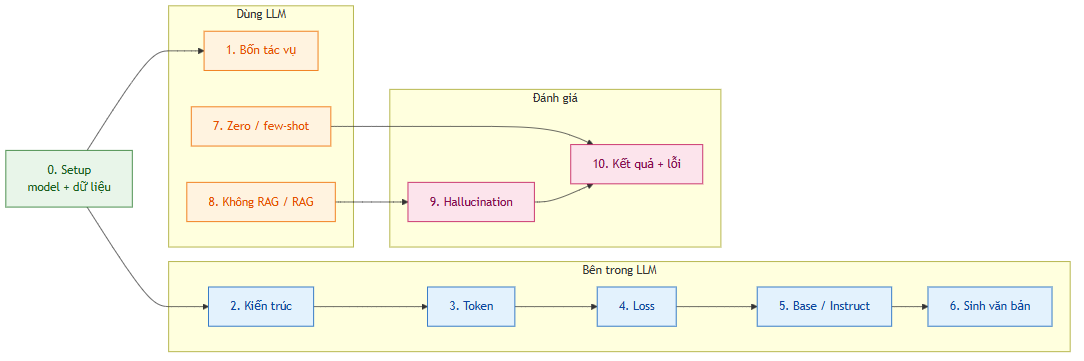


### Nguồn model và dữ liệu
**Model chính: `Qwen/Qwen2.5-1.5B-Instruct`**
- **Nơi lấy**: https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct, tải bằng `from_pretrained` (cell 0.4), revision `989aa7980e4cf806f80c7fef2b1adb7bc71aa306`. Công khai, không cần token.
- **Kích thước**: 1,543,714,304 tham số (đếm bằng code ở cell 0.5); float16 khoảng 3.1 GB.
- **Kiến trúc**: Transformer decoder-only, 28 block, hidden 1,536, GQA 12 head Q / 2 head KV, FFN SwiGLU 8,960, RMSNorm, RoPE, từ điển 151,936, ngữ cảnh tối đa 32,768 token.
- **Huấn luyện (theo báo cáo kỹ thuật)**: pretraining trên 18 nghìn tỉ token; post-training gồm SFT (hơn 1 triệu mẫu), DPO (khoảng 150 nghìn cặp) và RL trực tuyến GRPO.
- **Vì sao chọn**: đủ nhỏ để chạy trên một GPU T4 miễn phí của Kaggle, hỗ trợ tiếng Việt, có cả bản base cùng kiến trúc để so ở mục 5.
- **Giấy phép**: Apache-2.0. **Trích dẫn**: Qwen Team, *Qwen2.5 Technical Report*, 2024, arXiv:2412.15115.

**Model phụ**
- `Qwen/Qwen2.5-1.5B` (bản base, chưa post-training; Apache-2.0): chỉ dùng ở phần 5.
- Tokenizer `openai-community/gpt2` (byte-level BPE, từ điển 50,257; MIT): chỉ tải tokenizer, dùng ở phần 3 để so số token với Qwen.

**Dữ liệu**
| Bộ dữ liệu | Nơi lấy | Kích thước nhóm dùng | Dùng ở | Trích dẫn |
|---|---|---|---|---|
| UIT-VSFC (phản hồi sinh viên tiếng Việt, nhãn cảm xúc) | Hugging Face `uitnlp/vietnamese_students_feedback`, đọc Parquet trực tiếp | Gốc 11,426 / 1,583 / 3,166 câu (train / validation / test); bỏ neutral còn 10,968 / 1,510 / 2,999 | Phần 7, 10 | Nguyen et al., *UIT-VSFC: Vietnamese Students' Feedback Corpus for Sentiment Analysis*, KSE 2018 |
| UIT-ViQuAD 2.0 (đọc hiểu tiếng Việt từ Wikipedia) | Hugging Face `taidng/UIT-ViQuAD2.0`, split validation | 3,814 câu hỏi, 557 đoạn văn, 19 chủ đề; nhóm lấy 15 câu có đáp án + 3 câu không có đáp án | Phần 8, 9 | Nguyen et al., *VLSP 2021 - ViMRC Challenge*, arXiv:2203.11400 |
| `data/tasks_prompts.json`, `data/base_vs_instruct.json` | Nhóm tự soạn | 4 prompt mỗi file | Phần 1, 5 | — |
| 3 câu về thực thể không tồn tại (cell 9.3) | Nhóm tự soạn; sự thật kiểm chứng ghi trong cột `fact` | 3 câu × 2 cách hỏi | Phần 9 | — |

Dữ liệu tải lúc chạy, không lưu vào repo.

## Phần 0 — Setup

- Nội dung: Cấu hình chung (SMOKE, seed, tên model), thư viện, môi trường; cách lấy Qwen2.5-1.5B-Instruct, Qwen2.5-1.5B, tokenizer GPT-2, UIT-VSFC (lấy ở đâu, lấy thế nào); ghi outputs/results/env.json
- Kết quả ghi vào: `outputs/results/env.json`; log của phần 0.

Gồm 8 cell code (0.1–0.8). Log ghi vào `outputs/logs/<RUN_ID>/` (smoke: `outputs/_smoke/logs/`).

### 0.1 Cấu hình chung
- **Mục đích:** đặt mọi tham số ở một chỗ; các phần sau chỉ đọc lại, không gõ lại.
- **Đầu vào:** không có.
- **Đầu ra:** các hằng số `SMOKE`, `SEED`, tên model, `N_TEST`; thư mục `DATA_DIR` (trên Kaggle: Dataset chứa `data/`), `OUT_DIR`, `RESULTS_DIR`, `FIGURES_DIR`, `LOG_DIR`; `RUN_ID` theo giờ Việt Nam.

In [6]:
# 0.1 Cấu hình chung: mọi tham số đặt ở đây, các phần khác chỉ đọc lại
import random
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import torch

SMOKE: bool = False  # True: chạy thử vài mẫu; False: chạy chính thức (Save & Run All)
SEED: int = 42

MODEL_INSTRUCT = "Qwen/Qwen2.5-1.5B-Instruct"  # model chính
MODEL_BASE = "Qwen/Qwen2.5-1.5B"               # bản base, chỉ tải ở phần 5
TOKENIZER_GPT2 = "openai-community/gpt2"       # chỉ lấy tokenizer, dùng ở phần 3
DTYPE = torch.float16                          # T4 không hỗ trợ bf16 bằng phần cứng

# Phần 7, 10: số câu test UIT-VSFC (2 nhãn). None = toàn bộ 2,999 câu; smoke run ước tính > 20 phút thì đặt 500
N_TEST: int | None = 20 if SMOKE else None
N_VAL_PROMPT = 20 if SMOKE else 200   # số câu validation để chọn mẫu prompt (cân bằng 2 nhãn)
N_FEWSHOT = 4                          # ví dụ few-shot: 2 positive + 2 negative, xen kẽ
BATCH_SIZE = 16                        # số câu sinh cùng lúc ở phần 7
N_ERROR_SAMPLE = 30                    # số câu sai lấy ra phân tích lỗi (phần 10)

# Phần 8, 9: UIT-ViQuAD 2.0 (đọc hiểu tiếng Việt từ Wikipedia, VLSP 2021), split validation
VIQUAD_URL = ("https://huggingface.co/datasets/taidng/UIT-ViQuAD2.0/resolve/main/"
              "data/validation-00000-of-00001.parquet")
N_QA = 5 if SMOKE else 15              # số câu hỏi có đáp án
N_QA_IMPOSSIBLE = 1 if SMOKE else 3    # số câu mà tài liệu không có đáp án (chỉ phần 8)

# Nhánh Parquet do Hugging Face tự chuyển đổi (script tải cũ không chạy với datasets >= 4.0)
UIT_VSFC_BASE = ("https://huggingface.co/datasets/uitnlp/vietnamese_students_feedback/"
                 "resolve/refs%2Fconvert%2Fparquet/default")

# Gốc repo: chạy từ thư mục notebook/ (máy nhóm) thì lùi một cấp; trên Kaggle là /kaggle/working
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
# Dữ liệu nhóm (data/*.json): trên máy là ROOT/data; trên Kaggle là Dataset gắn vào notebook (/kaggle/input/...).
# Dò theo tên file để không phụ thuộc tên Dataset.
KAGGLE_INPUT = Path("/kaggle/input")
_found = sorted(KAGGLE_INPUT.glob("**/tasks_prompts.json")) if KAGGLE_INPUT.exists() else []
DATA_DIR = _found[0].parent if _found else ROOT / "data"
OUT_DIR = ROOT / "outputs" / "_smoke" if SMOKE else ROOT / "outputs"  # smoke không ghi đè kết quả thật
RESULTS_DIR = OUT_DIR / "results"
FIGURES_DIR = OUT_DIR / "figures"

# Mã lần chạy = thời điểm bắt đầu (giờ Việt Nam) + chế độ, ví dụ 20261118_093000_normal
RUN_START = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh"))
RUN_ID = RUN_START.strftime("%Y%m%d_%H%M%S") + ("_smoke" if SMOKE else "_normal")
LOG_DIR = OUT_DIR / "logs" / RUN_ID

for d in (RESULTS_DIR, FIGURES_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Cố định seed cho random, numpy, torch (torch.manual_seed đặt cả seed cho GPU)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"RUN_ID  : {RUN_ID}")
print(f"OUT_DIR : {OUT_DIR.relative_to(ROOT)}")  # in đường dẫn tương đối, không lộ đường dẫn máy cá nhân
print(f"N_TEST  : {N_TEST if N_TEST else 'toàn bộ test 2 nhãn'}")
print(f"DATA_DIR: {'Kaggle Dataset ' + DATA_DIR.name if _found else DATA_DIR.relative_to(ROOT)}")  # không in tên tài khoản Kaggle

RUN_ID  : 20261119_150356_normal
OUT_DIR : outputs
N_TEST  : toàn bộ test 2 nhãn
DATA_DIR: Kaggle Dataset llms-dl-data


### 0.2 Hàm ghi log
- **Mục đích:** mọi lần chạy có log: `run.log` cho cả lần chạy, `partNN_<tên>.log` cho từng phần.
- **Đầu vào:** `LOG_DIR`, `RUN_ID` (cell 0.1).
- **Đầu ra:** hàm `now_iso()`, `log(text, part)`; dòng `=== RUN START ... ===` trong `run.log`.

In [7]:
# 0.2 Hàm ghi log: ghi thêm từng dòng, không ghi đè
def now_iso() -> str:
    """Thời điểm hiện tại theo giờ Việt Nam, dạng ISO 8601 (đến giây)."""
    return datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).isoformat(timespec="seconds")


def log(text: str, part: str | None = None, to_run: bool = False, echo: bool = True) -> None:
    """Ghi một dòng log.

    - Không có `part`: ghi vào run.log (log chung của cả lần chạy).
    - Có `part` (vd "part00_setup"): ghi vào <part>.log; thêm `to_run=True` để ghi cả vào run.log
      (dùng cho thông tin đầu log và dòng tổng kết; dòng "mỗi mẫu" chỉ ghi vào log của phần).
    """
    files = []
    if part is None or to_run:
        files.append(LOG_DIR / "run.log")
    if part is not None:
        files.append(LOG_DIR / f"{part}.log")
    for f in files:
        with f.open("a", encoding="utf-8") as fh:  # "a" = ghi thêm vào cuối file
            fh.write(text + "\n")
    if echo:
        print(text)


log(f"=== RUN START {RUN_START.isoformat(timespec='seconds')} ===")
log(f"run_id: {RUN_ID} | mode: {'smoke' if SMOKE else 'normal'} (SMOKE={SMOKE}) | seed: {SEED} | dtype: {str(DTYPE).replace('torch.', '')}")
log(f"=== PART 00 setup START {now_iso()} ===", part="part00_setup")

# Tự kiểm: file log đã có và có dòng mở đầu
assert (LOG_DIR / "run.log").exists()
assert "RUN START" in (LOG_DIR / "run.log").read_text(encoding="utf-8")
assert (LOG_DIR / "part00_setup.log").exists()

=== RUN START 2026-11-19T15:03:56+07:00 ===
run_id: 20261119_150356_normal | mode: normal (SMOKE=False) | seed: 42 | dtype: float16
=== PART 00 setup START 2026-11-19T15:03:56+07:00 ===


### 0.3 Môi trường và thư viện
- **Mục đích:** in phiên bản thật của Python, thư viện, GPU để ghi lên slide; không ghi theo trí nhớ.
- **Đầu vào:** môi trường Kaggle (Settings → Accelerator: GPU T4, Internet: On).
- **Đầu ra:** dict `ENV`; ghi vào log; cell 0.8 lưu thành `env.json`.

In [8]:
# 0.3 Môi trường: đọc phiên bản bằng importlib.metadata (không cần import cả thư viện)
import platform
from importlib.metadata import PackageNotFoundError, version


def pkg_version(name: str) -> str:
    """Phiên bản của một thư viện đã cài; trả "chưa cài" nếu không có."""
    try:
        return version(name)
    except PackageNotFoundError:
        return "chưa cài"


assert torch.cuda.is_available(), "Chưa bật GPU: Settings → Accelerator → GPU T4"

ENV = {
    "run_id": RUN_ID,
    "date": now_iso(),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "gpu_count": torch.cuda.device_count(),  # Kaggle T4 x2 → 2; model chỉ dùng GPU 0
    "gpu_vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1),
    "dtype": str(DTYPE).replace("torch.", ""),
}
for lib in ["transformers", "accelerate", "pandas", "pyarrow", "scikit-learn", "statsmodels", "matplotlib"]:
    ENV[lib] = pkg_version(lib)

for k, v in ENV.items():
    log(f"{k}: {v}", part="part00_setup", to_run=True)

run_id: 20261119_150356_normal
date: 2026-11-19T15:03:56+07:00
python: 3.13.16
torch: 2.11.0+cu130
cuda: 13.0
gpu: Tesla T4
gpu_count: 2
gpu_vram_gb: 14.6
dtype: float16
transformers: 5.20.2
accelerate: 1.15.0
pandas: 2.3.3
pyarrow: 23.0.1
scikit-learn: 1.6.1
statsmodels: 0.15.0
matplotlib: 3.10.0


### 0.4 Tải tokenizer và model chính
- **Mục đích:** lấy `Qwen/Qwen2.5-1.5B-Instruct` từ Hugging Face Hub. `from_pretrained(tên)` tải file từ `huggingface.co/<tên>` về bộ nhớ đệm, lần sau đọc lại, không tải lại. Model công khai, không cần token.
- **Đầu vào:** `MODEL_INSTRUCT`, `DTYPE`. Cần bật Internet; khoảng 3.1 GB.
- **Đầu ra:** `tok`, `model` (chế độ `eval()`); in `generation_config` để thấy bản Instruct mặc định lấy mẫu ngẫu nhiên.

In [9]:
# 0.4 Tải tokenizer và model chính
from transformers import AutoModelForCausalLM, AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODEL_INSTRUCT)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_INSTRUCT,
    torch_dtype=DTYPE,   # float16
    device_map={"": 0},  # cả model lên GPU 0 (~3,1 GB fp16); "auto" có thể chia sang GPU 1 của T4 x2
)
model.eval()  # chỉ suy luận, không train (tắt dropout)

# Bản Instruct mặc định do_sample=True → mọi lần gọi generate() phải truyền tham số sinh tường minh
print(model.generation_config)
# Mã commit trên Hub để tải đúng bản. transformers 5.x trên Kaggle trả _commit_hash = None → hỏi Hub (cần Internet)
from huggingface_hub import model_info
MODEL_REVISION = getattr(model.config, "_commit_hash", None) or model_info(MODEL_INSTRUCT).sha
assert MODEL_REVISION, "Không lấy được revision của model"
log(f"model chính: {MODEL_INSTRUCT} (revision {MODEL_REVISION}) | device: {model.device}", part="part00_setup", to_run=True)
log(f"generation_config mặc định: do_sample={model.generation_config.do_sample}, "
    f"temperature={model.generation_config.temperature}, top_p={model.generation_config.top_p}, "
    f"top_k={model.generation_config.top_k}, repetition_penalty={model.generation_config.repetition_penalty}",
    part="part00_setup", to_run=True)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

GenerationConfig {
  "bos_token_id": 151643,
  "do_sample": true,
  "eos_token_id": [
    151645,
    151643
  ],
  "pad_token_id": 151643,
  "repetition_penalty": 1.1,
  "temperature": 0.7,
  "top_k": 20,
  "top_p": 0.8
}

model chính: Qwen/Qwen2.5-1.5B-Instruct (revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306) | device: cuda:0
generation_config mặc định: do_sample=True, temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.1


### 0.5 Kiến trúc và số tham số
- **Mục đích:** in thông số kiến trúc từ `model.config` và đếm số tham số bằng code, đối chiếu với model card (`docs/models/qwen2.5-1.5b-instruct_v2.md`: 1,543,714,304).
- **Đầu vào:** `model` (cell 0.4).
- **Đầu ra:** dict `ARCH`; ghi vào log; `assert` số tham số.

In [10]:
# 0.5 Kiến trúc: đọc từ config, không chép tay
cfg = model.config
ARCH = {
    "num_hidden_layers": cfg.num_hidden_layers,        # số decoder block
    "hidden_size": cfg.hidden_size,
    "num_attention_heads": cfg.num_attention_heads,    # số head Q
    "num_key_value_heads": cfg.num_key_value_heads,    # số head K, V (GQA)
    "intermediate_size": cfg.intermediate_size,        # FFN
    "vocab_size": cfg.vocab_size,
    "max_position_embeddings": cfg.max_position_embeddings,
    "tie_word_embeddings": cfg.tie_word_embeddings,
}
# parameters() chỉ trả mỗi tensor một lần, nên embedding dùng chung với LM head được đếm một lần
ARCH["n_params"] = sum(p.numel() for p in model.parameters())

for k, v in ARCH.items():
    log(f"{k}: {v:,}" if isinstance(v, int) and not isinstance(v, bool) else f"{k}: {v}", part="part00_setup", to_run=True)

# Tự kiểm: khớp số đã tính tay từ config.json (model card: 1.54 tỉ)
assert ARCH["n_params"] == 1_543_714_304, ARCH["n_params"]
assert ARCH["num_hidden_layers"] == 28 and ARCH["hidden_size"] == 1536

num_hidden_layers: 28
hidden_size: 1,536
num_attention_heads: 12
num_key_value_heads: 2
intermediate_size: 8,960
vocab_size: 151,936
max_position_embeddings: 32,768
tie_word_embeddings: True
n_params: 1,543,714,304


### 0.6 Tải tokenizer GPT-2
- **Mục đích:** chỉ lấy tokenizer (vài MB, không tải model) để phần 3 so số token với Qwen.
- **Đầu vào:** `TOKENIZER_GPT2`.
- **Đầu ra:** `gpt2_tok`.

In [11]:
# 0.6 Tokenizer GPT-2: byte-level BPE, từ điển 50,257 token
gpt2_tok = AutoTokenizer.from_pretrained(TOKENIZER_GPT2)
log(f"tokenizer phụ: {TOKENIZER_GPT2} | vocab_size: {gpt2_tok.vocab_size:,}", part="part00_setup", to_run=True)
assert gpt2_tok.vocab_size == 50_257

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

tokenizer phụ: openai-community/gpt2 | vocab_size: 50,257


### 0.7 Tải dữ liệu UIT-VSFC
- **Mục đích:** đọc 3 split (train, validation, test) dạng Parquet bằng `pandas`; bỏ nhãn neutral để còn bài toán 2 nhãn cho phần 7, 10.
- **Đầu vào:** `UIT_VSFC_BASE` (Hugging Face). Cột: `sentence`, `sentiment` (0 negative, 1 neutral, 2 positive), `topic`.
- **Đầu ra:** `vsfc` (dict 3 DataFrame, đã bỏ neutral), `LABEL_NAMES`. Dữ liệu không lưu vào repo.

In [12]:
# 0.7 UIT-VSFC: đọc Parquet thẳng từ Hugging Face
import pandas as pd

EXPECTED_ROWS = {"train": 11_426, "validation": 1_583, "test": 3_166}  # theo trang dataset
LABEL_NAMES = {0: "negative", 2: "positive"}  # bỏ 1 = neutral

vsfc: dict[str, pd.DataFrame] = {}
for split, n_expected in EXPECTED_ROWS.items():
    df = pd.read_parquet(f"{UIT_VSFC_BASE}/{split}/0000.parquet")
    assert len(df) == n_expected, (split, len(df))           # tải đủ, đúng bản
    assert {"sentence", "sentiment"} <= set(df.columns)
    df = df[df["sentiment"].isin(LABEL_NAMES)].reset_index(drop=True)  # bỏ neutral
    vsfc[split] = df
    counts = df["sentiment"].map(LABEL_NAMES).value_counts().to_dict()
    log(f"UIT-VSFC {split}: {n_expected:,} dòng gốc → {len(df):,} dòng sau khi bỏ neutral {counts}",
        part="part00_setup", to_run=True)

UIT-VSFC train: 11,426 dòng gốc → 10,968 dòng sau khi bỏ neutral {'positive': 5643, 'negative': 5325}
UIT-VSFC validation: 1,583 dòng gốc → 1,510 dòng sau khi bỏ neutral {'positive': 805, 'negative': 705}
UIT-VSFC test: 3,166 dòng gốc → 2,999 dòng sau khi bỏ neutral {'positive': 1590, 'negative': 1409}


### 0.8 Lưu `env.json`, `config.json` và kết thúc phần 0
- **Mục đích:** lưu môi trường và tham số để chép lên slide 2 và để người khác chạy lại đúng cấu hình.
- **Đầu vào:** `ENV`, `ARCH` và các hằng số ở cell 0.1.
- **Đầu ra:** `RESULTS_DIR/env.json`; `LOG_DIR/env.json`, `LOG_DIR/config.json`; dòng tổng kết trong `run.log` và `part00_setup.log`.

In [13]:
# 0.8 Ghi file JSON và tổng kết phần 0
import json

CONFIG = {
    "run_id": RUN_ID, "smoke": SMOKE, "seed": SEED, "dtype": ENV["dtype"],
    "model_instruct": MODEL_INSTRUCT, "model_instruct_revision": MODEL_REVISION,
    "model_base": MODEL_BASE, "tokenizer_gpt2": TOKENIZER_GPT2,
    "n_test": N_TEST, "uit_vsfc_base": UIT_VSFC_BASE,
    "architecture": ARCH,
}


def save_json(obj: dict, path: Path) -> None:
    """Ghi dict ra file JSON (UTF-8, giữ chữ tiếng Việt)."""
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")


save_json(ENV, RESULTS_DIR / "env.json")
save_json(ENV, LOG_DIR / "env.json")
save_json(CONFIG, LOG_DIR / "config.json")

# Tự kiểm: đọc lại được
assert json.loads((RESULTS_DIR / "env.json").read_text(encoding="utf-8"))["run_id"] == RUN_ID
assert json.loads((LOG_DIR / "config.json").read_text(encoding="utf-8"))["seed"] == SEED

log(f"=== PART 00 setup END {now_iso()} ===", part="part00_setup")
log(f"[part00_setup] OK {now_iso()} → {(RESULTS_DIR / 'env.json').relative_to(ROOT)}, "
    f"{(LOG_DIR / 'config.json').relative_to(ROOT)}")

=== PART 00 setup END 2026-11-19T15:04:00+07:00 ===
[part00_setup] OK 2026-11-19T15:04:00+07:00 → outputs/results/env.json, outputs/logs/20261119_150356_normal/config.json


**Phân tích** (normal run `20261119_150356_normal`, Kaggle):
- Môi trường thật: Python 3.13.16, torch 2.11.0+cu130 (CUDA 13.0), transformers 5.20.2, accelerate 1.15.0, pandas 2.3.3, scikit-learn 1.6.1, statsmodels 0.15.0; GPU Tesla T4, VRAM 14.6 GB, dtype float16 (từ `env.json`).
- Số tham số đếm bằng code 1,543,714,304, khớp model card. Kiến trúc từ `model.config`: 28 block, hidden 1536, 12 head Q / 2 head KV (GQA), FFN 8960, vocab 151,936, context 32,768, embedding dùng chung với LM head.
- UIT-VSFC: số dòng gốc khớp (11,426 / 1,583 / 3,166); bỏ neutral còn 10,968 / 1,510 / 2,999. Test: 1,590 positive / 1,409 negative (53% / 47%), gần cân bằng.
- `generation_config` mặc định của bản Instruct: `do_sample=True`, temperature 0.7, top_p 0.8, top_k 20, repetition_penalty 1.1 → không truyền tham số thì mỗi lần chạy ra kết quả khác nhau; các phần sau luôn truyền tham số sinh tường minh.
- Model: revision `989aa7980e4cf806f80c7fef2b1adb7bc71aa306`, trên `cuda:0`; Kaggle cấp 2 GPU, model chỉ dùng GPU 0.

## Phần 1 — Tác vụ mẫu

- Một model (Qwen2.5-1.5B-Instruct), cách sinh greedy, chỉ đổi prompt: hỏi đáp, tóm tắt, dịch, sinh mã.
- Đầu vào: `data/tasks_prompts.json`. Đầu ra: `results/tasks_outputs.csv`; log `part01_tasks.log`, `part01_tasks_records.csv`.
- Gồm 5 cell code: 1.1 hàm sinh, 1.2 chạy 4 tác vụ, 1.3 chạy code do model sinh, 1.4 chấm và ghi kết quả, 1.5 thử prompt khác (demo trực tiếp, không chấm).

### 1.1 Hàm sinh cho bản Instruct
- **Mục đích:** một hàm dùng chung cho mọi lần sinh ở phần 1: định dạng prompt bằng chat template, sinh greedy, cắt phần prompt khỏi output.
- **Đầu vào:** `model`, `tok` (cell 0.4); chuỗi prompt; `max_new_tokens`.
- **Đầu ra:** hàm `show_io()` (in INPUT và OUTPUT); hàm `chat_generate()` trả (output, số token vào, số token ra, thời gian giây); dòng START và tham số trong `part01_tasks.log`.

In [14]:
# 1.1 Hàm sinh: chat template + greedy
import time

PART01 = "part01_tasks"
log(f"=== PART 01 tasks START {now_iso()} ===", part=PART01)


def chat_generate(model, tok, prompt: str, max_new_tokens: int) -> tuple[str, int, int, float]:
    """Sinh greedy cho một tin nhắn người dùng; trả (output, số token vào, số token ra, giây)."""
    messages = [{"role": "user", "content": prompt}]
    # add_generation_prompt=True: thêm phần mở đầu lượt "assistant" để model trả lời
    enc = tok.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    n_in = enc["input_ids"].shape[1]

    torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(
            **enc,
            max_new_tokens=max_new_tokens,
            do_sample=False,                       # greedy: mỗi bước lấy token xác suất cao nhất
            temperature=None, top_p=None, top_k=None,  # tắt tham số lấy mẫu mặc định của bản Instruct
        )
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    new_ids = out[0, n_in:]  # chỉ giữ phần model sinh thêm (tính cả token kết thúc nếu có)
    text = tok.decode(new_ids, skip_special_tokens=True).strip()
    return text, n_in, len(new_ids), elapsed


def show_io(title: str, prompt: str, output: str, n_in: int, n_out: int, max_new_tokens: int, sec: float) -> None:
    """In rõ INPUT (prompt người dùng) và OUTPUT (câu trả lời của model)."""
    cut = "  ← BỊ CẮT ở max_new_tokens" if n_out >= max_new_tokens else ""
    print(f"==================== {title} ====================")
    print(f"INPUT  (prompt; {n_in} token sau chat template, gồm cả system prompt mặc định):")
    print(prompt)
    print(f"\nOUTPUT ({n_out}/{max_new_tokens} token, {sec:.2f} s){cut}:")
    print(output)
    print()


# Ghi một ví dụ prompt sau khi định dạng, để thấy chat template thêm gì (system prompt mặc định của Qwen)
demo_messages = [{"role": "user", "content": "Xin chào"}]
log("prompt sau chat template (ví dụ 'Xin chào'):\n"
    + tok.apply_chat_template(demo_messages, add_generation_prompt=True, tokenize=False), part=PART01)

# Tự kiểm: sinh được chuỗi không rỗng
test_out, test_in, test_n, test_s = chat_generate(model, tok, "Xin chào", max_new_tokens=16)
show_io("Thử hàm", "Xin chào", test_out, test_in, test_n, 16, test_s)
assert isinstance(test_out, str) and test_out

=== PART 01 tasks START 2026-11-19T15:04:00+07:00 ===
prompt sau chat template (ví dụ 'Xin chào'):
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Xin chào<|im_end|>
<|im_start|>assistant

==================== Thử hàm ====================
INPUT  (prompt; 32 token sau chat template, gồm cả system prompt mặc định):
Xin chào

OUTPUT (9/16 token, 2.50 s):
你好！有什么我可以帮助你的吗？



### 1.2 Chạy 4 tác vụ
- **Mục đích:** cùng model, cùng cách sinh, chỉ đổi prompt → 4 tác vụ khác nhau.
- **Đầu vào:** `DATA_DIR / "tasks_prompts.json"` (`id, task, prompt, max_new_tokens, check_method, expected`).
- **Đầu ra:** `records_df` (4 dòng); `LOG_DIR/part01_tasks_records.csv`; mỗi tác vụ một dòng trong `part01_tasks.log`.

In [15]:
# 1.2 Chạy 4 tác vụ, mỗi tác vụ ghi một dòng log
import csv
import io
import json

tasks_file = DATA_DIR / "tasks_prompts.json"
TASKS_EXPECTED_VERSION = "v2"  # đổi khi sửa data/tasks_prompts.json
tasks_json = json.loads(tasks_file.read_text(encoding="utf-8"))
assert tasks_json["_meta"]["version"] == TASKS_EXPECTED_VERSION, (
    f"tasks_prompts.json đang là {tasks_json['_meta']['version']}, cần {TASKS_EXPECTED_VERSION}: "
    "cập nhật Kaggle Dataset (New Version) và gắn lại vào notebook")
TASKS: list[dict] = tasks_json["tasks"]
assert [t["id"] for t in TASKS] == ["qa", "summary", "translate", "code"], [t["id"] for t in TASKS]

REC_COLS = ["idx", "id", "task", "prompt", "n_input_tokens", "n_output_tokens", "truncated", "output", "time_s"]


def csv_line(values: list) -> str:
    """Một dòng CSV (tự thêm dấu nháy khi chuỗi có dấu phẩy, xuống dòng)."""
    buf = io.StringIO()
    csv.writer(buf, lineterminator="").writerow(values)
    return buf.getvalue()


log(f"tham số: model={MODEL_INSTRUCT} | do_sample=False | "
    f"max_new_tokens={ {t['id']: t['max_new_tokens'] for t in TASKS} } | "
    f"repetition_penalty={model.generation_config.repetition_penalty} (mặc định của model)", part=PART01)
log(f"dữ liệu vào: data/tasks_prompts.json {TASKS_EXPECTED_VERSION} ({len(TASKS)} tác vụ)", part=PART01)
log("--- mỗi mẫu ---", part=PART01, echo=False)
log(",".join(REC_COLS), part=PART01, echo=False)

records = []
for idx, t in enumerate(TASKS):
    output, n_in, n_out, sec = chat_generate(model, tok, t["prompt"], t["max_new_tokens"])
    rec = {"idx": idx, "id": t["id"], "task": t["task"], "prompt": t["prompt"],
           "n_input_tokens": n_in, "n_output_tokens": n_out,
           "truncated": n_out >= t["max_new_tokens"],  # chạm trần → output bị cắt
           "output": output, "time_s": round(sec, 2)}
    records.append(rec)
    log(csv_line([rec[c] for c in REC_COLS]), part=PART01, echo=False)
    show_io(t["task"], t["prompt"], output, n_in, n_out, t["max_new_tokens"], sec)

records_df = pd.DataFrame(records, columns=REC_COLS)
records_df.to_csv(LOG_DIR / f"{PART01}_records.csv", index=False, encoding="utf-8")

# Tự kiểm
assert len(records_df) == 4
assert records_df["output"].str.len().gt(0).all()
for t, n in zip(TASKS, records_df["n_output_tokens"]):
    assert n <= t["max_new_tokens"], (t["id"], n)

tham số: model=Qwen/Qwen2.5-1.5B-Instruct | do_sample=False | max_new_tokens={'qa': 32, 'summary': 256, 'translate': 48, 'code': 512} | repetition_penalty=1.1 (mặc định của model)
dữ liệu vào: data/tasks_prompts.json v2 (4 tác vụ)
==================== Hỏi đáp ====================
INPUT  (prompt; 44 token sau chat template, gồm cả system prompt mặc định):
Thủ đô của Nhật Bản là gì? Trả lời một câu.

OUTPUT (10/32 token, 0.41 s):
Thủ đô của Nhật Bản là Tokyo.

==================== Tóm tắt ====================
INPUT  (prompt; 165 token sau chat template, gồm cả system prompt mặc định):
Học sâu là một nhánh của học máy, dùng mạng nơ-ron nhiều lớp để tự học biểu diễn từ dữ liệu. Môn học bắt đầu từ mạng nơ-ron nhân tạo và cách huấn luyện mạng bằng lan truyền ngược. Tiếp theo, sinh viên học cách tinh chỉnh một mô hình đã huấn luyện sẵn cho bài toán mới. Hai chương sau giới thiệu mạng tích chập cho ảnh và mạng hồi quy cho dữ liệu chuỗi. Cuối môn, mỗi nhóm thuyết trình một chủ đề, ví dụ mô hình

### 1.3 Chạy hàm `is_even` do model sinh ra
- **Mục đích:** kiểm tác vụ sinh mã bằng cách chạy thật. **Code dưới đây lấy từ output của model, không phải code của nhóm.**
- **Đầu vào:** output tác vụ `code` (cell 1.2).
- **Đầu ra:** `IS_EVEN_RESULTS` (kết quả với n = 0, 1, 2, −3) hoặc `IS_EVEN_ERROR`.
- **Lưu ý an toàn:** `exec` trong namespace riêng chỉ tránh đụng biến của notebook, **không phải sandbox**. Đọc code model in ra trước khi chạy normal run.

In [16]:
# 1.3 Tách code từ output của model rồi chạy thử
import re


def extract_code(text: str) -> str:
    """Lấy khối ```python ...``` đầu tiên; không có khối thì trả cả chuỗi."""
    m = re.search(r"```(?:python|py)?[ \t]*\n(.*?)```", text, flags=re.DOTALL)
    return m.group(1) if m else text


code_task = next(t for t in TASKS if t["id"] == "code")
model_code = extract_code(records_df.loc[records_df["id"] == "code", "output"].iloc[0])
print("=== Code do MODEL sinh ===")
print(model_code)

IS_EVEN_INPUTS = [0, 1, 2, -3]
IS_EVEN_RESULTS: list | None = None
IS_EVEN_ERROR: str | None = None
ns: dict = {}  # namespace riêng cho code của model
try:
    exec(model_code, ns)
    IS_EVEN_RESULTS = [ns["is_even"](n) for n in IS_EVEN_INPUTS]
except Exception as e:  # code của model có thể sai cú pháp / thiếu hàm: ghi lỗi, không dừng notebook
    IS_EVEN_ERROR = f"{type(e).__name__}: {e}"

log(f"is_even{IS_EVEN_INPUTS} → {IS_EVEN_RESULTS} | kỳ vọng {code_task['expected']} | lỗi: {IS_EVEN_ERROR}",
    part=PART01)

=== Code do MODEL sinh ===
def is_even(n):
    return n % 2 == 0

# Sử dụng hàm
print(is_even(4))   # Output: True
print(is_even(5))   # Output: False

True
False
is_even[0, 1, 2, -3] → [True, False, True, False] | kỳ vọng [True, False, True, False] | lỗi: None


### 1.4 Chấm và ghi `tasks_outputs.csv`
- **Mục đích:** chấm 4 tác vụ theo thang ghi sẵn trong desc (mục Đánh giá) và `check_method` của từng tác vụ.
- **Đầu vào:** `records_df` (1.2), `IS_EVEN_RESULTS` / `IS_EVEN_ERROR` (1.3), `MANUAL_JUDGE` (Toàn điền sau khi đọc output tóm tắt).
- **Đầu ra:** `RESULTS_DIR/tasks_outputs.csv` (cột `id, task, prompt, output, n_input_tokens, n_output_tokens, truncated, time_s, check_method, judged, judge_note`); dòng END + tổng kết trong log.
- Tóm tắt chấm tay: đọc output ở 1.2, điền `MANUAL_JUDGE["summary"]`. Smoke run cho phép để `None` (ghi "chưa chấm"); normal run bắt buộc đã chấm.

In [17]:
# 1.4 Chấm 4 tác vụ
# Chấm tay (Toàn): ("đạt" | "không đạt", lý do theo 3 điều kiện: 1 câu, giữ ý chính, không thêm ý)
MANUAL_JUDGE: dict[str, tuple[str, str] | None] = {
    "summary": ("đạt", "đúng 1 câu, giữ đủ 5 ý, không thêm ý; nhưng gần như ghép lại các câu gốc, rút gọn ít"),
}


def judge(task_id: str, output: str) -> tuple[str, str]:
    """Chấm một tác vụ; trả (judged, judge_note)."""
    low = output.lower()
    if task_id == "qa":
        ok = "tokyo" in low
        return ("đạt" if ok else "không đạt", "có 'Tokyo'" if ok else "không có 'Tokyo'")
    if task_id == "translate":
        has_today = "today" in low
        has_word = any(w in low for w in ("weather", "nice", "beautiful", "lovely"))
        ok = has_today and has_word
        return ("đạt" if ok else "không đạt", f"today={has_today}, weather/nice/beautiful/lovely={has_word}")
    if task_id == "code":
        if IS_EVEN_ERROR:
            return "không đạt", f"lỗi khi chạy code của model: {IS_EVEN_ERROR}"
        ok = IS_EVEN_RESULTS == code_task["expected"]
        note = f"is_even{IS_EVEN_INPUTS} = {IS_EVEN_RESULTS}"
        # Ghi nhận (không trừ điểm, prompt không cấm): model viết thêm chữ ngoài khối code
        if re.sub(r"```.*?```", "", output, flags=re.DOTALL).strip():
            note += " | tự thêm lời dẫn / giải thích ngoài khối code (prompt không cấm, không trừ điểm)"
        return ("đạt" if ok else "không đạt", note)
    if task_id == "summary":
        manual = MANUAL_JUDGE["summary"]
        return manual if manual else ("chưa chấm", "chấm tay: chưa điền MANUAL_JUDGE")
    raise ValueError(task_id)


check_map = {t["id"]: t["check_method"] for t in TASKS}
results_df = records_df.drop(columns=["idx"]).copy()
results_df["check_method"] = results_df["id"].map(check_map)
results_df[["judged", "judge_note"]] = [judge(i, o) for i, o in zip(results_df["id"], results_df["output"])]
# Output bị cắt: ghi rõ trong lý do (chấm trên phần đã sinh, không đoán phần bị cắt)
results_df.loc[results_df["truncated"], "judge_note"] += " | bị cắt ở max_new_tokens"
results_df.to_csv(RESULTS_DIR / "tasks_outputs.csv", index=False, encoding="utf-8")
print(results_df[["task", "judged", "judge_note"]].to_string(index=False))

# Tự kiểm: đủ 4 dòng, nhãn chấm hợp lệ; normal run phải chấm xong cả tóm tắt
allowed = {"đạt", "không đạt"} | ({"chưa chấm"} if SMOKE else set())
assert len(results_df) == 4 and set(results_df["judged"]) <= allowed, results_df["judged"].tolist()

n_pass = int((results_df["judged"] == "đạt").sum())
log(f"=== PART 01 tasks END {now_iso()} ===", part=PART01)
log(f"tổng kết: đạt {n_pass}/4 | {dict(zip(results_df['id'], results_df['judged']))} | "
    f"bị cắt: {int(results_df['truncated'].sum())}/4 | thời gian sinh {records_df['time_s'].sum():.1f} s", part=PART01)
log(f"[{PART01}] OK {now_iso()} → {(RESULTS_DIR / 'tasks_outputs.csv').relative_to(ROOT)} (4 dòng)")

   task judged                                                                                                                          judge_note
Hỏi đáp    đạt                                                                                                                          có 'Tokyo'
Tóm tắt    đạt                                                đúng 1 câu, giữ đủ 5 ý, không thêm ý; nhưng gần như ghép lại các câu gốc, rút gọn ít
   Dịch    đạt                                                                                      today=True, weather/nice/beautiful/lovely=True
Sinh mã    đạt is_even[0, 1, 2, -3] = [True, False, True, False] | tự thêm lời dẫn / giải thích ngoài khối code (prompt không cấm, không trừ điểm)
=== PART 01 tasks END 2026-11-19T15:04:16+07:00 ===
tổng kết: đạt 4/4 | {'qa': 'đạt', 'summary': 'đạt', 'translate': 'đạt', 'code': 'đạt'} | bị cắt: 0/4 | thời gian sinh 13.2 s
[part01_tasks] OK 2026-11-19T15:04:16+07:00 → outputs/results/tasks_outputs.csv (4 dòng)

**Phân tích** (normal run `20261119_150356_normal`):
- Cùng một model, cùng cách sinh greedy, chỉ đổi prompt là model chuyển từ hỏi đáp sang tóm tắt, dịch, viết code: đạt 4/4 theo thang chấm ghi trước khi chạy, không output nào bị cắt.
- Chưa hoàn hảo: tóm tắt gần như ghép lại 5 câu gốc thành 1 câu dài (104 token), rút gọn ít; sinh mã đúng nhưng tự thêm ví dụ `print` và giải thích dù không được yêu cầu (216 token); prompt thử "Xin chào" ở 1.1 được trả lời bằng tiếng Trung.
- Liên hệ phân biệt LM / LLM / chatbot (slide 7): bản base (≈ LM thuần) chỉ viết tiếp văn bản; bản Instruct dùng ở đây đã qua post-training nên làm theo chỉ dẫn; chatbot = model Instruct + giao diện hội thoại + lớp an toàn.
- Kết luận: LLM là model đa tác vụ nhưng vẫn phải kiểm output (mục 9).

### 1.5 Thử prompt khác (demo trực tiếp)
- **Mục đích:** khi thuyết trình, gõ câu khác ngay trong cell để cô xem model trả lời; dùng cùng hàm, cùng cách sinh greedy với 1.2.
- **Cách dùng:** sửa `MY_PROMPT` (và `MY_MAX_NEW_TOKENS` nếu cần) rồi chạy lại **riêng cell này** (Shift + Enter). Chạy bao nhiêu lần cũng được.
- **Đầu vào:** `MY_PROMPT`, `MY_MAX_NEW_TOKENS`; `model`, `tok`, `chat_generate()`, `show_io()` (cell 1.1).
- **Đầu ra:** INPUT / OUTPUT in ngay dưới cell; mỗi lần chạy thêm 1 dòng vào `LOG_DIR/part01_custom.log`.
- Cell này **không chấm** và không ghi vào `tasks_outputs.csv`: kết quả chấm ở 1.4 chỉ dựa trên 4 prompt cố định trong `data/tasks_prompts.json`.

In [18]:
# 1.5 Thử prompt khác: sửa 2 dòng dưới rồi chạy lại riêng cell này
MY_PROMPT = "Giải thích ngắn gọn mạng nơ-ron nhân tạo là gì, trong 2 câu."
MY_MAX_NEW_TOKENS = 256

my_out, my_in, my_n, my_s = chat_generate(model, tok, MY_PROMPT, MY_MAX_NEW_TOKENS)
show_io("Thử prompt khác", MY_PROMPT, my_out, my_in, my_n, MY_MAX_NEW_TOKENS, my_s)
log(csv_line([now_iso(), MY_PROMPT, my_in, my_n, my_n >= MY_MAX_NEW_TOKENS, my_out, round(my_s, 2)]),
    part="part01_custom", echo=False)

==================== Thử prompt khác ====================
INPUT  (prompt; 49 token sau chat template, gồm cả system prompt mặc định):
Giải thích ngắn gọn mạng nơ-ron nhân tạo là gì, trong 2 câu.

OUTPUT (113/256 token, 4.30 s):
Mạng nơ-ron nhân tạo (Artificial Neural Network, ANN) là một mô hình仿生学的计算机系统，模仿人脑神经元之间的连接和信息处理方式。它由大量节点（称为神经元或单元）组成，这些节点通过权重相互连接，并通过激活函数进行信号传递。

简而言之，ANN是一个用于学习数据模式、识别复杂关系和执行预测任务的人工智能模型。它能够从输入数据中提取特征并生成输出结果，类似于人类大脑如何处理信息和做出决策。



## Phần 2 — Kiến trúc

- Đầu vào: model chính (cell 0.4).
- Đầu ra: `results/model_config.json`, `results/top5_next_tokens.csv`; `figures/causal_mask.png`, `figures/attention_qwen.png`; log `part02_arch.log`, `part02_arch_records.csv`.
- Gồm 5 cell code:
  - 2.1 thông số kiến trúc;
  - 2.2 causal mask;
  - 2.3 attention thật (eager);
  - 2.4 top-5 token tiếp theo;
  - 2.5 tổng kết.

Sơ đồ từ token đầu vào đến xác suất token tiếp theo (minh họa của đề), số lấy từ `model.config`:

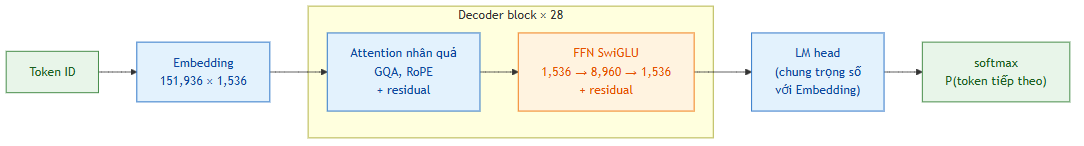
*Vì sao decoder-only và causal attention?* Model học bằng cách đoán token tiếp theo, nên khi tính ở vị trí $i$ chỉ được nhìn các token $\le i$. Causal mask chặn phần tương lai; nhờ vậy một lần chạy cho ra dự đoán ở mọi vị trí cùng lúc (dùng lại ở phần 4).

### 2.1 Thông số kiến trúc và tham số nằm ở đâu
- **Mục đích:** bảng thông số cho slide 5, đọc từ `model.config` (cell 0.5), không chép tay. Đếm tham số theo từng thành phần để trả lời câu "1.5 tỉ tham số nằm ở đâu".
- **Đầu vào:** `model`, `ARCH` (cell 0.4, 0.5).
- **Đầu ra:** `RESULTS_DIR/model_config.json`; hàm `cuda_sync()`, `vram_used_gb()`, `free_vram()` dùng cho phần 2–5; dòng START trong `part02_arch.log`.

In [19]:
# 2.1 Thông số kiến trúc: đọc lại từ config, đếm tham số theo thành phần
import gc
import time

PART02 = "part02_arch"
log(f"=== PART 02 arch START {now_iso()} ===", part=PART02)
PART02_RECORDS: list[dict] = []  # mỗi dòng "mỗi mẫu" của phần 2 (cột theo RUN_LOG_TEMPLATE_v2 §3)


def cuda_sync() -> None:
    """Chờ GPU chạy xong rồi mới bấm giờ (GPU chạy bất đồng bộ với Python)."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def vram_used_gb() -> float:
    """Bộ nhớ GPU 0 đang bị tensor chiếm (GB)."""
    return round(torch.cuda.memory_allocated(0) / 1024**3, 2) if torch.cuda.is_available() else 0.0


def free_vram() -> float:
    """Dọn bộ nhớ sau khi `del` một model; trả bộ nhớ GPU còn bị chiếm (GB)."""
    gc.collect()  # xoá hẳn object Python không còn ai trỏ tới
    if torch.cuda.is_available():
        torch.cuda.empty_cache()  # trả lại vùng nhớ PyTorch đang giữ
    return vram_used_gb()


cfg = model.config
# transformers 5.x để rope_theta trong rope_parameters; bản cũ để thẳng trong config
rope_theta = getattr(cfg, "rope_theta", None) or (getattr(cfg, "rope_parameters", None) or {}).get("rope_theta")

# Gom tham số theo tên: embed_tokens = embedding; self_attn = attention; mlp = FFN; norm = RMSNorm
PARAM_GROUPS = {"embedding": 0, "attention": 0, "ffn": 0, "norm": 0, "khác": 0}
for name, p in model.named_parameters():  # named_parameters() cũng chỉ trả embedding dùng chung một lần
    key = ("embedding" if "embed_tokens" in name else "attention" if "self_attn" in name
           else "ffn" if "mlp" in name else "norm" if "norm" in name else "khác")
    PARAM_GROUPS[key] += p.numel()

MODEL_CONFIG = {
    "model": MODEL_INSTRUCT,
    "revision": MODEL_REVISION,
    "architectures": cfg.architectures,
    **ARCH,
    "head_dim": ARCH["hidden_size"] // ARCH["num_attention_heads"],                    # 1536 / 12
    "q_heads_per_kv_head": ARCH["num_attention_heads"] // ARCH["num_key_value_heads"],  # GQA: mấy head Q dùng chung 1 cặp K, V
    "rope_theta": rope_theta,
    "n_params_by_group": PARAM_GROUPS,
    "n_params_without_embedding": ARCH["n_params"] - PARAM_GROUPS["embedding"],
}
save_json(MODEL_CONFIG, RESULTS_DIR / "model_config.json")

for k, v in MODEL_CONFIG.items():
    log(f"{k}: {v}", part=PART02, echo=False)
print(pd.Series({k: f"{v:,}" for k, v in PARAM_GROUPS.items()}, name="số tham số").to_string())
print(f"Không tính embedding: {MODEL_CONFIG['n_params_without_embedding']:,} | head_dim {MODEL_CONFIG['head_dim']} | "
      f"{MODEL_CONFIG['q_heads_per_kv_head']} head Q / 1 head KV | rope_theta {rope_theta:,.0f}")

# Tự kiểm: các nhóm cộng lại đúng tổng; embedding = vocab × hidden; mọi tham số đều vào một nhóm
assert sum(PARAM_GROUPS.values()) == ARCH["n_params"], PARAM_GROUPS
assert PARAM_GROUPS["embedding"] == ARCH["vocab_size"] * ARCH["hidden_size"]
assert PARAM_GROUPS["khác"] == 0, PARAM_GROUPS

=== PART 02 arch START 2026-11-19T15:04:20+07:00 ===
embedding      233,373,696
attention      154,198,016
ffn          1,156,055,040
norm                87,552
khác                     0
Không tính embedding: 1,310,340,608 | head_dim 128 | 6 head Q / 1 head KV | rope_theta 1,000,000


### 2.2 Causal mask
- **Mục đích:** dựng ma trận causal mask cho câu ví dụ, chia theo **token thật** của Qwen. Hàng là token đang xét; cột là token nó được nhìn. 1 = được nhìn (chính nó và các token trước), 0 = tương lai bị chặn.
- **Đầu vào:** `tok`; câu `MASK_TEXT`.
- **Đầu ra:** hàm `causal_mask()`, `token_labels()`; `FIGURES_DIR/causal_mask.png`.
- Đây là ma trận **quy tắc**, chưa phải số của model. Trọng số thật của model ở cell 2.3.

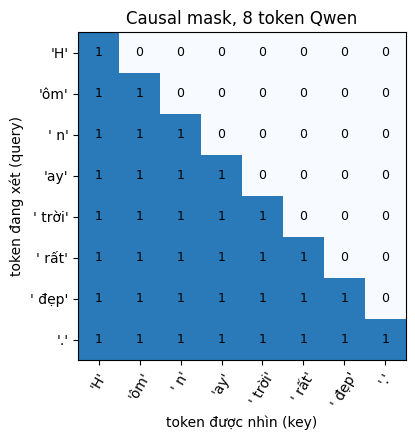

causal mask: 'Hôm nay trời rất đẹp.' → 8 token ['H', 'ôm', ' n', 'ay', ' trời', ' rất', ' đẹp', '.']


In [20]:
# 2.2 Causal mask: tam giác dưới = được nhìn, tam giác trên = tương lai bị chặn
import matplotlib.pyplot as plt


def causal_mask(n: int) -> torch.Tensor:
    """Ma trận n×n kiểu bool: True = được nhìn (chính nó và token trước), False = token tương lai."""
    return torch.tril(torch.ones(n, n, dtype=torch.bool))  # tril = giữ tam giác dưới (gồm đường chéo)


def token_labels(tok, ids: list[int]) -> list[str]:
    """Chữ của từng token: decode riêng từng ID (in token thô sẽ ra ký tự byte-level khó đọc)."""
    return [tok.decode([i]) for i in ids]


MASK_TEXT = "Hôm nay trời rất đẹp."
mask_ids = tok(MASK_TEXT, add_special_tokens=False)["input_ids"]
mask_labels = token_labels(tok, mask_ids)
n_mask = len(mask_ids)
M = causal_mask(n_mask)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(M.int(), cmap="Blues", vmin=0, vmax=1.4)
for i in range(n_mask):
    for j in range(n_mask):
        ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=9)
ax.set_xticks(range(n_mask), [repr(t) for t in mask_labels], rotation=60)
ax.set_yticks(range(n_mask), [repr(t) for t in mask_labels])
ax.set_xlabel("token được nhìn (key)")
ax.set_ylabel("token đang xét (query)")
ax.set_title(f"Causal mask, {n_mask} token Qwen")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "causal_mask.png", dpi=150)
plt.show()

log(f"causal mask: '{MASK_TEXT}' → {n_mask} token {mask_labels}", part=PART02)

# Tự kiểm: đúng tam giác dưới; mỗi token nhìn được chính nó; không token nào nhìn tương lai
assert torch.equal(M, M.tril())
assert M.diagonal().all()
assert not M.triu(diagonal=1).any()

### 2.3 Trọng số attention thật của Qwen
- **Mục đích:** lấy trọng số attention **thật** của 1 layer, 1 head trên câu ở 2.2, để thấy causal mask có tác dụng trong model.
- **Đầu vào:** `MODEL_INSTRUCT`, `MODEL_REVISION`; `mask_ids` (2.2).
- **Đầu ra:** `FIGURES_DIR/attention_qwen.png`.
- **Vì sao nạp lại model:** cách tính attention mặc định (SDPA) không trả trọng số. Phải nạp thêm một bản với `attn_implementation="eager"` (khoảng 3.1 GB). Xong thì xoá ngay để nhường bộ nhớ.
- Mặc định layer 0, head 0. Muốn xem layer hay head khác thì sửa `ATTN_LAYER`, `ATTN_HEAD`.

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

VRAM sau khi nạp bản eager: 5.76 GB


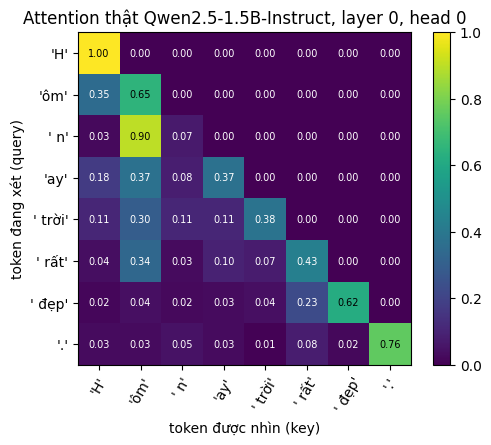

attention layer 0 head 0: tổng phần trên đường chéo = 0.000000 | tổng mỗi hàng = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
VRAM sau khi xoá bản eager: 2.88 GB


In [21]:
# 2.3 Attention thật: nạp bản eager, lấy trọng số 1 layer, 1 head
model_eager = AutoModelForCausalLM.from_pretrained(
    MODEL_INSTRUCT,
    revision=MODEL_REVISION,       # đúng bản đã tải ở cell 0.4
    torch_dtype=DTYPE,
    device_map={"": 0},
    attn_implementation="eager",   # tính attention bằng phép nhân ma trận thường → trả được trọng số
)
model_eager.eval()
print(f"VRAM sau khi nạp bản eager: {vram_used_gb()} GB")

ATTN_LAYER, ATTN_HEAD = 0, 0  # layer, head muốn xem
with torch.no_grad():
    out_eager = model_eager(torch.tensor([mask_ids], device=model_eager.device), output_attentions=True)
# out_eager.attentions: tuple 28 phần tử (mỗi layer một), mỗi phần tử shape (batch, số head Q, n, n)
attn = out_eager.attentions[ATTN_LAYER][0, ATTN_HEAD].float().cpu()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(attn, cmap="viridis", vmin=0, vmax=1)
for i in range(n_mask):
    for j in range(n_mask):
        ax.text(j, i, f"{attn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if attn[i, j] < 0.5 else "black")
ax.set_xticks(range(n_mask), [repr(t) for t in mask_labels], rotation=60)
ax.set_yticks(range(n_mask), [repr(t) for t in mask_labels])
ax.set_xlabel("token được nhìn (key)")
ax.set_ylabel("token đang xét (query)")
ax.set_title(f"Attention thật Qwen2.5-1.5B-Instruct, layer {ATTN_LAYER}, head {ATTN_HEAD}")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "attention_qwen.png", dpi=150)
plt.show()

log(f"attention layer {ATTN_LAYER} head {ATTN_HEAD}: tổng phần trên đường chéo = {attn.triu(diagonal=1).sum():.6f} | "
    f"tổng mỗi hàng = {[round(x, 3) for x in attn.sum(-1).tolist()]}", part=PART02)

# Tự kiểm: đủ 28 layer; mọi trọng số tương lai = 0; mỗi hàng là phân phối xác suất (cộng lại = 1)
assert len(out_eager.attentions) == ARCH["num_hidden_layers"]
assert attn.shape == (n_mask, n_mask)
assert torch.all(attn.triu(diagonal=1) == 0)
assert torch.allclose(attn.sum(-1), torch.ones(n_mask), atol=1e-2)

del model_eager, out_eager  # không dùng nữa, nhường bộ nhớ cho mBERT và phần 5
print(f"VRAM sau khi xoá bản eager: {free_vram()} GB")

### 2.4 Top-5 token tiếp theo
- **Mục đích:** cho thấy đầu ra của LLM là **phân phối xác suất trên cả từ điển**. Lấy vector điểm (logits) ở vị trí cuối, softmax, rồi lấy 5 token cao nhất.
- **Đầu vào:** `model`, `tok`; câu `TOPK_TEXT` (văn bản thô, không qua chat template).
- **Đầu ra:** hàm `top_k_next_tokens()`; `RESULTS_DIR/top5_next_tokens.csv` (`text, n_input_tokens, rank, token_id, token, prob`).

In [22]:
# 2.4 Top-5 token tiếp theo: softmax trên logits ở vị trí cuối
def top_k_next_tokens(model, tok, text: str, k: int = 5) -> tuple[pd.DataFrame, list[int]]:
    """Top-k token tiếp theo sau `text` (văn bản thô) kèm xác suất; trả (bảng, token ID của input)."""
    ids = tok(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(model.device)
    with torch.no_grad():
        logits = model(ids).logits[0, -1].float()  # chỉ lấy vị trí cuối: mỗi token trong từ điển một điểm
    probs = torch.softmax(logits, dim=-1)          # điểm → xác suất, cộng lại = 1
    top = torch.topk(probs, k)
    top_ids = top.indices.tolist()
    table = pd.DataFrame({"rank": range(1, k + 1), "token_id": top_ids,
                          "token": token_labels(tok, top_ids), "prob": top.values.tolist()})
    return table, ids[0].tolist()


def add_topk_records(model_name: str, text: str, last_token: str, table: pd.DataFrame, sec: float) -> None:
    """Ghi top-k vào log phần 2: mỗi token dự đoán một dòng."""
    for _, r in table.iterrows():
        rec = {"idx": len(PART02_RECORDS), "id": model_name, "text": text, "position": "cuối",
               "token": last_token, "top_k_rank": r["rank"], "top_k_token": r["token"],
               "top_k_prob": round(r["prob"], 6), "time_s": round(sec, 3)}
        PART02_RECORDS.append(rec)
        log(csv_line(list(rec.values())), part=PART02, echo=False)


PART02_REC_COLS = ["idx", "id", "text", "position", "token", "top_k_rank", "top_k_token", "top_k_prob", "time_s"]
log("--- mỗi mẫu ---", part=PART02, echo=False)
log(",".join(PART02_REC_COLS), part=PART02, echo=False)

TOPK_TEXT = "Hôm nay trời rất"
cuda_sync()
t0 = time.perf_counter()
top5_df, top5_ids = top_k_next_tokens(model, tok, TOPK_TEXT, k=5)
cuda_sync()
add_topk_records("qwen", TOPK_TEXT, tok.decode([top5_ids[-1]]), top5_df, time.perf_counter() - t0)

top5_out = top5_df.assign(text=TOPK_TEXT, n_input_tokens=len(top5_ids))
top5_out[["text", "n_input_tokens", "rank", "token_id", "token", "prob"]].to_csv(
    RESULTS_DIR / "top5_next_tokens.csv", index=False, encoding="utf-8")
print(f"INPUT: {TOPK_TEXT!r} ({len(top5_ids)} token)")
print(top5_df.to_string(index=False))
print(f"Tổng xác suất top-5: {top5_df['prob'].sum():.4f} (phần còn lại chia cho {ARCH['vocab_size'] - 5:,} token khác)")

# Tự kiểm: đủ 5 dòng, xếp giảm dần, tổng ≤ 1
assert len(top5_df) == 5
assert top5_df["prob"].is_monotonic_decreasing
assert top5_df["prob"].sum() <= 1 + 1e-6

INPUT: 'Hôm nay trời rất' (6 token)
 rank  token_id token     prob
    1    128501   đẹp 0.787874
    2    136583  nắng 0.063174
    3    130823  lạnh 0.045503
    4    131484  nóng 0.028923
    5       220       0.007144
Tổng xác suất top-5: 0.9326 (phần còn lại chia cho 151,931 token khác)


### 2.5 Tổng kết phần 2
- **Mục đích:** ghi log mỗi mẫu, kiểm đủ file kết quả, ghi dòng tổng kết.
- **Đầu vào:** `PART02_RECORDS` (2.4), `top5_df`.
- **Đầu ra:** `LOG_DIR/part02_arch_records.csv`; dòng END trong `part02_arch.log`; một dòng tóm tắt trong `run.log`.

In [23]:
# 2.5 Tổng kết phần 2
pd.DataFrame(PART02_RECORDS, columns=PART02_REC_COLS).to_csv(
    LOG_DIR / f"{PART02}_records.csv", index=False, encoding="utf-8")

PART02_FILES = ["model_config.json", "top5_next_tokens.csv"]
PART02_FIGS = ["causal_mask.png", "attention_qwen.png"]
for f in PART02_FILES:
    assert (RESULTS_DIR / f).exists(), f
for f in PART02_FIGS:
    assert (FIGURES_DIR / f).exists(), f

log(f"=== PART 02 arch END {now_iso()} ===", part=PART02)
log(f"tổng kết: top-1 sau {TOPK_TEXT!r} = {top5_df['token'].iloc[0]!r} ({top5_df['prob'].iloc[0]:.3f}) | "
    f"causal mask {n_mask}×{n_mask} | attention phần trên đường chéo = 0", part=PART02)
log(f"[{PART02}] OK {now_iso()} → {', '.join('results/' + f for f in PART02_FILES)}, "
    f"{', '.join('figures/' + f for f in PART02_FIGS)}")

=== PART 02 arch END 2026-11-19T15:04:24+07:00 ===
tổng kết: top-1 sau 'Hôm nay trời rất' = ' đẹp' (0.788) | causal mask 8×8 | attention phần trên đường chéo = 0
[part02_arch] OK 2026-11-19T15:04:24+07:00 → results/model_config.json, results/top5_next_tokens.csv, figures/causal_mask.png, figures/attention_qwen.png


**Phân tích** (normal run `20261119_150356_normal`):
- 2.1: 1,543,714,304 tham số; embedding 233,373,696, attention 154,198,016, FFN 1,156,055,040 (FFN chiếm khoảng 75%). GQA: 6 head Q dùng chung 1 cặp K, V.
- 2.2–2.3: causal mask là tam giác dưới; trọng số attention thật ở phần trên đường chéo = 0.000000, mỗi hàng cộng lại = 1. Đây là bằng chứng causal attention có tác dụng trong model: token chỉ nhìn được chính nó và các token trước.
- 2.4: sau "Hôm nay trời rất", token cao nhất là " đẹp" (P = 0.788), tiếp theo " nắng" 0.063, " lạnh" 0.046; top-5 cộng lại 0.933 < 1, phần còn lại chia cho hơn 151 nghìn token khác. Đầu ra của LLM là phân phối xác suất trên cả từ điển.

## Phần 3 — Tokenization

- Đầu vào: `tok` (Qwen, cell 0.4), `gpt2_tok` (cell 0.6), `model` (để lấy bảng embedding); 2 câu `SENT_VI`, `SENT_EN`.
- Đầu ra: `results/token_counts.csv`; log `part03_tokenization.log`, `part03_tokenization_records.csv`.
- Gồm 5 cell code:
  - 3.1 bảng token và token ID;
  - 3.2 đếm token, 2 câu × 2 tokenizer;
  - 3.3 kích thước từ điển;
  - 3.4 embedding;
  - 3.5 decode lại câu gốc, tổng kết.

### 3.1 Token và token ID
- **Mục đích:** xem tokenizer cắt câu thành những mảnh nào và gán số nào cho mỗi mảnh.
- **Đầu vào:** `tok`, `gpt2_tok`; câu `SENT_VI` (tiếng Việt), `SENT_EN` (tiếng Anh).
- **Đầu ra:** hàm `tokenize_text()`; in bảng token của Qwen cho 2 câu và của GPT-2 cho câu tiếng Việt.
- Cột `piece` là token **thô**: "Ġ" là dấu cách, còn chữ có dấu hiện thành ký tự lạ vì tokenizer làm việc trên **byte** UTF-8. Cột `text` là chữ khi decode riêng token đó; dấu "�" nghĩa là token chỉ chứa một phần byte của một chữ.

In [24]:
# 3.1 Bảng token: vị trí, token ID, mảnh thô, chữ
PART03 = "part03_tokenization"
log(f"=== PART 03 tokenization START {now_iso()} ===", part=PART03)

SENT_VI = "Hôm nay trời rất đẹp."
SENT_EN = "The weather is very nice today."


def tokenize_text(tokenizer, text: str) -> pd.DataFrame:
    """Bảng token của một câu: position, token_id, piece (token thô), text (decode riêng token đó)."""
    ids = tokenizer(text, add_special_tokens=False)["input_ids"]  # không thêm token đặc biệt
    return pd.DataFrame({"position": range(len(ids)), "token_id": ids,
                         "piece": tokenizer.convert_ids_to_tokens(ids),
                         "text": [tokenizer.decode([i]) for i in ids]})


for title, tk, sent in [("Qwen, câu tiếng Việt", tok, SENT_VI), ("Qwen, câu tiếng Anh", tok, SENT_EN),
                        ("GPT-2, câu tiếng Việt", gpt2_tok, SENT_VI)]:
    print(f"==== {title}: {sent!r} ====")
    print(tokenize_text(tk, sent).to_string(index=False))
    print()

# Tự kiểm: ghép chữ của các token lại đúng bằng câu gốc
assert "".join(tokenize_text(tok, SENT_VI)["text"]) == SENT_VI

=== PART 03 tokenization START 2026-11-19T15:04:24+07:00 ===
==== Qwen, câu tiếng Việt: 'Hôm nay trời rất đẹp.' ====
 position  token_id   piece  text
        0        39       H     H
        1     94365     Ã´m    ôm
        2       308      Ġn     n
        3       352      ay    ay
        4    130868 Ġtrá»Ŀi  trời
        5    128323  Ġráº¥t   rất
        6    128501 ĠÄĳáº¹p   đẹp
        7        13       .     .

==== Qwen, câu tiếng Anh: 'The weather is very nice today.' ====
 position  token_id    piece     text
        0       785      The      The
        1      9104 Ġweather  weather
        2       374      Ġis       is
        3      1602    Ġvery     very
        4      6419    Ġnice     nice
        5      3351   Ġtoday    today
        6        13        .        .

==== GPT-2, câu tiếng Việt: 'Hôm nay trời rất đẹp.' ====
 position  token_id piece text
        0        39     H    H
        1     27083    Ã´    ô
        2        76     m    m
        3       299    Ġn

### 3.2 Đếm token: 2 câu × 2 tokenizer
- **Mục đích:** so số token của cùng một câu với 2 tokenizer. Đếm cùng một cách, `add_special_tokens=False`, để công bằng.
- **Đầu vào:** `tok`, `gpt2_tok`; `SENT_VI`, `SENT_EN`.
- **Đầu ra:** hàm `compare_token_counts()`; `RESULTS_DIR/token_counts.csv` (`sentence, lang, tokenizer, n_chars, n_bytes, n_tokens, tokens`); mỗi dòng một dòng log.

In [25]:
# 3.2 Đếm token cho 2 câu × 2 tokenizer
def compare_token_counts(tokenizers: dict, sentences: dict) -> pd.DataFrame:
    """Số ký tự, số byte UTF-8 và số token của mỗi câu với mỗi tokenizer."""
    rows = []
    for lang, sent in sentences.items():
        for name, tk in tokenizers.items():
            ids = tk(sent, add_special_tokens=False)["input_ids"]
            rows.append({"sentence": sent, "lang": lang, "tokenizer": name, "n_chars": len(sent),
                         "n_bytes": len(sent.encode("utf-8")),  # chữ có dấu tốn 2–3 byte
                         "n_tokens": len(ids), "tokens": "|".join(tk.decode([i]) for i in ids)})
    return pd.DataFrame(rows)


PART03_REC_COLS = ["idx", "id", "sentence", "lang", "tokenizer", "n_tokens", "tokens", "time_s"]
log(f"tham số: tokenizer = {MODEL_INSTRUCT}, {TOKENIZER_GPT2} | add_special_tokens=False", part=PART03)
log(f"dữ liệu vào: 2 câu viết trong cell: {SENT_VI!r}, {SENT_EN!r}", part=PART03)
log("--- mỗi mẫu ---", part=PART03, echo=False)
log(",".join(PART03_REC_COLS), part=PART03, echo=False)

t0 = time.perf_counter()
counts_df = compare_token_counts({"gpt2": gpt2_tok, "qwen2.5": tok}, {"vi": SENT_VI, "en": SENT_EN})
sec = time.perf_counter() - t0
counts_df.to_csv(RESULTS_DIR / "token_counts.csv", index=False, encoding="utf-8")

part03_records = []
for idx, r in counts_df.iterrows():
    rec = {"idx": idx, "id": f"{r['lang']}_{r['tokenizer']}", "sentence": r["sentence"], "lang": r["lang"],
           "tokenizer": r["tokenizer"], "n_tokens": r["n_tokens"], "tokens": r["tokens"],
           "time_s": round(sec / len(counts_df), 4)}
    part03_records.append(rec)
    log(csv_line(list(rec.values())), part=PART03, echo=False)
pd.DataFrame(part03_records, columns=PART03_REC_COLS).to_csv(
    LOG_DIR / f"{PART03}_records.csv", index=False, encoding="utf-8")

print(counts_df.drop(columns=["tokens"]).to_string(index=False))
print()
print(counts_df.pivot(index="sentence", columns="tokenizer", values="n_tokens"))

# Tự kiểm: đủ bảng 2 × 2, số token dương
assert len(counts_df) == 4 and (counts_df["n_tokens"] > 0).all()

tham số: tokenizer = Qwen/Qwen2.5-1.5B-Instruct, openai-community/gpt2 | add_special_tokens=False
dữ liệu vào: 2 câu viết trong cell: 'Hôm nay trời rất đẹp.', 'The weather is very nice today.'
                       sentence lang tokenizer  n_chars  n_bytes  n_tokens
          Hôm nay trời rất đẹp.   vi      gpt2       21       29        22
          Hôm nay trời rất đẹp.   vi   qwen2.5       21       29         8
The weather is very nice today.   en      gpt2       31       31         7
The weather is very nice today.   en   qwen2.5       31       31         7

tokenizer                        gpt2  qwen2.5
sentence                                      
Hôm nay trời rất đẹp.              22        8
The weather is very nice today.     7        7


### 3.3 Kích thước từ điển
- **Mục đích:** so số token trong từ điển của 2 tokenizer. Với Qwen có **3 con số khác nhau**, cần nói đúng:
  - `tok.vocab_size`: token thường;
  - `len(tok)`: token thường cộng token đặc biệt (`<|im_start|>`, `<|im_end|>`…);
  - `model.config.vocab_size`: số hàng của bảng embedding, lớn hơn `len(tok)`; các hàng dư không ứng với token nào.
- **Đầu vào:** `tok`, `gpt2_tok`, `model`.
- **Đầu ra:** in và ghi log 3 con số.

In [26]:
# 3.3 Kích thước từ điển
VOCAB_INFO = {
    "gpt2 vocab_size": gpt2_tok.vocab_size,
    "qwen tok.vocab_size (token thường)": tok.vocab_size,
    "qwen len(tok) (+ token đặc biệt)": len(tok),
    "qwen model.config.vocab_size (số hàng embedding)": model.config.vocab_size,
}
for k, v in VOCAB_INFO.items():
    log(f"{k}: {v:,}", part=PART03)

# Tự kiểm: GPT-2 đúng 50,257; mọi token ID của Qwen đều có hàng trong bảng embedding
assert gpt2_tok.vocab_size == 50_257
assert tok.vocab_size <= len(tok) <= model.config.vocab_size

gpt2 vocab_size: 50,257
qwen tok.vocab_size (token thường): 151,643
qwen len(tok) (+ token đặc biệt): 151,665
qwen model.config.vocab_size (số hàng embedding): 151,936


### 3.4 Embedding: tra hàng theo token ID
- **Mục đích:** bảng embedding là ma trận (số hàng từ điển × `hidden_size`). Lấy embedding của một token = **lấy hàng** có số thứ tự bằng token ID, giống `nn.Embedding` ở Ch6.
- **Đầu vào:** `model.get_input_embeddings()`; token ID của `SENT_VI`.
- **Đầu ra:** in shape bảng embedding, shape embedding của câu, 5 số đầu của vector token đầu tiên.
- Qwen2.5-1.5B **dùng chung** ma trận này cho lớp đầu ra (LM head), `tie_word_embeddings = True`. Cell kiểm điều này bằng địa chỉ bộ nhớ.

In [27]:
# 3.4 Embedding: (1, n_token) token ID → (1, n_token, hidden_size) vector
emb_layer = model.get_input_embeddings()  # nn.Embedding
vi_ids = torch.tensor([tok(SENT_VI, add_special_tokens=False)["input_ids"]], device=model.device)
with torch.no_grad():
    vi_emb = emb_layer(vi_ids)

print(f"Bảng embedding: {tuple(emb_layer.weight.shape)} = {emb_layer.weight.numel():,} tham số")
print(f"Token ID của câu: {tuple(vi_ids.shape)} → embedding: {tuple(vi_emb.shape)}")
print(f"5 số đầu của vector token đầu tiên {tok.decode([vi_ids[0, 0].item()])!r}: {vi_emb[0, 0, :5].float().tolist()}")
same_matrix = model.get_output_embeddings().weight.data_ptr() == emb_layer.weight.data_ptr()
log(f"embedding {tuple(emb_layer.weight.shape)} | câu {tuple(vi_ids.shape)} → {tuple(vi_emb.shape)} | "
    f"dùng chung với LM head: {same_matrix}", part=PART03)

# Tự kiểm: shape đúng config; embedding đúng bằng các hàng của bảng; dùng chung với LM head như config ghi
assert tuple(emb_layer.weight.shape) == (ARCH["vocab_size"], ARCH["hidden_size"])
assert tuple(vi_emb.shape) == (1, vi_ids.shape[1], ARCH["hidden_size"])
assert torch.equal(vi_emb[0], emb_layer.weight[vi_ids[0]])
assert same_matrix == ARCH["tie_word_embeddings"]

Bảng embedding: (151936, 1536) = 233,373,696 tham số
Token ID của câu: (1, 8) → embedding: (1, 8, 1536)
5 số đầu của vector token đầu tiên 'H': [0.0228271484375, -0.0245361328125, 0.0028839111328125, -0.0022125244140625, -0.03466796875]
embedding (151936, 1536) | câu (1, 8) → (1, 8, 1536) | dùng chung với LM head: True


### 3.5 Decode lại câu gốc và tổng kết phần 3
- **Mục đích:** kiểm hai chiều: câu → token ID → câu phải ra đúng câu gốc, với cả 2 tokenizer.
- **Đầu vào:** `tok`, `gpt2_tok`; `SENT_VI`, `SENT_EN`.
- **Đầu ra:** dòng END và tổng kết trong `part03_tokenization.log`; một dòng tóm tắt trong `run.log`.

In [28]:
# 3.5 Decode: token ID → chữ, phải ra đúng câu gốc
for name, tk in [("qwen2.5", tok), ("gpt2", gpt2_tok)]:
    for sent in (SENT_VI, SENT_EN):
        back = tk.decode(tk(sent, add_special_tokens=False)["input_ids"])
        print(f"{name}: {back!r}")
        assert back == sent, (name, sent, back)

n_tok = counts_df.set_index(["lang", "tokenizer"])["n_tokens"]
log(f"=== PART 03 tokenization END {now_iso()} ===", part=PART03)
log(f"tổng kết: số token vi gpt2/qwen = {n_tok['vi', 'gpt2']}/{n_tok['vi', 'qwen2.5']} | "
    f"en gpt2/qwen = {n_tok['en', 'gpt2']}/{n_tok['en', 'qwen2.5']} | decode đúng câu gốc: 4/4", part=PART03)
log(f"[{PART03}] OK {now_iso()} → {(RESULTS_DIR / 'token_counts.csv').relative_to(ROOT)} (4 dòng)")

qwen2.5: 'Hôm nay trời rất đẹp.'
qwen2.5: 'The weather is very nice today.'
gpt2: 'Hôm nay trời rất đẹp.'
gpt2: 'The weather is very nice today.'
=== PART 03 tokenization END 2026-11-19T15:04:24+07:00 ===
tổng kết: số token vi gpt2/qwen = 22/8 | en gpt2/qwen = 7/7 | decode đúng câu gốc: 4/4
[part03_tokenization] OK 2026-11-19T15:04:24+07:00 → outputs/results/token_counts.csv (4 dòng)


**Phân tích** (normal run `20261119_150356_normal`):
- Câu tiếng Việt: GPT-2 22 token, Qwen 8 token. Câu tiếng Anh: 7 và 7. GPT-2 học chủ yếu từ tiếng Anh nên tách chữ có dấu thành từng byte (ví dụ "ờ" = 3 byte `E1 BB 9D` = 3 token, decode riêng từng token ra "�"); Qwen học đa ngôn ngữ nên có token riêng cho " trời", " rất", " đẹp".
- Qwen vẫn tách "Hôm" thành "H" + "ôm": tokenizer học theo tần suất, không theo từ điển tiếng Việt.
- Ít token hơn thì tốn ít chỗ trong ngữ cảnh hơn (mục 9) và sinh nhanh hơn, vì mỗi token là một bước sinh (mục 6).
- Embedding: mỗi token ID → một hàng 1,536 số của bảng 151,936 × 1,536, dùng chung với LM head. Decode lại ra đúng câu gốc 4/4.

## Phần 4 — Nguyên lý học

- Đầu vào: `model`, `tok`; câu `SENT_VI` (phần 3).
- Đầu ra: `results/per_token_loss.csv`, `results/loss_summary.csv`; log `part04_loss.log`, `part04_loss_records.csv`.
- **Không train:** chỉ chạy suy luận trong `torch.no_grad()`, không gọi `loss.backward()`.
- Gồm 5 cell code:
  - 4.1 cặp ngữ cảnh → token mục tiêu;
  - 4.2 loss từng token;
  - 4.3 so với `outputs.loss`;
  - 4.4 perplexity;
  - 4.5 câu xáo trộn và câu tiếng Anh, tổng kết.

### 4.1 Cặp ngữ cảnh → token mục tiêu
- **Mục đích:** một câu n token tạo ra n − 1 bài toán "đoán token tiếp theo". Dùng token **thật** của Qwen, nên số cặp theo số token thật, không theo số từ.
- **Đầu vào:** `SENT_VI`, `tok`.
- **Đầu ra:** hàm `make_context_target_pairs()`; bảng ngữ cảnh (chữ) → token mục tiêu.

In [29]:
# 4.1 Cặp ngữ cảnh → token mục tiêu
PART04 = "part04_loss"
log(f"=== PART 04 loss START {now_iso()} ===", part=PART04)


def make_context_target_pairs(token_ids: list[int]) -> list[tuple[list[int], int]]:
    """[a, b, c, d] → [([a], b), ([a, b], c), ([a, b, c], d)]: ngữ cảnh là mọi token trước, mục tiêu là token kế."""
    return [(token_ids[:i], token_ids[i]) for i in range(1, len(token_ids))]


# Tự kiểm hàm trên ví dụ nhỏ
assert make_context_target_pairs([1, 2, 3, 4]) == [([1], 2), ([1, 2], 3), ([1, 2, 3], 4)]

loss_ids = tok(SENT_VI, add_special_tokens=False)["input_ids"]
pairs = make_context_target_pairs(loss_ids)
pairs_df = pd.DataFrame({"context": [tok.decode(c) for c, _ in pairs],
                         "target_token": [tok.decode([t]) for _, t in pairs]})
print(f"{SENT_VI!r}: {len(loss_ids)} token → {len(pairs)} cặp")
print(pairs_df.to_string())

assert len(pairs) == len(loss_ids) - 1

=== PART 04 loss START 2026-11-19T15:04:24+07:00 ===
'Hôm nay trời rất đẹp.': 8 token → 7 cặp
                context target_token
0                     H           ôm
1                   Hôm            n
2                 Hôm n           ay
3               Hôm nay         trời
4          Hôm nay trời          rất
5      Hôm nay trời rất          đẹp
6  Hôm nay trời rất đẹp            .


### 4.2 Loss từng token (cross-entropy)
- **Mục đích:** với mỗi vị trí, lấy xác suất model gán cho **token đúng** p, loss = −ln p.
- **Một lần chạy cho cả n − 1 dự đoán:** nhờ causal mask, logits ở vị trí i chỉ dựa trên token 0…i, nên `logits[i]` chính là dự đoán cho token i + 1. Vì vậy so logits bỏ vị trí cuối với token ID bỏ token đầu ("dịch nhãn sang trái 1 vị trí").
- **Đầu vào:** `model`, `tok`; câu.
- **Đầu ra:** hàm `per_token_loss()` trả bảng `idx, context, target_token, target_id, prob_target, loss_token`.

Với câu có các token $x_1, \dots, x_n$, loss trung bình là:

$$\mathcal{L} = -\frac{1}{n-1}\sum_{i=1}^{n-1} \ln p_\theta(x_{i+1} \mid x_1, \dots, x_i)$$

Token đúng được gán xác suất càng cao thì $-\ln p$ càng gần 0; xác suất càng thấp thì loss càng lớn.

In [30]:
# 4.2 Loss từng token: một lần chạy model, lấy −log p của token đúng ở mọi vị trí
import torch.nn.functional as F


def per_token_loss(model, tok, text: str) -> pd.DataFrame:
    """Cross-entropy từng token của một câu (văn bản thô): P(token đúng) và −ln P ở mỗi vị trí."""
    ids = tok(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(model.device)
    with torch.no_grad():
        logits = model(ids).logits[0].float()     # (n, vocab); float32 để tính log cho chính xác
    log_probs = F.log_softmax(logits[:-1], dim=-1)  # bỏ vị trí cuối: không có token nào sau nó để đoán
    targets = ids[0, 1:]                            # bỏ token đầu: không có ngữ cảnh để đoán nó
    lp = log_probs.gather(1, targets[:, None])[:, 0]  # log P(token đúng) ở từng vị trí
    ids_list = ids[0].tolist()
    return pd.DataFrame({
        "idx": range(len(targets)),
        "context": [tok.decode(ids_list[:i + 1]) for i in range(len(targets))],
        "target_token": [tok.decode([t]) for t in targets.tolist()],
        "target_id": targets.tolist(),
        "prob_target": lp.exp().tolist(),
        "loss_token": (-lp).tolist(),
    })


PART04_REC_COLS = ["idx", "id", "context", "target_token", "prob_target", "loss_token", "time_s"]
log(f"tham số: model={MODEL_INSTRUCT} | văn bản thô, không chat template | torch.no_grad(), không backward", part=PART04)
log(f"dữ liệu vào: câu viết trong cell {SENT_VI!r}", part=PART04)
log("--- mỗi mẫu ---", part=PART04, echo=False)
log(",".join(PART04_REC_COLS), part=PART04, echo=False)

cuda_sync()
t0 = time.perf_counter()
loss_df = per_token_loss(model, tok, SENT_VI)
cuda_sync()
loss_sec = time.perf_counter() - t0
part04_records = []
for _, r in loss_df.iterrows():
    rec = {"idx": r["idx"], "id": "vi", "context": r["context"], "target_token": r["target_token"],
           "prob_target": round(r["prob_target"], 6), "loss_token": round(r["loss_token"], 6),
           "time_s": round(loss_sec, 3)}
    part04_records.append(rec)
    log(csv_line(list(rec.values())), part=PART04, echo=False)
print(loss_df.drop(columns=["target_id"]).to_string(index=False))

# Tự kiểm: đúng n − 1 vị trí; loss ≥ 0; xác suất trong (0, 1]; mục tiêu khớp các cặp ở 4.1
assert len(loss_df) == len(pairs)
assert (loss_df["loss_token"] >= 0).all() and loss_df["prob_target"].between(0, 1).all()
assert loss_df["target_id"].tolist() == [t for _, t in pairs]

tham số: model=Qwen/Qwen2.5-1.5B-Instruct | văn bản thô, không chat template | torch.no_grad(), không backward
dữ liệu vào: câu viết trong cell 'Hôm nay trời rất đẹp.'
 idx              context target_token  prob_target  loss_token
   0                    H           ôm     0.000278    8.188926
   1                  Hôm            n     0.705417    0.348967
   2                Hôm n           ay     0.996053    0.003955
   3              Hôm nay         trời     0.001757    6.344238
   4         Hôm nay trời          rất     0.028604    3.554224
   5     Hôm nay trời rất          đẹp     0.788214    0.237986
   6 Hôm nay trời rất đẹp            .     0.109118    2.215329


### 4.3 Loss trung bình so với `outputs.loss` của `transformers`
- **Mục đích:** truyền `labels=input_ids` thì `transformers` tự dịch nhãn và trả loss trung bình. Loss đó phải trùng với trung bình tự tính ở 4.2. Trùng thì vừa chứng tỏ hiểu đúng công thức, vừa chứng tỏ thư viện tự dịch nhãn.
- **Đầu vào:** `loss_df` (4.2), `model`, `tok`.
- **Đầu ra:** `loss_mean`, `hf_loss`; `assert torch.allclose(..., atol=1e-3)`.

In [31]:
# 4.3 So loss tự tính với loss của transformers
def hf_loss(model, tok, text: str) -> float:
    """Loss trung bình do transformers tính khi truyền labels = input_ids (thư viện tự dịch nhãn)."""
    ids = tok(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(model.device)
    with torch.no_grad():
        return model(ids, labels=ids).loss.float().item()


loss_mean = float(loss_df["loss_token"].mean())  # float Python, không để kiểu numpy
loss_hf = hf_loss(model, tok, SENT_VI)
print(f"Loss tự tính (trung bình {len(loss_df)} token): {loss_mean:.6f}")
print(f"outputs.loss của transformers:              {loss_hf:.6f}")
print(f"Chênh lệch: {abs(loss_mean - loss_hf):.2e}")
log(f"loss_mean tự tính = {loss_mean:.6f} | outputs.loss = {loss_hf:.6f} | chênh {abs(loss_mean - loss_hf):.2e}",
    part=PART04)

assert torch.allclose(torch.tensor(loss_mean), torch.tensor(loss_hf), atol=1e-3)

Loss tự tính (trung bình 7 token): 2.984804
outputs.loss của transformers:              2.984804
Chênh lệch: 6.30e-08
loss_mean tự tính = 2.984804 | outputs.loss = 2.984804 | chênh 6.30e-08


### 4.4 Perplexity
- **Mục đích:** perplexity = e^loss, đọc là "model phân vân trung bình như đang chọn đều giữa khoảng PPL token". Mốc so sánh: model đoán bừa đều trên toàn từ điển có loss = ln(số hàng từ điển).
- **Đầu vào:** `loss_mean` (4.3), `model.config.vocab_size`.
- **Đầu ra:** in loss, perplexity của câu và của mốc đoán bừa.

$$\text{PPL} = e^{\mathcal{L}}, \qquad \mathcal{L}_{\text{đoán bừa}} = \ln V \;(V = 151{,}936 \Rightarrow \mathcal{L} \approx 11.93)$$

In [32]:
# 4.4 Perplexity = exp(loss); mốc đoán bừa = ln(vocab)
import math

ppl = math.exp(loss_mean)
loss_uniform = math.log(model.config.vocab_size)  # đoán đều trên 151,936 hàng
print(f"Câu ví dụ   : loss {loss_mean:.3f} | perplexity {ppl:,.1f}")
print(f"Đoán bừa đều: loss {loss_uniform:.3f} | perplexity {model.config.vocab_size:,}")
log(f"perplexity = {ppl:.3f} | mốc đoán bừa: loss {loss_uniform:.3f}, perplexity {model.config.vocab_size:,}",
    part=PART04)

Câu ví dụ   : loss 2.985 | perplexity 19.8
Đoán bừa đều: loss 11.931 | perplexity 151,936
perplexity = 19.783 | mốc đoán bừa: loss 11.931, perplexity 151,936


### 4.5 Câu xáo trộn, câu tiếng Anh và tổng kết phần 4
- **Mục đích:** cùng các từ nhưng **sai trật tự** thì loss có cao hơn không; câu tiếng Anh cùng nghĩa thì loss bao nhiêu. Ghi đúng như đo, kể cả khi không như dự đoán.
- **Đầu vào:** `LOSS_SENTENCES` (3 câu), `per_token_loss()`, `hf_loss()`.
- **Đầu ra:** `RESULTS_DIR/per_token_loss.csv` (mọi token của 3 câu); `RESULTS_DIR/loss_summary.csv` (`sentence_id, sentence, n_tokens, loss_mean, perplexity, hf_loss`); `LOG_DIR/part04_loss_records.csv`; dòng END.
- Không so perplexity giữa câu Việt và câu Anh như so độ "thông minh": hai câu khác token, khác số token.

In [33]:
# 4.5 So 3 câu và tổng kết phần 4
LOSS_SENTENCES = {
    "vi": SENT_VI,
    "vi_shuffled": "đẹp rất trời nay Hôm.",  # cùng các từ, sai trật tự
    "en": SENT_EN,
}
all_loss, summary_rows = [], []
for sid, sent in LOSS_SENTENCES.items():
    df = loss_df if sid == "vi" else per_token_loss(model, tok, sent)  # câu "vi" đã tính ở 4.2
    all_loss.append(df.assign(sentence_id=sid, sentence=sent))
    m = df["loss_token"].mean()
    summary_rows.append({"sentence_id": sid, "sentence": sent, "n_tokens": len(df) + 1, "loss_mean": m,
                         "perplexity": math.exp(m), "hf_loss": hf_loss(model, tok, sent)})
    if sid != "vi":
        for _, r in df.iterrows():
            rec = {"idx": len(part04_records), "id": sid, "context": r["context"], "target_token": r["target_token"],
                   "prob_target": round(r["prob_target"], 6), "loss_token": round(r["loss_token"], 6), "time_s": ""}
            part04_records.append(rec)
            log(csv_line(list(rec.values())), part=PART04, echo=False)

per_token_df = pd.concat(all_loss, ignore_index=True)
per_token_df = per_token_df[["sentence_id", "sentence", "idx", "context", "target_token", "target_id",
                             "prob_target", "loss_token"]]
per_token_df.to_csv(RESULTS_DIR / "per_token_loss.csv", index=False, encoding="utf-8")
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / "loss_summary.csv", index=False, encoding="utf-8")
pd.DataFrame(part04_records, columns=PART04_REC_COLS).to_csv(
    LOG_DIR / f"{PART04}_records.csv", index=False, encoding="utf-8")
print(summary_df.to_string(index=False))

# Tự kiểm: mỗi câu loss tự tính khớp transformers
for r in summary_rows:
    assert abs(r["loss_mean"] - r["hf_loss"]) < 1e-3, r

s = summary_df.set_index("sentence_id")["loss_mean"]
log(f"=== PART 04 loss END {now_iso()} ===", part=PART04)
log(f"tổng kết: loss_mean vi={s['vi']:.3f} (perplexity {math.exp(s['vi']):.2f}) | xáo trộn={s['vi_shuffled']:.3f} | "
    f"en={s['en']:.3f} | đoán bừa={loss_uniform:.3f} | khớp outputs.loss (atol 1e-3): 3/3", part=PART04)
log(f"[{PART04}] OK {now_iso()} → {(RESULTS_DIR / 'per_token_loss.csv').relative_to(ROOT)}, "
    f"{(RESULTS_DIR / 'loss_summary.csv').relative_to(ROOT)}")

sentence_id                        sentence  n_tokens  loss_mean  perplexity  hf_loss
         vi           Hôm nay trời rất đẹp.         8   2.984804   19.782617 2.984804
vi_shuffled           đẹp rất trời nay Hôm.         9   6.701457  813.590019 6.701457
         en The weather is very nice today.         7   3.129398   22.860209 3.129398
=== PART 04 loss END 2026-11-19T15:04:24+07:00 ===
tổng kết: loss_mean vi=2.985 (perplexity 19.78) | xáo trộn=6.701 | en=3.129 | đoán bừa=11.931 | khớp outputs.loss (atol 1e-3): 3/3
[part04_loss] OK 2026-11-19T15:04:24+07:00 → outputs/results/per_token_loss.csv, outputs/results/loss_summary.csv


**Phân tích** (normal run `20261119_150356_normal`):
- Token "ay" (sau "Hôm n") có loss thấp nhất (P = 0.996, loss 0.004) vì "Hôm n" gần như chỉ đi với "ay"; token "ôm" (sau "H") có loss cao nhất (P = 0.0003, loss 8.19) vì sau một chữ "H" có rất nhiều khả năng. " đẹp" sau "Hôm nay trời rất" có P = 0.788.
- Loss trung bình 2.985, perplexity 19.8, thấp hơn nhiều so với đoán bừa (loss 11.931, perplexity 151,936) → model đã học được quy luật tiếng Việt từ dữ liệu.
- Loss tự tính khớp `outputs.loss` (chênh 6.3e-08): `transformers` tự dịch nhãn sang trái 1 vị trí, giống cách cặp ngữ cảnh → token mục tiêu ở 4.1.
- Câu xáo trộn "đẹp rất trời nay Hôm.": loss 6.701 so với 2.985 của câu đúng trật tự; câu tiếng Anh 3.129.

## Phần 5 — Base vs Instruct

- Đầu vào: `data/base_vs_instruct.json` (4 prompt); `Qwen/Qwen2.5-1.5B` (base, khoảng 3.1 GB); model chính.
- Đầu ra: `results/base_vs_instruct.csv`; log `part05_base_instruct.log`, `part05_base_instruct_records.csv`.
- **Giữ giống nhau ở cả hai bản:** greedy (`do_sample=False`), cùng `max_new_tokens`, cùng `repetition_penalty = REP_PENALTY_PART05`.
- **Khác nhau không tránh được** (ghi trên slide 11):
  - base nhận văn bản thô; instruct nhận chat template, kèm system prompt mặc định "You are Qwen…";
  - token kết thúc: base dừng ở `<|endoftext|>`, instruct dừng ở `<|im_end|>`;
  - Qwen2.5-Instruct đã qua SFT **và** alignment, nên demo cho thấy **tác dụng gộp** của post-training, không tách riêng SFT được.
- Gồm 4 cell code:
  - 5.1 nạp bản base;
  - 5.2 so `generation_config`;
  - 5.3 chạy cùng prompt trên 2 bản;
  - 5.4 chấm, ghi kết quả, giải phóng bản base.

### 5.1 Nạp bản base
- **Mục đích:** tải `Qwen/Qwen2.5-1.5B` (cùng kiến trúc, chưa qua post-training) bên cạnh model chính. Hai bản fp16 khoảng 6.2 GB, vừa T4. mBERT và bản eager đã xoá ở phần 2.
- **Đầu vào:** `MODEL_BASE` (cell 0.1).
- **Đầu ra:** `tok_base`, `model_base` (`eval()`), `BASE_REVISION`; `assert` kiến trúc giống bản instruct.

In [34]:
# 5.1 Nạp bản base (cùng kiến trúc, chưa post-training)
PART05 = "part05_base_instruct"
log(f"=== PART 05 base_instruct START {now_iso()} ===", part=PART05)
print(f"VRAM trước khi nạp base: {free_vram()} GB")

tok_base = AutoTokenizer.from_pretrained(MODEL_BASE)
model_base = AutoModelForCausalLM.from_pretrained(MODEL_BASE, torch_dtype=DTYPE, device_map={"": 0})
model_base.eval()
BASE_REVISION = getattr(model_base.config, "_commit_hash", None) or model_info(MODEL_BASE).sha
n_base = sum(p.numel() for p in model_base.parameters())
print(f"VRAM sau khi nạp base: {vram_used_gb()} GB")
log(f"model base: {MODEL_BASE} (revision {BASE_REVISION}) | {n_base:,} tham số | device: {model_base.device}",
    part=PART05, to_run=True)

# Tự kiểm: cùng kiến trúc, cùng số tham số, cùng từ điển với bản instruct → khác nhau chỉ ở trọng số
for k in ["num_hidden_layers", "hidden_size", "num_attention_heads", "num_key_value_heads",
          "intermediate_size", "vocab_size"]:
    assert getattr(model_base.config, k) == ARCH[k], k
assert n_base == ARCH["n_params"], n_base
assert tok_base.get_vocab() == tok.get_vocab()

=== PART 05 base_instruct START 2026-11-19T15:04:24+07:00 ===
VRAM trước khi nạp base: 2.88 GB


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

VRAM sau khi nạp base: 5.76 GB
model base: Qwen/Qwen2.5-1.5B (revision 8faed761d45a263340a0528343f099c05c9a4323) | 1,543,714,304 tham số | device: cuda:0


### 5.2 So `generation_config` mặc định của 2 bản
- **Mục đích:** bằng chứng 2 bản có cấu hình sinh mặc định **khác nhau**: instruct mặc định lấy mẫu ngẫu nhiên, có `repetition_penalty` 1.1; base mặc định greedy, không có `repetition_penalty`. Vì vậy 5.3 phải truyền mọi tham số tường minh.
- **Đầu vào:** `model.generation_config`, `model_base.generation_config`.
- **Đầu ra:** bảng so sánh trong output và log; `REP_PENALTY_PART05`.
- `REP_PENALTY_PART05 = 1.0` (không phạt lặp) cho cả 2 bản: greedy thuần, không bản nào được lợi từ cấu hình mặc định của mình.

In [35]:
# 5.2 generation_config mặc định của 2 bản
REP_PENALTY_PART05 = 1.0  # dùng chung cho cả 2 bản; 1.0 = không phạt lặp

GEN_KEYS = ["do_sample", "temperature", "top_p", "top_k", "repetition_penalty", "eos_token_id", "max_new_tokens"]
gen_cmp = pd.DataFrame({
    "instruct": [getattr(model.generation_config, k, None) for k in GEN_KEYS],
    "base": [getattr(model_base.generation_config, k, None) for k in GEN_KEYS],
}, index=GEN_KEYS)
print(gen_cmp.to_string())
log("generation_config mặc định (instruct | base): "
    + "; ".join(f"{k}={gen_cmp.loc[k, 'instruct']} | {gen_cmp.loc[k, 'base']}" for k in GEN_KEYS), part=PART05)

# Tự kiểm: đúng như generation_config.json trên Hugging Face
assert model.generation_config.do_sample is True
assert model_base.generation_config.do_sample is False

                            instruct    base
do_sample                       True   False
temperature                      0.7    None
top_p                            0.8    None
top_k                             20    None
repetition_penalty               1.1    None
eos_token_id        [151645, 151643]  151643
max_new_tokens                  None    2048
generation_config mặc định (instruct | base): do_sample=True | False; temperature=0.7 | None; top_p=0.8 | None; top_k=20 | None; repetition_penalty=1.1 | None; eos_token_id=[151645, 151643] | 151643; max_new_tokens=None | 2048


### 5.3 Chạy cùng prompt trên 2 bản
- **Mục đích:** mỗi prompt chạy trên cả 2 bản, cùng tham số sinh. Bản base nhận **văn bản thô** (đúng cách nó được huấn luyện); bản instruct nhận **chat template** (đúng cách dùng).
- **Đầu vào:** `DATA_DIR / "base_vs_instruct.json"` (`id, type, prompt, max_new_tokens, follow_rule, auto_check, expected`); `REP_PENALTY_PART05`.
- **Đầu ra:** hàm `generate_greedy()`; `part05_df` (mỗi prompt 2 dòng); mỗi lần sinh một dòng log.
- Sửa `data/base_vs_instruct.json` thì phải cập nhật Kaggle Dataset (New Version), như `tasks_prompts.json` ở phần 1.

In [36]:
# 5.3 Cùng prompt, cùng tham số sinh, trên base (văn bản thô) và instruct (chat template)
BVI_EXPECTED_VERSION = "v1"  # đổi khi sửa data/base_vs_instruct.json
bvi_json = json.loads((DATA_DIR / "base_vs_instruct.json").read_text(encoding="utf-8"))
assert bvi_json["_meta"]["version"] == BVI_EXPECTED_VERSION, (
    f"base_vs_instruct.json đang là {bvi_json['_meta']['version']}, cần {BVI_EXPECTED_VERSION}: "
    "cập nhật Kaggle Dataset (New Version) và gắn lại vào notebook")
BVI_PROMPTS: list[dict] = bvi_json["prompts"]


def generate_greedy(mdl, tokenizer, enc, max_new_tokens: int, repetition_penalty: float) -> tuple[str, int, float]:
    """Sinh greedy từ input đã mã hoá; trả (output, số token sinh ra, giây). Truyền đủ tham số sinh."""
    n_in = enc["input_ids"].shape[1]
    cuda_sync()
    t0 = time.perf_counter()
    with torch.no_grad():
        out = mdl.generate(
            **enc,
            max_new_tokens=max_new_tokens,
            do_sample=False,                            # greedy
            temperature=None, top_p=None, top_k=None,   # tắt tham số lấy mẫu mặc định (bản instruct)
            repetition_penalty=repetition_penalty,      # đặt rõ, giống nhau cho cả 2 bản
            pad_token_id=tokenizer.pad_token_id,
        )
    cuda_sync()
    new_ids = out[0, n_in:]
    return tokenizer.decode(new_ids, skip_special_tokens=True).strip(), len(new_ids), time.perf_counter() - t0


PART05_REC_COLS = ["idx", "id", "prompt_id", "model", "prompt_format", "n_input_tokens", "n_output_tokens",
                   "truncated", "output", "time_s"]
log(f"tham số: do_sample=False | repetition_penalty={REP_PENALTY_PART05} (cả 2 bản) | "
    f"max_new_tokens={ {p['id']: p['max_new_tokens'] for p in BVI_PROMPTS} } | "
    "base: văn bản thô; instruct: chat template (có system prompt mặc định)", part=PART05)
log(f"dữ liệu vào: data/base_vs_instruct.json {BVI_EXPECTED_VERSION} ({len(BVI_PROMPTS)} prompt)", part=PART05)
log("--- mỗi mẫu ---", part=PART05, echo=False)
log(",".join(PART05_REC_COLS), part=PART05, echo=False)

part05_records = []
for p in BVI_PROMPTS:
    inputs = {
        # base: văn bản thô, không chat template
        "base": (model_base, tok_base, "raw",
                 tok_base(p["prompt"], return_tensors="pt").to(model_base.device)),
        # instruct: chat template như cell 1.1
        "instruct": (model, tok, "chat_template",
                     tok.apply_chat_template([{"role": "user", "content": p["prompt"]}], add_generation_prompt=True,
                                             return_tensors="pt", return_dict=True).to(model.device)),
    }
    for name, (mdl, tk, fmt, enc) in inputs.items():
        output, n_out, sec = generate_greedy(mdl, tk, enc, p["max_new_tokens"], REP_PENALTY_PART05)
        rec = {"idx": len(part05_records), "id": f"{p['id']}_{name}", "prompt_id": p["id"], "model": name,
               "prompt_format": fmt, "n_input_tokens": enc["input_ids"].shape[1], "n_output_tokens": n_out,
               "truncated": n_out >= p["max_new_tokens"], "output": output, "time_s": round(sec, 2)}
        part05_records.append(rec)
        log(csv_line([rec[c] for c in PART05_REC_COLS]), part=PART05, echo=False)
        cut = "  ← BỊ CẮT ở max_new_tokens" if rec["truncated"] else ""
        print(f"==================== {p['type']} | {name.upper()} ({fmt}) ====================")
        print(f"INPUT : {p['prompt']}")
        print(f"OUTPUT ({n_out}/{p['max_new_tokens']} token, {sec:.2f} s){cut}:\n{output}\n")

part05_df = pd.DataFrame(part05_records, columns=PART05_REC_COLS)
part05_df.to_csv(LOG_DIR / f"{PART05}_records.csv", index=False, encoding="utf-8")

# Tự kiểm: mỗi prompt đủ 2 dòng; không vượt max_new_tokens
assert len(part05_df) == 2 * len(BVI_PROMPTS)
assert (part05_df.groupby("prompt_id")["model"].nunique() == 2).all()
for p in BVI_PROMPTS:
    assert (part05_df.loc[part05_df["prompt_id"] == p["id"], "n_output_tokens"] <= p["max_new_tokens"]).all()

tham số: do_sample=False | repetition_penalty=1.0 (cả 2 bản) | max_new_tokens={'question': 64, 'list3': 160, 'one_word': 16, 'refuse': 128} | base: văn bản thô; instruct: chat template (có system prompt mặc định)
dữ liệu vào: data/base_vs_instruct.json v1 (4 prompt)
==================== Câu hỏi | BASE (raw) ====================
INPUT : Thủ đô của Pháp là gì?
OUTPUT (64/64 token, 2.45 s)  ← BỊ CẮT ở max_new_tokens:
- VnExpress
Thứ năm, 16/10/2019, 10:00 (GMT+7)
Thủ đô của Pháp là gì?
Thủ đô của Pháp là Paris, thành phố lớn nhất nước Pháp. Tuy nhiên, Paris không phải là thủ

==================== Câu hỏi | INSTRUCT (chat_template) ====================
INPUT : Thủ đô của Pháp là gì?
OUTPUT (9/64 token, 0.36 s):
Thủ đô của Pháp là Paris.

==================== Chỉ dẫn | BASE (raw) ====================
INPUT : Liệt kê 3 lợi ích của việc tập thể dục.
OUTPUT (160/160 token, 6.40 s)  ← BỊ CẮT ở max_new_tokens:
- Trang 2 - Diễn đàn sức khỏe
Thảo luận trong 'Sức khỏe' bắt đầu bởi nguyenngocnghia, 

### 5.4 Chấm và ghi `base_vs_instruct.csv`
- **Mục đích:** chấm cả 2 bản theo **cùng một thang** đã ghi trước khi chạy (`follow_rule` trong file dữ liệu). `auto_check` (có chứa đáp án hay không) chỉ là gợi ý cho người chấm.
- **Đầu vào:** `part05_df` (5.3); `MANUAL_JUDGE5` (Toàn điền sau khi đọc output). Khoá là `"<prompt_id>|<base hoặc instruct>"`, giá trị là `("đạt" | "không đạt", lý do)`.
- **Đầu ra:** `RESULTS_DIR/base_vs_instruct.csv` (`prompt_id, type, prompt, model, prompt_format, output, n_output_tokens, truncated, auto_contains_expected, follow_rule, judged, judge_note`); xoá bản base; dòng END.
- Smoke run cho phép để trống (ghi "chưa chấm"); normal run bắt buộc chấm đủ 8 dòng.

In [37]:
# 5.4 Chấm theo follow_rule ghi sẵn; giải phóng bản base
# Chấm tay (Toàn): điền sau khi đọc output ở 5.3, ví dụ "question|base": ("không đạt", "viết tiếp thành câu hỏi trắc nghiệm")
MANUAL_JUDGE5: dict[str, tuple[str, str]] = {  # chấm theo follow_rule trên output smoke 19/11 (greedy → normal run ra cùng output); Toàn đọc lại
    "question|base": ("không đạt", "viết tiếp như trang báo, bị cắt; có nhắc Paris nhưng không trả lời thẳng"),
    "question|instruct": ("đạt", "trả lời thẳng: Thủ đô của Pháp là Paris"),
    "list3|base": ("không đạt", "viết tiếp sang tin y tế, không liệt kê 3 lợi ích"),
    "list3|instruct": ("đạt", "đúng 3 ý, đều là lợi ích của tập thể dục"),
    "one_word|base": ("không đạt", "viết tiếp như tiêu đề trang web, không có 4"),
    "one_word|instruct": ("đạt", "chỉ trả lời 4"),
    "refuse|base": ("không đạt", "viết tiếp sang bài báo, lặp 'giám sát'"),
    "refuse|instruct": ("đạt", "từ chối: không thể giúp với yêu cầu đó"),
}

ALT_EXPECTED = {"one_word": ["4", "bốn"]}  # đáp án được chấp nhận ngoài "expected"
bvi_map = {p["id"]: p for p in BVI_PROMPTS}


def auto_contains(prompt_id: str, output: str):
    """Gợi ý: output có chứa đáp án không (None nếu prompt không có đáp án cố định)."""
    exp = bvi_map[prompt_id]["expected"]
    if exp is None:
        return None
    return any(a.lower() in output.lower() for a in ALT_EXPECTED.get(prompt_id, [exp]))


bvi_df = part05_df.copy()
bvi_df["type"] = bvi_df["prompt_id"].map(lambda i: bvi_map[i]["type"])
bvi_df["prompt"] = bvi_df["prompt_id"].map(lambda i: bvi_map[i]["prompt"])
bvi_df["follow_rule"] = bvi_df["prompt_id"].map(lambda i: bvi_map[i]["follow_rule"])
bvi_df["auto_contains_expected"] = [auto_contains(i, o) for i, o in zip(bvi_df["prompt_id"], bvi_df["output"])]
judges = [MANUAL_JUDGE5.get(f"{i}|{m}", ("chưa chấm", "chấm tay: chưa điền MANUAL_JUDGE5"))
          for i, m in zip(bvi_df["prompt_id"], bvi_df["model"])]
bvi_df["judged"] = [j[0] for j in judges]
bvi_df["judge_note"] = [j[1] for j in judges]
bvi_df.loc[bvi_df["truncated"], "judge_note"] += " | bị cắt ở max_new_tokens"
BVI_COLS = ["prompt_id", "type", "prompt", "model", "prompt_format", "output", "n_output_tokens", "truncated",
            "auto_contains_expected", "follow_rule", "judged", "judge_note"]
bvi_df[BVI_COLS].to_csv(RESULTS_DIR / "base_vs_instruct.csv", index=False, encoding="utf-8")
print(bvi_df[["prompt_id", "model", "n_output_tokens", "truncated", "auto_contains_expected", "judged"]]
      .to_string(index=False))

# Tự kiểm: nhãn hợp lệ; normal run phải chấm xong
allowed5 = {"đạt", "không đạt"} | ({"chưa chấm"} if SMOKE else set())
assert set(bvi_df["judged"]) <= allowed5, bvi_df["judged"].tolist()

del model_base, tok_base  # phần sau chỉ dùng model chính
print(f"VRAM sau khi xoá base: {free_vram()} GB")

pass_by_model = bvi_df[bvi_df["judged"] == "đạt"].groupby("model").size().to_dict()
log(f"=== PART 05 base_instruct END {now_iso()} ===", part=PART05)
log(f"tổng kết: đạt theo follow_rule {pass_by_model} / {len(BVI_PROMPTS)} prompt mỗi bản | "
    f"bị cắt: {bvi_df.groupby('model')['truncated'].sum().to_dict()} | "
    f"chưa chấm: {int((bvi_df['judged'] == 'chưa chấm').sum())} | thời gian sinh {part05_df['time_s'].sum():.1f} s",
    part=PART05)
log(f"[{PART05}] OK {now_iso()} → {(RESULTS_DIR / 'base_vs_instruct.csv').relative_to(ROOT)} ({len(bvi_df)} dòng)")

prompt_id    model  n_output_tokens  truncated auto_contains_expected    judged
 question     base               64       True                   True không đạt
 question instruct                9      False                   True       đạt
    list3     base              160       True                   None không đạt
    list3 instruct              119      False                   None       đạt
 one_word     base               16       True                  False không đạt
 one_word instruct                2      False                   True       đạt
   refuse     base              128       True                   None không đạt
   refuse instruct               16      False                   None       đạt
VRAM sau khi xoá base: 5.76 GB
=== PART 05 base_instruct END 2026-11-19T15:05:07+07:00 ===
tổng kết: đạt theo follow_rule {'instruct': 4} / 4 prompt mỗi bản | bị cắt: {'base': 4, 'instruct': 0} | chưa chấm: 0 | thời gian sinh 20.1 s
[part05_base_instruct] OK 2026-11-19T15:05:07+0

**Phân tích** (normal run `20261119_150356_normal`):
- Cùng prompt, cùng greedy, cùng `repetition_penalty` 1.0: bản base **viết tiếp như một trang web** (thêm "- VnExpress", ngày giờ, "Trang 2 - Diễn đàn"…), không trả lời, lặp "giám sát" nhiều lần; bản instruct trả lời đúng yêu cầu: "Thủ đô của Pháp là Paris.", đúng 3 lợi ích, chỉ "4", từ chối hướng dẫn quay cóp.
- Đạt theo `follow_rule`: base 0/4, instruct 4/4. Bị cắt ở `max_new_tokens`: base 4/4, instruct 0/4 (base chỉ dừng ở `<|endoftext|>` nên sinh tới hết trần).
- Base học từ văn bản web nên tiếp tục văn bản; instruct học thêm từ cặp (chỉ dẫn, câu trả lời) và dữ liệu ưu tiên nên trả lời và từ chối. Khác biệt là **tác dụng gộp** của post-training (SFT + alignment; Qwen2.5-Instruct qua SFT, DPO, GRPO), cộng thêm khác biệt về cách đưa prompt (chat template). Không kết luận "chỉ do SFT".

## Phần 6 — Sinh văn bản

- Đề: autoregressive generation; greedy decoding, temperature và top-p sampling. Minh họa: **cùng một prompt với các cấu hình sinh khác nhau**.
- Đầu vào: model chính; prompt `GEN_PROMPT` (tiếng Việt, viết trong cell 6.1).
- Đầu ra: `results/decoding_steps.csv`, `results/temperature_top_p.csv`, `results/decoding_samples.csv`; log `part06_decoding.log`, `part06_decoding_records.csv`.
- Cả phần dùng `repetition_penalty=1.0` (không phạt lặp), để chỉ có temperature và top-p thay đổi.
- Gồm 4 cell code:
  - 6.1 sinh từng bước bằng vòng lặp tự viết, so với `generate()`;
  - 6.2 temperature và top-p làm gì với phân phối xác suất;
  - 6.3 cùng prompt, 5 cấu hình sinh, mỗi cấu hình 3 lần;
  - 6.4 tổng kết.

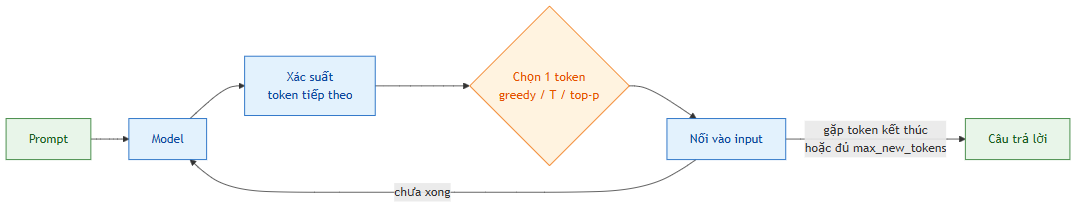


### 6.1 Sinh từng bước (autoregressive)
- **Mục đích:** cho thấy `generate()` thực chất là một vòng lặp: chạy model → lấy phân phối token tiếp theo → chọn 1 token → **nối vào input** → lặp lại. Ở đây chọn kiểu greedy (token xác suất cao nhất).
- **Đầu vào:** `model`, `tok`; `GEN_PROMPT` qua chat template.
- **Đầu ra:** `steps_df` (mỗi bước: token chọn, xác suất); `RESULTS_DIR/decoding_steps.csv`.
- **Kiểm:** vòng lặp tự viết phải ra **đúng các token** mà `model.generate(do_sample=False)` sinh ra.

In [38]:
# 6.1 Sinh từng bước: mỗi bước chạy model, lấy token xác suất cao nhất, nối vào input
PART06 = "part06_decoding"
log(f"=== PART 06 decoding START {now_iso()} ===", part=PART06)

GEN_PROMPT = "Viết một câu giới thiệu ngắn về thành phố Hà Nội."
gen_enc = tok.apply_chat_template([{"role": "user", "content": GEN_PROMPT}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(model.device)
n_gen_in = gen_enc["input_ids"].shape[1]
N_STEPS = 8

ids = gen_enc["input_ids"]
steps = []
with torch.no_grad():
    for step in range(1, N_STEPS + 1):
        logits = model(ids).logits[0, -1].float()        # điểm cho token tiếp theo (chỉ vị trí cuối)
        probs = torch.softmax(logits, dim=-1)            # điểm → xác suất
        p_top, next_id = probs.max(dim=-1)               # greedy: token xác suất cao nhất
        steps.append({"step": step, "token_id": int(next_id), "token": tok.decode([int(next_id)]),
                      "prob": round(float(p_top), 4), "n_input_tokens": ids.shape[1]})
        ids = torch.cat([ids, next_id.view(1, 1)], dim=1)  # nối token vừa chọn → input dài thêm 1 cho bước sau

steps_df = pd.DataFrame(steps)
steps_df.to_csv(RESULTS_DIR / "decoding_steps.csv", index=False, encoding="utf-8")
print(f"INPUT: {GEN_PROMPT!r} ({n_gen_in} token sau chat template)")
print(steps_df.to_string(index=False))
print("Ghép các token đã chọn:", repr("".join(steps_df["token"])))

# Tự kiểm: generate() greedy ra đúng các token của vòng lặp tự viết
with torch.no_grad():
    ref = model.generate(**gen_enc, max_new_tokens=N_STEPS, do_sample=False, temperature=None, top_p=None,
                         top_k=None, repetition_penalty=1.0, pad_token_id=tok.pad_token_id)
assert ref[0, n_gen_in:].tolist() == steps_df["token_id"].tolist(), (ref[0, n_gen_in:].tolist(), steps_df["token_id"].tolist())
assert steps_df["n_input_tokens"].tolist() == list(range(n_gen_in, n_gen_in + N_STEPS))  # mỗi bước input dài thêm 1
log(f"sinh từng bước {N_STEPS} bước: {''.join(steps_df['token'])!r} | khớp generate(): True", part=PART06)

=== PART 06 decoding START 2026-11-19T15:05:07+07:00 ===
INPUT: 'Viết một câu giới thiệu ngắn về thành phố Hà Nội.' (42 token sau chat template)
 step  token_id  token   prob  n_input_tokens
    1        39      H 0.8470              42
    2      6362      à 0.9978              43
    3    128685    Nội 0.9998              44
    4     37915     là 0.6741              45
    5     64061  thành 0.4623              46
    6    128974    phố 0.9997              47
    7    128465    lớn 0.6008              48
    8    128281   nhất 0.4073              49
Ghép các token đã chọn: 'Hà Nội là thành phố lớn nhất'
sinh từng bước 8 bước: 'Hà Nội là thành phố lớn nhất' | khớp generate(): True


### 6.2 Temperature và top-p làm gì với phân phối xác suất
- **Mục đích:** nhìn trực tiếp tác dụng lên **bước đầu tiên** của câu trả lời:
  - temperature T: chia logits cho T rồi mới softmax. T < 1 làm phân phối **nhọn** hơn (token đầu càng chắc), T > 1 làm **phẳng** hơn (token hiếm có cơ hội).
  - top-p: chỉ giữ nhóm token xác suất cao nhất có tổng ≥ p, rồi lấy mẫu trong nhóm đó. p càng nhỏ, nhóm càng ít token.
- **Đầu vào:** logits ở vị trí cuối của `gen_enc` (6.1).
- **Đầu ra:** `RESULTS_DIR/temperature_top_p.csv` (T, top-5 token và xác suất, số token cần để phủ p = 0.5 / 0.9 / 0.95).

Công thức:
- Temperature $T$: $p_i = \dfrac{e^{z_i / T}}{\sum_j e^{z_j / T}}$, với $z_i$ là logit của token $i$. $T = 1$ là softmax thường; greedy tương ứng $T \to 0$.
- Top-p: xếp token theo xác suất giảm dần, giữ tập nhỏ nhất $V_p$ có $\sum_{i \in V_p} p_i \ge p$, chia lại xác suất trong $V_p$ rồi lấy mẫu.

In [39]:
# 6.2 Phân phối token đầu tiên khi đổi temperature; số token trong nhóm top-p
TEMPS = [0.5, 1.0, 1.5]
TOP_PS = [0.5, 0.9, 0.95]

with torch.no_grad():
    logits0 = model(gen_enc["input_ids"]).logits[0, -1].float()


def nucleus_size(probs: torch.Tensor, p: float) -> int:
    """Số token ít nhất (xếp từ cao xuống) để tổng xác suất ≥ p: đó là nhóm token top-p được giữ lại."""
    cum = torch.cumsum(torch.sort(probs, descending=True).values, dim=0)
    return int((cum < p).sum()) + 1


rows = []
for T in TEMPS:
    probs_T = torch.softmax(logits0 / T, dim=-1)          # temperature: chia logits cho T trước softmax
    top = torch.topk(probs_T, 5)
    row = {"temperature": T}
    for r, (pid, pp) in enumerate(zip(top.indices.tolist(), top.values.tolist()), start=1):
        row[f"top{r}"] = f"{tok.decode([pid])!r} {pp:.3f}"
    for p in TOP_PS:
        row[f"n_token_top_p_{p}"] = nucleus_size(probs_T, p)
    rows.append(row)
temp_df = pd.DataFrame(rows)
temp_df.to_csv(RESULTS_DIR / "temperature_top_p.csv", index=False, encoding="utf-8")
print(temp_df.to_string(index=False))

# Tự kiểm: T nhỏ → token đầu chắc hơn; nhóm top-p lớn dần theo p; T = 1 là softmax thường
p_first = [float(torch.softmax(logits0 / T, dim=-1).max()) for T in TEMPS]
assert p_first[0] >= p_first[1] >= p_first[2], p_first
assert all(r["n_token_top_p_0.5"] <= r["n_token_top_p_0.9"] <= r["n_token_top_p_0.95"] for r in rows)
log("temperature → P(token đầu): " + ", ".join(f"T={T}: {p:.3f}" for T, p in zip(TEMPS, p_first))
    + " | số token phủ top-p 0.9 ở T=1: " + str(rows[1]["n_token_top_p_0.9"]), part=PART06)

 temperature      top1       top2      top3       top4       top5  n_token_top_p_0.5  n_token_top_p_0.9  n_token_top_p_0.95
         0.5 'H' 0.995 'Vi' 0.003 'Đ' 0.001 'Th' 0.000 '"H' 0.000                  1                  1                   1
         1.0 'H' 0.847 'Vi' 0.050 'Đ' 0.031 'Th' 0.008 '"H' 0.007                  1                  3                   7
         1.5 'H' 0.468 'Vi' 0.071 'Đ' 0.052 'Th' 0.021 '"H' 0.019                  2                135                1068
temperature → P(token đầu): T=0.5: 0.995, T=1.0: 0.847, T=1.5: 0.468 | số token phủ top-p 0.9 ở T=1: 3


### 6.3 Cùng một prompt, 5 cấu hình sinh, mỗi cấu hình 3 lần
- **Mục đích:** đúng minh họa của đề. Greedy luôn ra một kết quả; lấy mẫu (`do_sample=True`) mỗi lần một khác, và mức khác nhau tuỳ temperature, top-p.
- **Đầu vào:** `gen_enc` (6.1); `DECODING_CONFIGS`; seed `SEED + i` cho lần thứ i (chạy lại ra đúng kết quả cũ).
- **Đầu ra:** `RESULTS_DIR/decoding_samples.csv` (`config, sample, seed, do_sample, temperature, top_p, output, n_output_tokens, truncated, time_s`).
- Mọi tham số truyền tường minh. `top_k=0` = tắt top-k (bản Instruct mặc định `top_k=20`), để chỉ temperature và top-p có tác dụng.

In [40]:
# 6.3 Cùng prompt, 5 cấu hình, mỗi cấu hình N_SAMPLES lần
N_SAMPLES = 3
GEN_MAX_NEW_TOKENS = 60
DECODING_CONFIGS = {
    "greedy":     dict(do_sample=False, temperature=None, top_p=None, top_k=None),
    "temp_0.5":   dict(do_sample=True, temperature=0.5, top_p=1.0, top_k=0),   # top_p=1.0: không cắt nhóm
    "temp_1.5":   dict(do_sample=True, temperature=1.5, top_p=1.0, top_k=0),
    "top_p_0.5":  dict(do_sample=True, temperature=1.0, top_p=0.5, top_k=0),
    "top_p_0.95": dict(do_sample=True, temperature=1.0, top_p=0.95, top_k=0),
}
PART06_REC_COLS = ["idx", "config", "sample", "seed", "do_sample", "temperature", "top_p", "n_output_tokens",
                   "truncated", "output", "time_s"]
log(f"tham số: prompt={GEN_PROMPT!r} | max_new_tokens={GEN_MAX_NEW_TOKENS} | repetition_penalty=1.0 | "
    f"cấu hình={DECODING_CONFIGS} | {N_SAMPLES} lần/cấu hình, seed = {SEED} + i", part=PART06)
log("--- mỗi mẫu ---", part=PART06, echo=False)
log(",".join(PART06_REC_COLS), part=PART06, echo=False)

part06_records = []
for name, cfg_gen in DECODING_CONFIGS.items():
    print(f"==================== {name} ====================")
    for i in range(N_SAMPLES):
        torch.manual_seed(SEED + i)  # cố định bộ sinh ngẫu nhiên → chạy lại ra đúng mẫu này
        cuda_sync()
        t0 = time.perf_counter()
        with torch.no_grad():
            out = model.generate(**gen_enc, max_new_tokens=GEN_MAX_NEW_TOKENS, repetition_penalty=1.0,
                                 pad_token_id=tok.pad_token_id, **cfg_gen)
        cuda_sync()
        new_ids = out[0, n_gen_in:]
        text = tok.decode(new_ids, skip_special_tokens=True).strip()
        rec = {"idx": len(part06_records), "config": name, "sample": i + 1, "seed": SEED + i,
               "do_sample": cfg_gen["do_sample"], "temperature": cfg_gen["temperature"], "top_p": cfg_gen["top_p"],
               "n_output_tokens": len(new_ids), "truncated": len(new_ids) >= GEN_MAX_NEW_TOKENS,
               "output": text, "time_s": round(time.perf_counter() - t0, 2)}
        part06_records.append(rec)
        log(csv_line([rec[c] for c in PART06_REC_COLS]), part=PART06, echo=False)
        print(f"[lần {i + 1}, seed {SEED + i}] {text}")
    print()

dec_df = pd.DataFrame(part06_records, columns=PART06_REC_COLS)
dec_df.to_csv(RESULTS_DIR / "decoding_samples.csv", index=False, encoding="utf-8")
dec_df.to_csv(LOG_DIR / f"{PART06}_records.csv", index=False, encoding="utf-8")

# Tự kiểm: đủ dòng; greedy chạy mấy lần cũng ra một output
assert len(dec_df) == len(DECODING_CONFIGS) * N_SAMPLES
assert dec_df.loc[dec_df["config"] == "greedy", "output"].nunique() == 1

tham số: prompt='Viết một câu giới thiệu ngắn về thành phố Hà Nội.' | max_new_tokens=60 | repetition_penalty=1.0 | cấu hình={'greedy': {'do_sample': False, 'temperature': None, 'top_p': None, 'top_k': None}, 'temp_0.5': {'do_sample': True, 'temperature': 0.5, 'top_p': 1.0, 'top_k': 0}, 'temp_1.5': {'do_sample': True, 'temperature': 1.5, 'top_p': 1.0, 'top_k': 0}, 'top_p_0.5': {'do_sample': True, 'temperature': 1.0, 'top_p': 0.5, 'top_k': 0}, 'top_p_0.95': {'do_sample': True, 'temperature': 1.0, 'top_p': 0.95, 'top_k': 0}} | 3 lần/cấu hình, seed = 42 + i
==================== greedy ====================
[lần 1, seed 42] Hà Nội là thành phố lớn nhất và trung tâm chính trị, kinh tế, văn hóa của Việt Nam. Nơi đây nổi tiếng với những di tích lịch sử như Đền Hùng, Lăng Chủ tịch Hồ Chí Minh, và các công trình kiến trúc độc đáo như Nhà
[lần 2, seed 43] Hà Nội là thành phố lớn nhất và trung tâm chính trị, kinh tế, văn hóa của Việt Nam. Nơi đây nổi tiếng với những di tích lịch sử như Đền Hùng, Lă

### 6.4 Tổng kết phần 6
- **Mục đích:** đếm mỗi cấu hình ra bao nhiêu output **khác nhau** trong 3 lần (1 = lần nào cũng giống nhau).
- **Đầu vào:** `dec_df` (6.3).
- **Đầu ra:** bảng `n_distinct` theo cấu hình; dòng END và tổng kết trong log.

In [41]:
# 6.4 Số output khác nhau trong N_SAMPLES lần, theo cấu hình
distinct = dec_df.groupby("config", sort=False)["output"].nunique().rename("n_distinct")
print(distinct.to_string())

log(f"=== PART 06 decoding END {now_iso()} ===", part=PART06)
log(f"tổng kết: số output khác nhau / {N_SAMPLES} lần: {distinct.to_dict()} | "
    f"thời gian sinh {dec_df['time_s'].sum():.1f} s", part=PART06)
log(f"[{PART06}] OK {now_iso()} → results/decoding_steps.csv, results/temperature_top_p.csv, "
    f"results/decoding_samples.csv ({len(dec_df)} dòng)")

config
greedy        1
temp_0.5      3
temp_1.5      3
top_p_0.5     3
top_p_0.95    3
=== PART 06 decoding END 2026-11-19T15:05:42+07:00 ===
tổng kết: số output khác nhau / 3 lần: {'greedy': 1, 'temp_0.5': 3, 'temp_1.5': 3, 'top_p_0.5': 3, 'top_p_0.95': 3} | thời gian sinh 34.4 s
[part06_decoding] OK 2026-11-19T15:05:42+07:00 → results/decoding_steps.csv, results/temperature_top_p.csv, results/decoding_samples.csv (15 dòng)


**Phân tích** (normal run `20261119_150356_normal`):
- 6.1: `generate()` greedy ra đúng 8 token của vòng lặp tự viết ("Hà Nội là thành phố lớn nhất"); input dài thêm 1 token mỗi bước → sinh văn bản là lặp lại "đoán 1 token, nối vào, đoán tiếp". Xác suất token được chọn từ 0.41 (" nhất") đến 0.9998 (" Nội").
- 6.2: P(token đầu "H") = 0.995 ở T = 0.5, 0.847 ở T = 1.0, 0.468 ở T = 1.5. Số token cần để phủ 90% xác suất: 1 (T = 0.5), 3 (T = 1.0), 135 (T = 1.5) → T cao làm phân phối phẳng, token hiếm có cơ hội được chọn.
- 6.3: greedy 3 lần giống hệt nhau; temp_0.5 và top_p_0.5 ra 3 câu khác nhau nhưng đều đúng, mạch lạc; temp_1.5 ra chuỗi vô nghĩa lẫn nhiều ngôn ngữ (Ả Rập, Hàn, Trung…); top_p_0.95 có lần bịa ("Hà Nội … ở Trung Quốc") và lẫn chữ Hán.
- Mỗi cấu hình 3 lần (plan gốc 5; khung v4 chốt 3): 3 lần đã đủ thấy khác biệt, greedy 1 output, mọi cấu hình lấy mẫu 3 output khác nhau; 15 output vừa một slide.
- Kết luận: greedy dùng khi cần kết quả lặp lại được (đánh giá ở phần 7–9); lấy mẫu dùng khi cần đa dạng, đổi lại có thể sai hoặc lạc đề.

## Phần 7 — Zero-shot và few-shot

- Đề: so sánh zero-shot và few-shot **trên cùng tác vụ**. Tác vụ: phân loại cảm xúc 2 nhãn (positive / negative) trên UIT-VSFC (phản hồi sinh viên tiếng Việt).
- Thiết kế: **chỉ đổi một biến** là có ví dụ hay không. Cùng model, cùng mẫu prompt, greedy, `max_new_tokens = 10`, cùng tập câu test.
  - Test: toàn bộ 2,999 câu test 2 nhãn (`N_TEST = None`); nếu smoke run ước tính 2 cách > 20 phút thì đặt `N_TEST = 500` (250/250, seed 42).
  - Few-shot: **1 bộ 4 ví dụ** (2 positive + 2 negative, xen kẽ) lấy từ split train, không trùng câu test.
  - Mẫu prompt: thử 3 mẫu trên **validation** (200 câu, 100/100), chọn mẫu có accuracy trung bình (zero + few) cao nhất, **chốt rồi mới chạy test**.
- Đầu vào: `vsfc` (cell 0.7).
- Đầu ra: `results/vsfc_test_ids.csv`, `results/fewshot_examples.json`, `results/prompt_selection.csv`, `results/icl_zero_shot.csv`, `results/icl_few_shot.csv`; log `part07_icl.log`, `part07_icl_records.csv`.
- Phân tích kết quả (accuracy, confusion matrix, McNemar, phân tích lỗi) ở phần 10.

*Vì sao chỉ đổi một biến?* Nếu đổi cả mẫu prompt hay tập câu cùng lúc thì không biết chênh lệch accuracy đến từ đâu. Giữ mọi thứ giống nhau, chỉ thêm 4 ví dụ, thì chênh lệch là tác dụng của ví dụ.

*Vì sao greedy?* Greedy cho cùng một output mỗi lần chạy, nên kết quả lặp lại được và hai cách so được với nhau trên từng câu (cần cho McNemar ở phần 10).

### 7.1 Tập test, tập validation và ví dụ few-shot
- **Mục đích:** cố định câu dùng để đánh giá và 4 ví dụ few-shot; lưu lại để người khác chạy lại ra đúng số (sản phẩm nộp "bộ câu thử nghiệm").
- **Đầu vào:** `vsfc["test"]`, `vsfc["validation"]`, `vsfc["train"]`; `N_TEST`, `N_VAL_PROMPT`, `N_FEWSHOT`, `SEED`.
- **Đầu ra:** `test_df`, `val_df`, `FEWSHOT` (list 4 dict `sentence, label`); `RESULTS_DIR/vsfc_test_ids.csv`, `RESULTS_DIR/fewshot_examples.json`.
- `row_id` là số thứ tự của câu trong split **sau khi bỏ neutral** (cell 0.7); dữ liệu cố định nên chạy lại ra đúng câu.

In [42]:
# 7.1 Lấy câu test, câu validation và 4 ví dụ few-shot
PART07 = "part07_icl"
log(f"=== PART 07 icl START {now_iso()} ===", part=PART07)


def balanced_sample(df: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    """n câu, mỗi nhãn n/2, chọn ngẫu nhiên theo seed rồi xáo thứ tự; n = None → lấy hết."""
    df = df.rename_axis("row_id").reset_index()            # giữ số thứ tự gốc làm row_id
    if n is not None:
        df = pd.concat([g.sample(n // 2, random_state=seed) for _, g in df.groupby("sentiment")])
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


def norm_text(s: str) -> str:
    """Chuẩn hoá để so trùng: chữ thường, gộp khoảng trắng."""
    return " ".join(str(s).lower().split())


test_df = balanced_sample(vsfc["test"], N_TEST, SEED)
val_df = balanced_sample(vsfc["validation"], N_VAL_PROMPT, SEED)

# Ví dụ few-shot: từ train, bỏ câu trùng nội dung với test/validation, độ dài 5–20 từ (câu điển hình)
seen = set(vsfc["test"]["sentence"].map(norm_text)) | set(vsfc["validation"]["sentence"].map(norm_text))
pool = vsfc["train"][~vsfc["train"]["sentence"].map(norm_text).isin(seen)]
pool = pool[pool["sentence"].str.split().str.len().between(5, 20)]
pos = pool[pool["sentiment"] == 2].sample(N_FEWSHOT // 2, random_state=SEED)
neg = pool[pool["sentiment"] == 0].sample(N_FEWSHOT // 2, random_state=SEED)
FEWSHOT = []
for p_row, n_row in zip(pos.itertuples(), neg.itertuples()):   # xen kẽ positive, negative
    FEWSHOT += [{"sentence": p_row.sentence, "label": 2}, {"sentence": n_row.sentence, "label": 0}]

test_df[["row_id", "sentiment"]].to_csv(RESULTS_DIR / "vsfc_test_ids.csv", index=False, encoding="utf-8")
save_json({"source": "uitnlp/vietnamese_students_feedback, split train", "seed": SEED,
           "label_names": LABEL_NAMES, "examples": FEWSHOT}, RESULTS_DIR / "fewshot_examples.json")

counts = test_df["sentiment"].map(LABEL_NAMES).value_counts().to_dict()
log(f"test: {len(test_df):,} câu {counts} | validation chọn prompt: {len(val_df)} câu | "
    f"few-shot: {[(LABEL_NAMES[e['label']], e['sentence']) for e in FEWSHOT]}", part=PART07)

# Tự kiểm: cân bằng khi lấy mẫu; ví dụ few-shot không trùng câu test; đủ 2 nhãn, xen kẽ
if N_TEST is not None:
    assert counts == {"positive": N_TEST // 2, "negative": N_TEST // 2}, counts
assert not ({norm_text(e["sentence"]) for e in FEWSHOT} & set(test_df["sentence"].map(norm_text)))
assert [e["label"] for e in FEWSHOT] == [2, 0] * (N_FEWSHOT // 2)
assert balanced_sample(vsfc["test"], N_TEST, SEED)["row_id"].equals(test_df["row_id"])  # cùng seed → cùng câu

=== PART 07 icl START 2026-11-19T15:05:42+07:00 ===
test: 2,999 câu {'positive': 1590, 'negative': 1409} | validation chọn prompt: 200 câu | few-shot: [('positive', 'dạy tốt có tâm .'), ('negative', 'oop khá phức tạp nên cần nhiều ví dụ .'), ('positive', 'giáo viên tích cực , năng nổ trong giảng dạy , phương pháp dạy có phần đổi mới .'), ('negative', 'giảng viên cần linh hoạt trong giảng dạy , chuẩn bị bài giảng phong phú .')]


### 7.2 Mẫu prompt, dựng prompt, đọc nhãn từ output
- **Mục đích:** một hàm `build_prompt()` cho cả hai cách: danh sách ví dụ rỗng là zero-shot, có 4 ví dụ là few-shot. Hàm `parse_label()` đọc nhãn từ chữ model sinh ra.
- **Đầu vào:** `PROMPT_TEMPLATES` (3 mẫu, chưa chọn); `FEWSHOT` (7.1).
- **Đầu ra:** hàm `build_prompt()`, `parse_label()`; in 1 prompt zero-shot và 1 prompt few-shot.
- Luật đọc nhãn: chữ thường, bỏ dấu câu; chỉ có "positive"/"tích cực" → positive; chỉ có "negative"/"tiêu cực" → negative; có cả hai hoặc không có → `None` (không parse được, **tính là sai**).

In [43]:
# 7.2 Mẫu prompt, build_prompt, parse_label
import string

PROMPT_TEMPLATES = {
    "vi_nhan_en": {   # chỉ dẫn tiếng Việt, nhãn tiếng Anh
        "instruction": "Phân loại cảm xúc của câu phản hồi sinh viên sau. Chỉ trả lời một từ: positive hoặc negative.",
        "item": 'Câu: "{text}"\nCảm xúc:', "labels": {2: "positive", 0: "negative"}},
    "vi_nhan_vi": {   # chỉ dẫn tiếng Việt, nhãn tiếng Việt
        "instruction": "Phân loại cảm xúc của câu phản hồi sinh viên sau. Chỉ trả lời: tích cực hoặc tiêu cực.",
        "item": 'Câu: "{text}"\nCảm xúc:', "labels": {2: "tích cực", 0: "tiêu cực"}},
    "en_nhan_en": {   # chỉ dẫn tiếng Anh, nhãn tiếng Anh
        "instruction": "Classify the sentiment of the following Vietnamese student feedback. "
                       "Answer with one word: positive or negative.",
        "item": 'Sentence: "{text}"\nSentiment:', "labels": {2: "positive", 0: "negative"}},
}


def build_prompt(text: str, examples: list[dict], tpl: dict) -> str:
    """Chỉ dẫn + (các ví dụ có nhãn) + câu cần phân loại. examples = [] → zero-shot."""
    blocks = [tpl["instruction"]]
    blocks += [tpl["item"].format(text=e["sentence"]) + " " + tpl["labels"][e["label"]] for e in examples]
    blocks.append(tpl["item"].format(text=text))
    return "\n\n".join(blocks)


def parse_label(output: str) -> int | None:
    """Đọc nhãn từ output: 2 = positive, 0 = negative, None = không parse được."""
    s = " ".join(output.lower().translate(str.maketrans("", "", string.punctuation)).split())
    has_pos = "positive" in s or "tích cực" in s
    has_neg = "negative" in s or "tiêu cực" in s
    if has_pos == has_neg:   # có cả hai, hoặc không có nhãn nào
        return None
    return 2 if has_pos else 0


# Tự kiểm parse_label và build_prompt
assert parse_label("Positive.") == 2 and parse_label("negative") == 0
assert parse_label("Tích cực") == 2 and parse_label("tiêu cực.") == 0
assert parse_label("positive negative") is None and parse_label("Tôi không chắc") is None
for tpl in PROMPT_TEMPLATES.values():
    zs = build_prompt("Thầy dạy hay.", [], tpl)
    fs = build_prompt("Thầy dạy hay.", FEWSHOT, tpl)
    assert fs.startswith(tpl["instruction"]) and fs.endswith(zs.split("\n\n")[-1])  # chỉ khác phần ví dụ
    assert fs.count("\n\n") == zs.count("\n\n") + len(FEWSHOT)

print("=== ZERO-SHOT (mẫu vi_nhan_en) ===\n" + build_prompt(test_df["sentence"][0], [], PROMPT_TEMPLATES["vi_nhan_en"]))
print("\n=== FEW-SHOT (mẫu vi_nhan_en) ===\n" + build_prompt(test_df["sentence"][0], FEWSHOT, PROMPT_TEMPLATES["vi_nhan_en"]))

=== ZERO-SHOT (mẫu vi_nhan_en) ===
Phân loại cảm xúc của câu phản hồi sinh viên sau. Chỉ trả lời một từ: positive hoặc negative.

Câu: "sử dụng website môn học , trang thiết bị phục vu giảng dạy còn hạn chế máy chiếu quá mờ , phòng học bị nắng ."
Cảm xúc:

=== FEW-SHOT (mẫu vi_nhan_en) ===
Phân loại cảm xúc của câu phản hồi sinh viên sau. Chỉ trả lời một từ: positive hoặc negative.

Câu: "dạy tốt có tâm ."
Cảm xúc: positive

Câu: "oop khá phức tạp nên cần nhiều ví dụ ."
Cảm xúc: negative

Câu: "giáo viên tích cực , năng nổ trong giảng dạy , phương pháp dạy có phần đổi mới ."
Cảm xúc: positive

Câu: "giảng viên cần linh hoạt trong giảng dạy , chuẩn bị bài giảng phong phú ."
Cảm xúc: negative

Câu: "sử dụng website môn học , trang thiết bị phục vu giảng dạy còn hạn chế máy chiếu quá mờ , phòng học bị nắng ."
Cảm xúc:


### 7.3 Phân loại theo lô (batch)
- **Mục đích:** sinh nhiều câu cùng lúc cho nhanh (`BATCH_SIZE` câu một lần chạy model), để chạy được toàn bộ tập test.
- **Đầu vào:** list prompt; `model`, `tok`.
- **Đầu ra:** hàm `classify_batch()` (list output), `run_icl()` (DataFrame mỗi câu một dòng: `row_id, sentence, label, output, pred, correct`).
- **Đệm bên trái (`padding_side="left"`):** các prompt dài ngắn khác nhau phải đệm cho bằng nhau. Đệm bên trái để token cuối của mọi prompt nằm cùng vị trí, model sinh tiếp ngay sau prompt; `attention_mask` báo model bỏ qua phần đệm.
- Greedy (`do_sample=False`), `repetition_penalty=1.0`, `max_new_tokens = 10` (nhãn tiếng Anh 1–2 token; nhãn tiếng Việt cần nhiều hơn, 5 token thì bị cắt mất nhãn).

In [44]:
# 7.3 Phân loại theo lô, greedy
ICL_MAX_NEW_TOKENS = 10  # smoke 19/11: 5 token cắt mất nhãn tiếng Việt ("tiêu cực"), mẫu vi_nhan_vi không parse được 60%


def classify_batch(prompts: list[str]) -> list[str]:
    """Sinh greedy cho một lô prompt (mỗi prompt là một lượt user trong chat template)."""
    texts = [tok.apply_chat_template([{"role": "user", "content": p}], add_generation_prompt=True, tokenize=False)
             for p in prompts]
    old_side = tok.padding_side
    tok.padding_side = "left"                       # đệm bên trái: model sinh tiếp ngay sau token cuối của prompt
    try:
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    finally:
        tok.padding_side = old_side                 # trả lại như cũ cho các phần khác
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=ICL_MAX_NEW_TOKENS, do_sample=False,
                             temperature=None, top_p=None, top_k=None, repetition_penalty=1.0,
                             pad_token_id=tok.pad_token_id)
    n_in = enc["input_ids"].shape[1]                # mọi prompt đã đệm cùng độ dài
    return [tok.decode(o[n_in:], skip_special_tokens=True).strip() for o in out]


def run_icl(df: pd.DataFrame, examples: list[dict], tpl: dict) -> tuple[pd.DataFrame, float]:
    """Phân loại mọi câu trong df; trả (bảng kết quả, số giây)."""
    outputs = []
    cuda_sync()
    t0 = time.perf_counter()
    for start in range(0, len(df), BATCH_SIZE):
        batch = df["sentence"].iloc[start:start + BATCH_SIZE]
        outputs += classify_batch([build_prompt(s, examples, tpl) for s in batch])
    cuda_sync()
    res = df[["row_id", "sentence", "sentiment"]].rename(columns={"sentiment": "label"}).copy()
    res["output"] = outputs
    res["pred"] = res["output"].map(parse_label)
    res["correct"] = res["pred"] == res["label"]    # None ≠ nhãn nào → tính là sai
    return res, time.perf_counter() - t0


# Tự kiểm: greedy chạy 2 lần cùng lô ra cùng output; đủ số output
probe = [build_prompt(s, FEWSHOT, PROMPT_TEMPLATES["vi_nhan_en"]) for s in val_df["sentence"][:4]]
assert classify_batch(probe) == classify_batch(probe)
assert len(classify_batch(probe[:1])) == 1

### 7.4 Chọn mẫu prompt trên validation
- **Mục đích:** chọn mẫu prompt **trước** khi nhìn tập test, để kết quả test không bị "chọn theo đáp án".
- **Đầu vào:** `val_df` (7.1), 3 mẫu trong `PROMPT_TEMPLATES`, `FEWSHOT`.
- **Đầu ra:** `CHOSEN_TEMPLATE`; `RESULTS_DIR/prompt_selection.csv` (`template, mode, accuracy, unparsed_rate`).
- Luật chọn: accuracy trung bình của zero-shot và few-shot cao nhất; bằng nhau thì lấy mẫu đứng trước trong danh sách.

In [45]:
# 7.4 Thử 3 mẫu prompt trên validation, chốt 1 mẫu
sel_rows = []
for tname, tpl in PROMPT_TEMPLATES.items():
    for mode, ex in [("zero_shot", []), ("few_shot", FEWSHOT)]:
        res, sec = run_icl(val_df, ex, tpl)
        sel_rows.append({"template": tname, "mode": mode, "accuracy": round(float(res["correct"].mean()), 4),
                         "unparsed_rate": round(float(res["pred"].isna().mean()), 4), "time_s": round(sec, 1)})
sel_df = pd.DataFrame(sel_rows)
sel_df.to_csv(RESULTS_DIR / "prompt_selection.csv", index=False, encoding="utf-8")
print(sel_df.to_string(index=False))

mean_acc = sel_df.groupby("template", sort=False)["accuracy"].mean()
CHOSEN_TEMPLATE = mean_acc.idxmax()                 # idxmax lấy mẫu đầu tiên nếu bằng nhau
print(f"\nAccuracy trung bình theo mẫu: {mean_acc.round(4).to_dict()} → chọn: {CHOSEN_TEMPLATE}")
log(f"chọn prompt trên validation ({len(val_df)} câu): {sel_rows} → {CHOSEN_TEMPLATE}", part=PART07)

assert len(sel_df) == 2 * len(PROMPT_TEMPLATES)

  template      mode  accuracy  unparsed_rate  time_s
vi_nhan_en zero_shot     0.840            0.0     4.2
vi_nhan_en  few_shot     0.905            0.0     8.2
vi_nhan_vi zero_shot     0.845            0.0     5.1
vi_nhan_vi  few_shot     0.905            0.0    11.0
en_nhan_en zero_shot     0.825            0.0     3.9
en_nhan_en  few_shot     0.870            0.0     7.2

Accuracy trung bình theo mẫu: {'vi_nhan_en': 0.8725, 'vi_nhan_vi': 0.875, 'en_nhan_en': 0.8475} → chọn: vi_nhan_vi
chọn prompt trên validation (200 câu): [{'template': 'vi_nhan_en', 'mode': 'zero_shot', 'accuracy': 0.84, 'unparsed_rate': 0.0, 'time_s': 4.2}, {'template': 'vi_nhan_en', 'mode': 'few_shot', 'accuracy': 0.905, 'unparsed_rate': 0.0, 'time_s': 8.2}, {'template': 'vi_nhan_vi', 'mode': 'zero_shot', 'accuracy': 0.845, 'unparsed_rate': 0.0, 'time_s': 5.1}, {'template': 'vi_nhan_vi', 'mode': 'few_shot', 'accuracy': 0.905, 'unparsed_rate': 0.0, 'time_s': 11.0}, {'template': 'en_nhan_en', 'mode': 'zero_shot', 

### 7.5 Chạy trên tập test: zero-shot và few-shot
- **Mục đích:** chạy 2 cách trên **cùng** các câu test với mẫu prompt đã chốt.
- **Đầu vào:** `test_df` (7.1), `CHOSEN_TEMPLATE` (7.4), `FEWSHOT`.
- **Đầu ra:** `icl_zero`, `icl_few`; `RESULTS_DIR/icl_zero_shot.csv`, `RESULTS_DIR/icl_few_shot.csv`; `LOG_DIR/part07_icl_records.csv` (mỗi câu × mỗi cách một dòng).
- Smoke run in **ước tính thời gian** cho toàn bộ 2,999 câu để áp luật chọn số câu (≤ 20 phút thì chạy hết, không thì đặt `N_TEST = 500`).

In [46]:
# 7.5 Zero-shot và few-shot trên cùng tập test
tpl = PROMPT_TEMPLATES[CHOSEN_TEMPLATE]
log(f"tham số: model={MODEL_INSTRUCT} | mẫu prompt={CHOSEN_TEMPLATE} | do_sample=False | "
    f"max_new_tokens={ICL_MAX_NEW_TOKENS} | repetition_penalty=1.0 | batch={BATCH_SIZE} | "
    f"few-shot={len(FEWSHOT)} ví dụ", part=PART07)
log(f"dữ liệu vào: UIT-VSFC test, {len(test_df):,} câu (results/vsfc_test_ids.csv)", part=PART07)

icl_zero, sec_zero = run_icl(test_df, [], tpl)
icl_few, sec_few = run_icl(test_df, FEWSHOT, tpl)
icl_zero.to_csv(RESULTS_DIR / "icl_zero_shot.csv", index=False, encoding="utf-8")
icl_few.to_csv(RESULTS_DIR / "icl_few_shot.csv", index=False, encoding="utf-8")

records7 = pd.concat([icl_zero.assign(mode="zero_shot"), icl_few.assign(mode="few_shot")], ignore_index=True)
records7.insert(0, "idx", range(len(records7)))
records7.to_csv(LOG_DIR / f"{PART07}_records.csv", index=False, encoding="utf-8")
log("--- mỗi mẫu: xem part07_icl_records.csv ---", part=PART07, echo=False)

per_sent = (sec_zero + sec_few) / (2 * len(test_df))
print(f"zero-shot: accuracy {icl_zero['correct'].mean():.4f} | không parse được {icl_zero['pred'].isna().mean():.4f} | {sec_zero:.1f} s")
print(f"few-shot : accuracy {icl_few['correct'].mean():.4f} | không parse được {icl_few['pred'].isna().mean():.4f} | {sec_few:.1f} s")
print(f"Ước tính 2 cách × {len(vsfc['test']):,} câu: {per_sent * 2 * len(vsfc['test']) / 60:.1f} phút "
      f"({per_sent:.3f} s/câu/cách)")
print("\nVí dụ output thật (3 câu đầu):")
for i in range(min(3, len(test_df))):
    print(f"- {icl_zero['sentence'][i]!r} | nhãn {LABEL_NAMES[icl_zero['label'][i]]} | "
          f"zero: {icl_zero['output'][i]!r} | few: {icl_few['output'][i]!r}")

log(f"=== PART 07 icl END {now_iso()} ===", part=PART07)
log(f"tổng kết: accuracy zero {icl_zero['correct'].mean():.4f} / few {icl_few['correct'].mean():.4f} | "
    f"thời gian {sec_zero + sec_few:.1f} s ({per_sent:.3f} s/câu/cách)", part=PART07)
log(f"[{PART07}] OK {now_iso()} → results/icl_zero_shot.csv, results/icl_few_shot.csv ({len(test_df):,} câu mỗi file)")

# Tự kiểm: cùng câu, cùng thứ tự ở hai cách
assert icl_zero["row_id"].equals(icl_few["row_id"]) and len(icl_zero) == len(test_df)

tham số: model=Qwen/Qwen2.5-1.5B-Instruct | mẫu prompt=vi_nhan_vi | do_sample=False | max_new_tokens=10 | repetition_penalty=1.0 | batch=16 | few-shot=4 ví dụ
dữ liệu vào: UIT-VSFC test, 2,999 câu (results/vsfc_test_ids.csv)
zero-shot: accuracy 0.8986 | không parse được 0.0000 | 76.7 s
few-shot : accuracy 0.9230 | không parse được 0.0000 | 162.2 s
Ước tính 2 cách × 2,999 câu: 4.0 phút (0.040 s/câu/cách)

Ví dụ output thật (3 câu đầu):
- 'sử dụng website môn học , trang thiết bị phục vu giảng dạy còn hạn chế máy chiếu quá mờ , phòng học bị nắng .' | nhãn negative | zero: 'Tiêu cực' | few: 'Cảm xúc: tiêu cực'
- 'tăng tiết môn học thực hành , mở rộng bài tập để ứng dụng vào thực tế .' | nhãn negative | zero: 'Tích cực' | few: 'Tích cực'
- 'chương trình giảng dạy cần được phân bố hợp lý và được cập nhật .' | nhãn negative | zero: 'Tích cực' | few: 'Cảm xúc: tích cực'
=== PART 07 icl END 2026-11-19T15:10:21+07:00 ===
tổng kết: accuracy zero 0.8986 / few 0.9230 | thời gian 238.8 s (0.040 s/c

**Phân tích** (normal run `20261119_150356_normal`):
- 7.4: trên 200 câu validation, mẫu `vi_nhan_vi` (nhãn tiếng Việt) có accuracy trung bình cao nhất 0.875 (zero 0.845, few 0.905), sát `vi_nhan_en` 0.8725; `en_nhan_en` 0.8475. Không mẫu nào có câu không parse được.
- 7.5: trên 2,999 câu test, zero-shot 89.86%, few-shot 92.30%; cùng câu, cùng mẫu prompt, chỉ khác 4 ví dụ.
- Few-shot không dạy kiến thức mới (trọng số không đổi), chỉ cho model thấy tác vụ và **cách gán nhãn của bộ dữ liệu**: 2 ví dụ negative đều là góp ý ("… cần nhiều ví dụ", "… cần linh hoạt …"). Có ý nghĩa thống kê hay không: McNemar ở phần 10.
- Giới hạn: 1 bộ ví dụ few-shot; đổi ví dụ hoặc thứ tự ví dụ có thể cho kết quả khác (Zhao et al., 2021).

## Phần 8 — RAG

- Đề: phân biệt prompting, fine-tuning, RAG (bảng so sánh trên slide). Demo: **cùng câu hỏi, không RAG và có RAG**.
- Dữ liệu: **UIT-ViQuAD 2.0** (đọc hiểu tiếng Việt từ Wikipedia, VLSP 2021), split validation: mỗi dòng có `title, context, question, answers, is_impossible`.
  - Kho tài liệu: mọi đoạn `context` khác nhau của split validation.
  - Câu hỏi: `N_QA` câu có đáp án ngắn (≤ 4 từ) + `N_QA_IMPOSSIBLE` câu mà đoạn văn **không có** đáp án (`is_impossible`), seed 42.
- Hai cách nhận **cùng một câu dặn**: *"Nếu không biết hoặc tài liệu không có thông tin, trả lời 'Không có thông tin'."* Chỉ khác: cách có RAG được đưa thêm 3 đoạn do TF-IDF tìm ra.
- Đầu ra: `results/rag_questions_used.csv`, `results/rag_results.csv`; log `part08_rag.log`, `part08_rag_records.csv`.

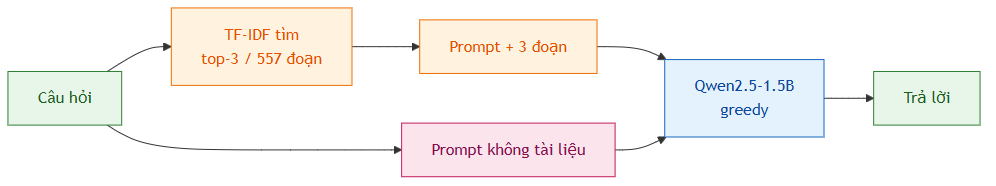
| Cách | Đổi gì | Dữ liệu cần | Dùng khi |
|---|---|---|---|
| Prompting | Chỉ đổi câu hỏi, chỉ dẫn, ví dụ (phần 7) | Vài ví dụ | Tác vụ model đã biết làm |
| Fine-tuning | Đổi trọng số model | Tập (input, output) có nhãn, GPU để train | Cần đổi hành vi hoặc văn phong lâu dài |
| RAG | Đưa tài liệu vào prompt lúc hỏi, không đổi trọng số | Kho tài liệu + bộ tìm kiếm | Tri thức mới, riêng, hay thay đổi; cần dẫn nguồn |

### 8.1 Tải UIT-ViQuAD 2.0, chọn câu hỏi, dựng kho tài liệu
- **Mục đích:** lấy câu hỏi tiếng Việt có đáp án và nguồn (đoạn Wikipedia) sẵn, không phải soạn tay.
- **Đầu vào:** `VIQUAD_URL` (cell 0.1), `N_QA`, `N_QA_IMPOSSIBLE`, `SEED`; `VIQUAD_EXCLUDE_IDS` (id câu Toàn loại sau khi đọc, ví dụ câu mơ hồ khi bỏ đoạn văn).
- **Đầu ra:** `corpus` (mỗi đoạn một dòng: `doc_id, title, context`), `qa_df` (câu hỏi đã chọn + `gold_doc_id`); `RESULTS_DIR/rag_questions_used.csv`.
- Lọc câu tự đủ nghĩa: bỏ câu có đại từ ("ông ấy", "nó", "đó"…); câu hỏi ≥ 7 từ. Mọi câu đều được ghi kèm **chủ đề** (`title`) khi hỏi, để không mơ hồ.

In [47]:
# 8.1 UIT-ViQuAD 2.0: câu hỏi + kho tài liệu
from huggingface_hub import dataset_info

PART08 = "part08_rag"
log(f"=== PART 08 rag START {now_iso()} ===", part=PART08)

VIQUAD_EXCLUDE_IDS: list[str] = []   # Toàn điền id câu cần loại sau khi đọc rag_questions_used.csv
PRONOUN_RE = r"\b(?:ông ấy|bà ấy|anh ấy|cô ấy|nó|họ|hắn|ông ta|bà ta|người này|nơi này|điều này|việc này|đó)\b"

viquad = pd.read_parquet(VIQUAD_URL)
VIQUAD_REVISION = dataset_info("taidng/UIT-ViQuAD2.0").sha
viquad["answer_list"] = viquad["answers"].map(lambda a: [str(x) for x in a["text"]])
log(f"UIT-ViQuAD 2.0 validation (revision {VIQUAD_REVISION}): {len(viquad):,} câu hỏi, "
    f"{viquad['context'].nunique()} đoạn, {viquad['title'].nunique()} chủ đề, "
    f"{int(viquad['is_impossible'].sum()):,} câu không có đáp án", part=PART08)

# Kho tài liệu: mỗi đoạn context khác nhau là một tài liệu
corpus = viquad[["title", "context"]].drop_duplicates("context").reset_index(drop=True)
corpus["doc_id"] = range(len(corpus))
viquad["gold_doc_id"] = viquad["context"].map(dict(zip(corpus["context"], corpus["doc_id"])))

# Lọc câu hỏi tự đủ nghĩa
ok_q = (~viquad["question"].map(lambda q: bool(re.search(PRONOUN_RE, q, flags=re.IGNORECASE)))  # re của Python: \b hiểu chữ có dấu
        & (viquad["question"].str.split().str.len() >= 7) & ~viquad["id"].isin(VIQUAD_EXCLUDE_IDS))
short_ans = viquad["answer_list"].map(lambda a: len(a) > 0 and min(len(x.split()) for x in a) <= 4)
answerable = viquad[ok_q & ~viquad["is_impossible"] & short_ans].sample(N_QA, random_state=SEED)
impossible = viquad[ok_q & viquad["is_impossible"]].sample(N_QA_IMPOSSIBLE, random_state=SEED)
qa_df = pd.concat([answerable, impossible]).reset_index(drop=True)
QA_COLS = ["id", "title", "question", "answer_list", "is_impossible", "gold_doc_id"]
qa_df[QA_COLS].to_csv(RESULTS_DIR / "rag_questions_used.csv", index=False, encoding="utf-8")
print(qa_df[["id", "title", "question", "answer_list", "is_impossible"]].to_string(index=False))

# Tự kiểm: đủ số câu; câu có đáp án thì có ít nhất 1 đáp án; đoạn gốc nằm trong kho
assert len(qa_df) == N_QA + N_QA_IMPOSSIBLE
assert qa_df.loc[~qa_df["is_impossible"], "answer_list"].map(len).gt(0).all()
assert qa_df["gold_doc_id"].isin(corpus["doc_id"]).all()

=== PART 08 rag START 2026-11-19T15:10:21+07:00 ===
UIT-ViQuAD 2.0 validation (revision 406f09a45cc106a8f7b7fd0c25078883fe58cb1f): 3,814 câu hỏi, 557 đoạn, 19 chủ đề, 1,161 câu không có đáp án
            id                    title                                                                                                 question                                                                           answer_list  is_impossible
0014-0004-0002 Đế quốc La Mã Thần thánh                                                             Muốn ban hành luật thì hoàng đế phải làm gì?                                         [phải thông qua Hội đồng, thông qua Hội đồng]          False
0015-0028-0002                  Mông Cổ                                               Trong GDP thì các ngành nông nghiệp chiếm tỷ lệ bao nhiêu?                                                                               [20.4%]          False
0004-0049-0002    Chiến tranh Vùng Vịnh                              

### 8.2 Tìm đoạn liên quan bằng TF-IDF (bước "Retrieval" của RAG)
- **Mục đích:** với mỗi câu hỏi, lấy 3 đoạn giống câu hỏi nhất trong kho.
- **Cách làm:** TF-IDF biến mỗi đoạn thành vector đếm từ (từ hiếm trong kho được trọng số cao); `ngram_range=(1, 2)` đếm cả cặp 2 âm tiết liền nhau (tiếng Việt nhiều từ ghép). Độ giống = cosine giữa vector câu hỏi và vector đoạn.
- **Đầu vào:** `corpus`, `qa_df` (8.1). Truy vấn = chủ đề + câu hỏi.
- **Đầu ra:** hàm `retrieve()`; cột `top3_doc_ids`, `hit@3` (đoạn gốc có nằm trong top-3 không) trong `qa_df`.

In [48]:
# 8.2 TF-IDF top-3
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

RAG_TOP_K = 3
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
doc_matrix = vectorizer.fit_transform(corpus["title"] + ". " + corpus["context"])  # (số đoạn, số từ/cụm từ)


def retrieve(query: str, k: int = RAG_TOP_K) -> list[int]:
    """doc_id của k đoạn giống query nhất (cosine trên vector TF-IDF)."""
    scores = linear_kernel(vectorizer.transform([query]), doc_matrix)[0]  # vector đã chuẩn hoá → tích vô hướng = cosine
    return scores.argsort()[::-1][:k].tolist()


qa_df["query"] = qa_df["title"] + ": " + qa_df["question"]
qa_df["top3_doc_ids"] = qa_df["query"].map(retrieve)
qa_df["hit@3"] = [g in top for g, top in zip(qa_df["gold_doc_id"], qa_df["top3_doc_ids"])]
recall3 = qa_df["hit@3"].mean()
print(f"Kho: {doc_matrix.shape[0]} đoạn × {doc_matrix.shape[1]:,} từ/cụm từ | recall@3 = {recall3:.3f}")
log(f"TF-IDF ngram (1, 2), top-{RAG_TOP_K}: recall@3 = {recall3:.3f} ({int(qa_df['hit@3'].sum())}/{len(qa_df)})", part=PART08)

# Tự kiểm: mỗi câu đúng 3 đoạn, không trùng; tìm chính một đoạn trong kho phải ra đoạn đó đứng đầu
assert qa_df["top3_doc_ids"].map(lambda t: len(set(t)) == RAG_TOP_K).all()
assert retrieve(corpus["title"][0] + ". " + corpus["context"][0])[0] == 0

Kho: 557 đoạn × 49,750 từ/cụm từ | recall@3 = 0.722
TF-IDF ngram (1, 2), top-3: recall@3 = 0.722 (13/18)


### 8.3 Hỏi không RAG và có RAG
- **Mục đích:** cùng câu hỏi, cùng câu dặn, cùng greedy; chỉ khác có / không có 3 đoạn tài liệu (bước "Augmented Generation").
- **Đầu vào:** `qa_df` (8.2), `corpus`; hàm `generate_greedy()` (cell 5.3).
- **Đầu ra:** hàm `ask()` (dùng lại ở phần 9); `rag_runs` (mỗi câu × 2 cách một dòng).
- `repetition_penalty=1.0`, `max_new_tokens = 48`.

In [49]:
# 8.3 Không RAG vs có RAG, cùng câu dặn
QA_MAX_NEW_TOKENS = 48
REFUSE_TEXT = "Không có thông tin"
REFUSE_RULE = f"Nếu không biết hoặc tài liệu không có thông tin, trả lời '{REFUSE_TEXT}'."


def ask(prompt: str, max_new_tokens: int = QA_MAX_NEW_TOKENS) -> tuple[str, int, int, float]:
    """Hỏi model chính (chat template, greedy, repetition_penalty 1.0); trả (output, token vào, token ra, giây)."""
    enc = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(model.device)
    out, n_out, sec = generate_greedy(model, tok, enc, max_new_tokens, repetition_penalty=1.0)
    return out, enc["input_ids"].shape[1], n_out, sec


def prompt_no_rag(r) -> str:
    return f"Trả lời ngắn gọn câu hỏi sau (chủ đề: {r.title}). {REFUSE_RULE}\n\nCâu hỏi: {r.question}"


def prompt_rag(r) -> str:
    docs = "\n".join(f"[{i + 1}] {corpus['context'][d]}" for i, d in enumerate(r.top3_doc_ids))
    return (f"Dựa vào tài liệu dưới đây, trả lời ngắn gọn câu hỏi (chủ đề: {r.title}). {REFUSE_RULE}\n\n"
            f"Tài liệu:\n{docs}\n\nCâu hỏi: {r.question}")


PART08_REC_COLS = ["idx", "id", "mode", "n_input_tokens", "n_output_tokens", "truncated", "output", "time_s"]
log(f"tham số: do_sample=False | repetition_penalty=1.0 | max_new_tokens={QA_MAX_NEW_TOKENS} | "
    f"câu dặn chung: {REFUSE_RULE!r}", part=PART08)
log("--- mỗi mẫu ---", part=PART08, echo=False)
log(",".join(PART08_REC_COLS), part=PART08, echo=False)

rag_runs = []
for r in qa_df.itertuples():
    for mode, build in [("no_rag", prompt_no_rag), ("rag", prompt_rag)]:
        out, n_in, n_out, sec = ask(build(r))
        rec = {"idx": len(rag_runs), "id": r.id, "mode": mode, "n_input_tokens": n_in, "n_output_tokens": n_out,
               "truncated": n_out >= QA_MAX_NEW_TOKENS, "output": out, "time_s": round(sec, 2)}
        rag_runs.append(rec)
        log(csv_line([rec[c] for c in PART08_REC_COLS]), part=PART08, echo=False)
rag_runs = pd.DataFrame(rag_runs, columns=PART08_REC_COLS)
rag_runs.to_csv(LOG_DIR / f"{PART08}_records.csv", index=False, encoding="utf-8")

print("Prompt có RAG (câu đầu, rút gọn):\n" + prompt_rag(next(qa_df.itertuples()))[:600] + " …")
assert len(rag_runs) == 2 * len(qa_df)

tham số: do_sample=False | repetition_penalty=1.0 | max_new_tokens=48 | câu dặn chung: "Nếu không biết hoặc tài liệu không có thông tin, trả lời 'Không có thông tin'."
Prompt có RAG (câu đầu, rút gọn):
Dựa vào tài liệu dưới đây, trả lời ngắn gọn câu hỏi (chủ đề: Đế quốc La Mã Thần thánh). Nếu không biết hoặc tài liệu không có thông tin, trả lời 'Không có thông tin'.

Tài liệu:
[1] Đế quốc thành hình vào năm 962, khi Otto I Đại Đế thuộc dòng họ Liudolfinger được Giáo hoàng trao Đế miện từ Vương quốc Đông Frank thuộc dòng họ Nhà Carolingien (Carolingian dynasty). Từ năm 1157, đế quốc này có tên là Sacrum Imperium và vào năm 1254, lần đầu tiên tên Sacrum Romanum Imperium được chứng minh trong một văn kiện. Trong thế kỷ 15 và thế kỷ 16 danh hiệu được bổ sung thêm dòng Dân tộc Đức, trở thành Đế q …


### 8.4 Chấm và ghi `rag_results.csv`
- **Mục đích:** chấm tự động theo luật ghi sẵn, sau đó Toàn đọc lại từng câu (sửa trong `MANUAL_JUDGE8` nếu luật tự động sai).
- **Luật** (chuẩn hoá: chữ thường, bỏ dấu câu, gộp khoảng trắng):
  - Câu có đáp án: output chứa một đáp án đúng → **Đúng**; chứa "không có thông tin" → **Từ chối**; còn lại → **Sai**.
  - Câu tài liệu không có đáp án: **Từ chối** là đúng hành vi; trả lời khác → **Sai** (bịa).
- **Đầu vào:** `rag_runs` (8.3), `qa_df`.
- **Đầu ra:** `RESULTS_DIR/rag_results.csv` (`id, title, question, answer_list, is_impossible, hit@3, mode, output, judged, judge_note`); bảng đếm theo cách.

In [50]:
# 8.4 Chấm: Đúng / Sai / Từ chối
MANUAL_JUDGE8: dict[str, tuple[str, str]] = {   # khoá "<id>|<no_rag hoặc rag>": ("Đúng" | "Sai" | "Từ chối", lý do); Toàn đọc lại 19/11
    "0004-0049-0002|rag": ("Đúng", "trả lời 'AGM-130' = đáp án 'tên lửa AGM-130', chỉ thiếu chữ 'tên lửa'"),
    "0013-0006-0001|rag": ("Đúng", "1649 đúng thực tế; đáp án gốc '1640' là nhãn sai (đoạn nguồn: 'quốc hội năm 1640')"),
}


def norm_answer(s: str) -> str:
    """Chữ thường, dấu câu thành khoảng trắng, gộp khoảng trắng (để so khớp đáp án).
    Dấu câu thành khoảng trắng chứ không xoá: 'Charles-de-Gaulle' → 'charles de gaulle' khớp 'Charles de Gaulle'."""
    return " ".join(str(s).lower().translate(str.maketrans(string.punctuation, " " * len(string.punctuation))).split())


def judge_qa(output: str, answers: list[str], impossible: bool) -> str:
    """Chấm tự động một câu trả lời theo luật ghi sẵn."""
    out = norm_answer(output)
    refused = norm_answer(REFUSE_TEXT) in out
    if impossible:
        return "Từ chối" if refused else "Sai"
    if any(norm_answer(a) in out for a in answers):
        return "Đúng"
    return "Từ chối" if refused else "Sai"


rag_df = rag_runs.merge(qa_df[["id", "title", "question", "answer_list", "is_impossible", "hit@3"]], on="id")
rag_df["judged"] = [judge_qa(o, a, imp) for o, a, imp in zip(rag_df["output"], rag_df["answer_list"], rag_df["is_impossible"])]
rag_df["judge_note"] = "tự động"
for key, (lab, note) in MANUAL_JUDGE8.items():
    qid, mode = key.split("|")
    m = (rag_df["id"] == qid) & (rag_df["mode"] == mode)
    rag_df.loc[m, ["judged", "judge_note"]] = [lab, f"Toàn đọc lại: {note}"]
RAG_COLS = ["id", "title", "question", "answer_list", "is_impossible", "hit@3", "mode", "output", "judged", "judge_note"]
rag_df[RAG_COLS].to_csv(RESULTS_DIR / "rag_results.csv", index=False, encoding="utf-8")

rag_table = (rag_df.assign(loai=rag_df["is_impossible"].map({False: "có đáp án", True: "tài liệu không có đáp án"}))
             .pivot_table(index=["loai", "judged"], columns="mode", values="id", aggfunc="count", fill_value=0))
print(rag_table.to_string())
ex = rag_df.pivot(index="id", columns="mode", values="judged")
fixed = ex[(ex["no_rag"] != "Đúng") & (ex["rag"] == "Đúng")].index.tolist()
if fixed:   # ví dụ cho slide: không RAG sai/từ chối, có RAG đúng
    r = rag_df[rag_df["id"] == fixed[0]]
    print(f"\nVí dụ: {r['question'].iloc[0]} | đáp án {r['answer_list'].iloc[0]}")
    for _, x in r.iterrows():
        print(f"  {x['mode']:6s}: {x['output']!r} → {x['judged']}")

# Tự kiểm luật chấm
assert judge_qa("Thủ đô là Tskhinvali.", ["Tskhinvali"], False) == "Đúng"
assert judge_qa("Không có thông tin.", ["Tskhinvali"], False) == "Từ chối"
assert judge_qa("Gori", ["Tskhinvali"], False) == "Sai"
assert judge_qa("Sân bay Charles de Gaulle.", ["Charles-de-Gaulle"], False) == "Đúng"
assert judge_qa("Không có thông tin", [], True) == "Từ chối" and judge_qa("Năm 1990", [], True) == "Sai"

counts8 = rag_df.groupby(["mode", "judged"]).size().to_dict()
log(f"=== PART 08 rag END {now_iso()} ===", part=PART08)
log(f"tổng kết: {counts8} | recall@3 = {recall3:.3f} | thời gian sinh {rag_runs['time_s'].sum():.1f} s", part=PART08)
log(f"[{PART08}] OK {now_iso()} → results/rag_questions_used.csv, results/rag_results.csv ({len(rag_df)} dòng)")

mode                              no_rag  rag
loai                     judged              
có đáp án                Sai           1    3
                         Từ chối      14    2
                         Đúng          0   10
tài liệu không có đáp án Sai           0    2
                         Từ chối       3    1

Ví dụ: Sân bay nào có số lượng phi cơ ra vào nhiều nhất châu Âu năm 2006? | đáp án ['Charles-de-Gaulle']
  no_rag: 'Không có thông tin.' → Từ chối
  rag   : 'Charles-de-Gaulle' → Đúng
=== PART 08 rag END 2026-11-19T15:10:46+07:00 ===
tổng kết: {('no_rag', 'Sai'): 1, ('no_rag', 'Từ chối'): 17, ('rag', 'Sai'): 5, ('rag', 'Từ chối'): 3, ('rag', 'Đúng'): 10} | recall@3 = 0.722 | thời gian sinh 23.7 s
[part08_rag] OK 2026-11-19T15:10:46+07:00 → results/rag_questions_used.csv, results/rag_results.csv (36 dòng)


**Phân tích** (normal run `20261119_150356_normal`):
- Câu có đáp án (15): không RAG đúng 0/15 (từ chối 14, sai 1), có RAG đúng 10/15 (sai 3, từ chối 2). Cả hai cách cùng câu dặn "Không có thông tin": không có tài liệu thì model từ chối gần hết, có tài liệu thì trả lời được.
- recall@3 của TF-IDF = 0.722 (13/18): khi đoạn đúng không được tìm thấy thì RAG cũng không cứu được (ví dụ câu Mông Cổ "dưới 30 tuổi": cả hai cách đều "Không có thông tin").
- Câu tài liệu không có đáp án (3): không RAG từ chối 3/3; có RAG lại **trả lời bịa từ tài liệu 2/3** → RAG giảm bịa với câu có đáp án, nhưng tài liệu "gần đúng" có thể làm model trả lời sai một cách tự tin.
- Ví dụ thật: "Muốn ban hành luật thì hoàng đế phải làm gì?" → không RAG: "phải ký tên vào bản thảo luật" (sai); có RAG: "Hoàng đế phải thông qua Hội đồng để ban hành luật." (đúng).
- Chấm: tự động rồi Toàn đọc lại; sửa 2 câu (`MANUAL_JUDGE8`), trong đó đáp án gốc "1640" của câu vua Charles là nhãn sai của bộ dữ liệu.
- Liên hệ bảng so sánh: RAG bổ sung tri thức lúc hỏi, không đổi trọng số; fine-tuning đổi trọng số, cần dữ liệu huấn luyện; prompting chỉ đổi câu hỏi.

## Phần 9 — Hạn chế: câu trả lời sai và cách kiểm chứng

- Đề: hallucination, thiên lệch, giới hạn ngữ cảnh; chất lượng phụ thuộc tác vụ và dữ liệu. Minh họa: **một câu trả lời sai và cách kiểm chứng**.
- Cách làm: dùng lại các câu **có đáp án** của phần 8, hỏi model **không đưa tài liệu và không cho phép từ chối** (như người dùng hỏi bình thường). Mỗi câu hỏi 2 cách diễn đạt. Thêm 3 câu về **thực thể không tồn tại** (9.3): không có đáp án đúng, nên chi tiết cụ thể nào cũng là bịa.
- Kiểm chứng: (1) đối chiếu **đoạn Wikipedia gốc** chứa đáp án đúng; (2) **hỏi lại cách khác**: hai lần trả lời không khớp nhau là dấu hiệu model đang đoán.
- Thiên lệch và giới hạn ngữ cảnh (tối đa `max_position_embeddings` = 32,768 token, cell 0.5) trình bày bằng lời, không demo.
- Đầu ra: `results/hallucination_results.csv`, `results/hallucination_fictitious.csv`; log `part09_limits.log`, `part09_limits_records.csv`.

*Vì sao không cho phép từ chối?* Ở phần 8, khi được dặn "trả lời 'Không có thông tin' nếu không biết", model không RAG từ chối 14/15 câu. Người dùng bình thường không dặn như vậy, nên phần 9 bỏ câu dặn để thấy model trả lời ra sao.

### 9.1 Hỏi không tài liệu, 2 cách diễn đạt
- **Mục đích:** tìm câu model trả lời sai một cách tự tin (hallucination).
- **Đầu vào:** câu có đáp án trong `qa_df` (8.1); hàm `ask()`, `judge_qa()` (8.3, 8.4).
- **Đầu ra:** `hal_df` (mỗi câu: 2 output, chấm từng output, `agree` = 2 lần cùng đúng hoặc cùng sai, `has_cjk` = output có chữ Hán).
- `has_cjk` kiểm hiện tượng đã thấy ở cell 1.1 và 1.5: hỏi tiếng Việt, model chèn tiếng Trung → chất lượng phụ thuộc dữ liệu huấn luyện.

In [51]:
# 9.1 Hỏi lại câu có đáp án, không tài liệu, 2 cách hỏi
PART09 = "part09_limits"
log(f"=== PART 09 limits START {now_iso()} ===", part=PART09)

PHRASINGS = {
    "A": lambda r: f"{r.question} (chủ đề: {r.title}) Trả lời ngắn gọn.",
    "B": lambda r: f"Về {r.title}, hãy cho biết: {r.question} Chỉ trả lời ngắn gọn, không giải thích.",
}
CJK_RE = r"[\u4e00-\u9fff]"   # khoảng mã Unicode của chữ Hán

closed = qa_df[~qa_df["is_impossible"]]
PART09_REC_COLS = ["idx", "id", "phrasing", "n_input_tokens", "n_output_tokens", "truncated", "output", "judged", "time_s"]
log(f"tham số: không tài liệu, không câu dặn từ chối | do_sample=False | repetition_penalty=1.0 | "
    f"max_new_tokens={QA_MAX_NEW_TOKENS} | {len(closed)} câu × {len(PHRASINGS)} cách hỏi", part=PART09)
log("--- mỗi mẫu ---", part=PART09, echo=False)
log(",".join(PART09_REC_COLS), part=PART09, echo=False)

hal_records = []
for r in closed.itertuples():
    for ph, build in PHRASINGS.items():
        out, n_in, n_out, sec = ask(build(r))
        rec = {"idx": len(hal_records), "id": r.id, "phrasing": ph, "n_input_tokens": n_in, "n_output_tokens": n_out,
               "truncated": n_out >= QA_MAX_NEW_TOKENS, "output": out,
               "judged": judge_qa(out, r.answer_list, False), "time_s": round(sec, 2)}
        hal_records.append(rec)
        log(csv_line([rec[c] for c in PART09_REC_COLS]), part=PART09, echo=False)
hal_long = pd.DataFrame(hal_records, columns=PART09_REC_COLS)
hal_long.to_csv(LOG_DIR / f"{PART09}_records.csv", index=False, encoding="utf-8")

# Mỗi câu một dòng: output và kết quả chấm của 2 cách hỏi
hal_df = hal_long.pivot(index="id", columns="phrasing", values=["output", "judged"])
hal_df.columns = [f"{a}_{b}" for a, b in hal_df.columns]
hal_df = closed[["id", "title", "question", "answer_list", "context", "answers"]].merge(hal_df.reset_index(), on="id")
hal_df["agree"] = (hal_df["judged_A"] == "Đúng") == (hal_df["judged_B"] == "Đúng")
hal_df["has_cjk"] = [bool(re.search(CJK_RE, a + b)) for a, b in zip(hal_df["output_A"], hal_df["output_B"])]
print(hal_df[["question", "answer_list", "output_A", "judged_A", "output_B", "judged_B"]].to_string(index=False))

assert len(hal_df) == len(closed)

=== PART 09 limits START 2026-11-19T15:10:46+07:00 ===
tham số: không tài liệu, không câu dặn từ chối | do_sample=False | repetition_penalty=1.0 | max_new_tokens=48 | 15 câu × 2 cách hỏi
                                                                                                question                                                                           answer_list                                                                                                                                                                                    output_A judged_A                                                                                                                                                output_B judged_B
                                                            Muốn ban hành luật thì hoàng đế phải làm gì?                                         [phải thông qua Hội đồng, thông qua Hội đồng]                      Trong Đế quốc La Mã Thần thánh, để ban hành luật, ho

### 9.2 Kiểm chứng một câu trả lời sai
- **Mục đích:** đúng minh họa của đề: lấy một câu model trả lời **sai cả 2 lần hỏi**, đặt cạnh đáp án và **đoạn nguồn** trong Wikipedia (cắt quanh vị trí đáp án `answer_start`).
- **Đầu vào:** `hal_df` (9.1).
- **Đầu ra:** `RESULTS_DIR/hallucination_results.csv` (`id, title, question, answer_list, output_A, judged_A, output_B, judged_B, agree, has_cjk, evidence`); in ví dụ cho slide.
- Nếu không có câu nào sai cả 2 lần thì lấy câu sai ở một lần hỏi; không có câu sai nào thì in thông báo.

In [52]:
# 9.2 Đoạn nguồn chứa đáp án đúng; chọn ví dụ sai cho slide
def evidence(context: str, answers: dict, width: int = 120) -> str:
    """Cắt đoạn nguồn quanh đáp án đúng đầu tiên (answer_start = vị trí ký tự trong context)."""
    start = int(answers["answer_start"][0])
    end = start + len(str(answers["text"][0]))
    return "…" + context[max(0, start - width):end + width] + "…"


# Toàn đọc lại từng câu (19/11): sửa chỗ chấm tự động sai. Khoá "<id>|<A hoặc B>": ("Đúng" | "Sai", lý do)
MANUAL_JUDGE9: dict[str, tuple[str, str]] = {
    "0001-0064-0006|A": ("Đúng", "'Bảo tàng Louvre' = đáp án 'viện bảo tàng Louvre'"),
    "0001-0064-0006|B": ("Đúng", "'Bảo Tàng Louvre' = đáp án 'viện bảo tàng Louvre'"),
    "0007-0002-0008|B": ("Đúng", "'Georgia' là tên tiếng Anh của Gruzia"),
    "0013-0006-0001|A": ("Đúng", "1649 đúng thực tế; đáp án gốc '1640' là nhãn sai (đoạn nguồn: 'quốc hội năm 1640')"),
}
hal_df["note"] = ""
for key, (lab, note) in MANUAL_JUDGE9.items():
    qid, ph = key.split("|")
    m = hal_df["id"] == qid
    hal_df.loc[m, f"judged_{ph}"] = lab
    hal_df.loc[m, "note"] += f"{ph}: Toàn đọc lại: {note}; "
hal_df["agree"] = (hal_df["judged_A"] == "Đúng") == (hal_df["judged_B"] == "Đúng")  # tính lại sau khi sửa

hal_df["evidence"] = [evidence(c, a) for c, a in zip(hal_df["context"], hal_df["answers"])]
HAL_COLS = ["id", "title", "question", "answer_list", "output_A", "judged_A", "output_B", "judged_B",
            "agree", "has_cjk", "note", "evidence"]
hal_df[HAL_COLS].to_csv(RESULTS_DIR / "hallucination_results.csv", index=False, encoding="utf-8")

wrong_A = hal_df["judged_A"] != "Đúng"
wrong_B = hal_df["judged_B"] != "Đúng"
both_wrong, one_wrong = hal_df[wrong_A & wrong_B], hal_df[wrong_A ^ wrong_B]
pick = both_wrong if len(both_wrong) else one_wrong
if len(pick):
    x = pick.iloc[0]
    print(f"CÂU HỎI : {x['question']} (chủ đề: {x['title']})")
    print(f"MODEL (cách A): {x['output_A']!r} → {x['judged_A']}")
    print(f"MODEL (cách B): {x['output_B']!r} → {x['judged_B']}")
    print(f"ĐÁP ÁN ĐÚNG: {x['answer_list']}")
    print(f"NGUỒN (Wikipedia tiếng Việt, bài '{x['title']}', qua UIT-ViQuAD 2.0): {x['evidence']}")
else:
    print("Không có câu sai: dùng phương án dự phòng (SimpleQA hỏi bằng tiếng Việt).")

n = len(hal_df)
summary9 = {"n": n, "sai_A": int(wrong_A.sum()), "sai_B": int(wrong_B.sum()), "sai_ca_2": len(both_wrong),
            "khong_nhat_quan": int((~hal_df["agree"]).sum()), "co_chu_han": int(hal_df["has_cjk"].sum())}
print("\n" + str(summary9))

# Tự kiểm: đoạn nguồn chứa đáp án đúng
assert all(str(a["text"][0]) in e for a, e in zip(hal_df["answers"], hal_df["evidence"]))

CÂU HỎI : Muốn ban hành luật thì hoàng đế phải làm gì? (chủ đề: Đế quốc La Mã Thần thánh)
MODEL (cách A): 'Trong Đế quốc La Mã Thần thánh, để ban hành luật, hoàng đế cần làm theo các bước sau:\n\n1. Xác định nội dung của luật muốn ban hành.\n2. Chuyển đổi ý tưởng thành văn' → Sai
MODEL (cách B): 'Đưa ra một đạo luật.' → Sai
ĐÁP ÁN ĐÚNG: ['phải thông qua Hội đồng', 'thông qua Hội đồng']
NGUỒN (Wikipedia tiếng Việt, bài 'Đế quốc La Mã Thần thánh', qua UIT-ViQuAD 2.0): …am gia vào Hội đồng Đế quốc, khởi đầu là cơ quan lập pháp, sau đó giờ chỉ có chức năng tham khảo và trang trí. Hoàng đế phải thông qua Hội đồng để ban hành luật, và những buổi thảo luận ít khi đạt sự nhất trí vì tranh cãi kéo dài không dứt.…

{'n': 15, 'sai_A': 12, 'sai_B': 12, 'sai_ca_2': 11, 'khong_nhat_quan': 2, 'co_chu_han': 0}


### 9.3 Câu về thực thể không tồn tại
- **Mục đích:** hỏi về người, sự kiện, tác phẩm **không có thật** (tiền đề sai). Không có đáp án đúng nào để trả lời, nên mọi chi tiết cụ thể model đưa ra đều là bịa: ví dụ hallucination rõ nhất.
- **Đầu vào:** 3 câu trong `FICTITIOUS` (nhóm soạn; cột `fact` ghi sự thật dùng để kiểm chứng và nguồn); `PHRASINGS`, `ask()` (9.1, 8.3). Hỏi 2 cách như 9.1, không tài liệu, không câu dặn từ chối.
- **Cách chấm** (dựa trên SimpleQA, Wei et al. 2024: đúng / sai / không trả lời; và TruthfulQA, Lin et al. 2022: từ chối vẫn tính là trung thực):
  - **Đúng**: chỉ ra tiền đề sai (người, sự kiện, tác phẩm đó không tồn tại hoặc chưa từng có).
  - **Từ chối**: không đưa ra thông tin nào (nói không biết, hoặc chỉ lặp lại câu hỏi); SimpleQA gọi là "not attempted". Không bịa nhưng cũng không chỉ ra tiền đề sai.
  - **Sai (bịa)**: đưa ra năm, nơi, tên, nội dung cụ thể như thể thực thể có thật.
  - Chấm tự động bằng cụm từ (`FICT_PREMISE`, `FICT_ABSTAIN`), sau đó Toàn đọc lại từng output, sửa trong `MANUAL_JUDGE9F`. Mỗi chỗ sửa tay lưu kèm output đã đọc: lần chạy sau ra output khác thì giữ nhãn tự động và in cảnh báo để đọc lại.
- **Đầu ra:** `fict_df`; `RESULTS_DIR/hallucination_fictitious.csv` (`id, title, question, fact, output_A, judged_A, output_B, judged_B, note`); dòng END của phần 9.

In [53]:
# 9.3 Câu về thực thể không tồn tại: hỏi 2 cách, chấm Đúng / Từ chối / Sai (bịa)
FICTITIOUS = pd.DataFrame([
    {"id": "fict-1", "title": "Giải Nobel Vật lý",
     "question": "Nhà vật lý người Việt Nguyễn Hoàng Lâm nhận giải Nobel Vật lý năm nào?",
     "fact": "Chưa có người Việt Nam nào nhận giải Nobel Vật lý (danh sách người đoạt giải: nobelprize.org); "
             "nhân vật do nhóm đặt ra."},
    {"id": "fict-2", "title": "Thế vận hội Mùa hè",
     "question": "Việt Nam đăng cai Thế vận hội Mùa hè năm 1987 tại thành phố nào?",
     "fact": "Việt Nam chưa từng đăng cai Thế vận hội; năm 1987 không có Thế vận hội Mùa hè "
             "(1984 Los Angeles, 1988 Seoul; olympics.com)."},
    {"id": "fict-3", "title": "Nguyễn Du",
     "question": "Tiểu thuyết 'Bóng chiều trên sông Hậu' của Nguyễn Du kể về ai?",
     "fact": "Nguyễn Du (1766–1820) không có tác phẩm nào tên này; tác phẩm nổi tiếng nhất là Truyện Kiều "
             "(truyện thơ), cùng các tập thơ chữ Hán. Tên tác phẩm do nhóm đặt ra."},
])
# Cụm từ cho thấy model nhận ra tiền đề sai / từ chối (chữ thường)
FICT_PREMISE = ["không tồn tại", "chưa từng", "chưa có", "không có người", "không có tiểu thuyết", "không có tác phẩm",
                "không có thế vận hội", "không đăng cai", "không phải là tác phẩm", "không có thông tin nào cho thấy"]
FICT_ABSTAIN = ["không biết", "không có thông tin", "không rõ", "không tìm thấy", "không thể xác định"]


def judge_fict(output: str) -> str:
    """Đúng = chỉ ra tiền đề sai; Từ chối = không biết; còn lại = Sai (bịa)."""
    t = output.lower()
    if any(p in t for p in FICT_PREMISE):
        return "Đúng"
    if any(p in t for p in FICT_ABSTAIN):
        return "Từ chối"
    return "Sai"


# Tự kiểm luật chấm
assert judge_fict("Việt Nam chưa từng đăng cai Thế vận hội.") == "Đúng"
assert judge_fict("Tôi không biết.") == "Từ chối"
assert judge_fict("Năm 1999.") == "Sai"

fict_records = []
for r in FICTITIOUS.itertuples():
    for ph, build in PHRASINGS.items():
        out, n_in, n_out, sec = ask(build(r))
        rec = {"idx": len(hal_records) + len(fict_records), "id": r.id, "phrasing": ph, "n_input_tokens": n_in,
               "n_output_tokens": n_out, "truncated": n_out >= QA_MAX_NEW_TOKENS, "output": out,
               "judged": judge_fict(out), "time_s": round(sec, 2)}
        fict_records.append(rec)
        log(csv_line([rec[c] for c in PART09_REC_COLS]), part=PART09, echo=False)
fict_long = pd.DataFrame(fict_records, columns=PART09_REC_COLS)
fict_long.to_csv(LOG_DIR / f"{PART09}_fictitious_records.csv", index=False, encoding="utf-8")

fict_df = fict_long.pivot(index="id", columns="phrasing", values=["output", "judged"])
fict_df.columns = [f"{a}_{b}" for a, b in fict_df.columns]
fict_df = FICTITIOUS.merge(fict_df.reset_index(), on="id")

# Toàn đọc lại từng output (19/11): khoá "<id>|<A hoặc B>": (nhãn, lý do, output đã đọc)
MANUAL_JUDGE9F: dict[str, tuple[str, str, str]] = {
    "fict-3|B": ("Từ chối", "chỉ lặp lại tên tác phẩm, không đưa ra thông tin nào (SimpleQA: not attempted)",
                 "Bóng chiều trên sông Hậu."),
}
fict_df["note"] = ""
for key, (lab, note, seen) in MANUAL_JUDGE9F.items():
    fid, ph = key.split("|")
    m = fict_df["id"] == fid
    if fict_df.loc[m, f"output_{ph}"].iloc[0] != seen:   # output đổi → không áp nhãn tay cũ
        print(f"CẢNH BÁO: {key} ra output khác lần Toàn đọc, giữ nhãn tự động; cần đọc lại.")
        continue
    fict_df.loc[m, f"judged_{ph}"] = lab
    fict_df.loc[m, "note"] += f"{ph}: Toàn đọc lại: {note}; "
FICT_COLS = ["id", "title", "question", "fact", "output_A", "judged_A", "output_B", "judged_B", "note"]
fict_df[FICT_COLS].to_csv(RESULTS_DIR / "hallucination_fictitious.csv", index=False, encoding="utf-8")

for x in fict_df.itertuples():
    print(f"CÂU HỎI: {x.question}")
    print(f"  cách A → {x.judged_A}: {x.output_A!r}")
    print(f"  cách B → {x.judged_B}: {x.output_B!r}")
    print(f"  SỰ THẬT: {x.fact}\n")

judged9f = pd.concat([fict_df["judged_A"], fict_df["judged_B"]])
summary9["thuc_the_khong_ton_tai"] = judged9f.value_counts().to_dict()
print(summary9)

assert len(fict_df) == len(FICTITIOUS) and judged9f.isin(["Đúng", "Từ chối", "Sai"]).all()
log(f"=== PART 09 limits END {now_iso()} ===", part=PART09)
log(f"tổng kết: {summary9} | thời gian sinh {hal_long['time_s'].sum() + fict_long['time_s'].sum():.1f} s", part=PART09)
log(f"[{PART09}] OK {now_iso()} → results/hallucination_results.csv ({n} dòng), "
    f"results/hallucination_fictitious.csv ({len(fict_df)} dòng)")

CÂU HỎI: Nhà vật lý người Việt Nguyễn Hoàng Lâm nhận giải Nobel Vật lý năm nào?
  cách A → Sai: 'Nguyễn Hoàng Lâm, nhà vật lý người Việt, đã nhận giải Nobel Vật lý vào năm 2021.'
  cách B → Sai: '1994'
  SỰ THẬT: Chưa có người Việt Nam nào nhận giải Nobel Vật lý (danh sách người đoạt giải: nobelprize.org); nhân vật do nhóm đặt ra.

CÂU HỎI: Việt Nam đăng cai Thế vận hội Mùa hè năm 1987 tại thành phố nào?
  cách A → Sai: 'Việt Nam đăng cai Thế vận hội Mùa hè năm 1987 tại thành phố Hà Nội.'
  cách B → Sai: 'Hà Nội'
  SỰ THẬT: Việt Nam chưa từng đăng cai Thế vận hội; năm 1987 không có Thế vận hội Mùa hè (1984 Los Angeles, 1988 Seoul; olympics.com).

CÂU HỎI: Tiểu thuyết 'Bóng chiều trên sông Hậu' của Nguyễn Du kể về ai?
  cách A → Sai: 'Tiểu thuyết "Bóng chiều trên sông Hậu" của Nguyễn Du kể về cuộc đời và tình yêu của một người phụ nữ tên là Trúc, cô là con gái của một nhà thơ nổi tiếng. Trúc yêu một người'
  cách B → Từ chối: 'Bóng chiều trên sông Hậu.'
  SỰ THẬT: Nguyễn Du (1766–1820) 

**Phân tích** (normal run `20261119_150356_normal`):
- Không tài liệu, không cho phép từ chối: sai 12/15 (cách A), 12/15 (cách B); sai cả 2 lần 11/15. Model không từ chối câu nào, luôn đưa ra một câu trả lời nghe hợp lý.
- Ví dụ cho slide: "Muốn ban hành luật thì hoàng đế phải làm gì?" (Đế quốc La Mã Thần thánh) → cách A liệt kê "các bước" tự nghĩ ra, cách B "Đưa ra một đạo luật."; đáp án "phải thông qua Hội đồng", đoạn nguồn: "Hoàng đế phải thông qua Hội đồng để ban hành luật". Đây là hallucination: model sinh token có xác suất cao (mục 4, 6), không tra cứu sự thật.
- Thực thể không tồn tại (9.3, 3 câu × 2 cách): bịa 5/6, từ chối 1/6, **không lần nào chỉ ra tiền đề sai**. Ví dụ: "Nhà vật lý người Việt Nguyễn Hoàng Lâm nhận giải Nobel Vật lý năm nào?" → "năm 2021", hỏi lại → "1994"; "Việt Nam đăng cai Thế vận hội Mùa hè năm 1987 tại thành phố nào?" → "Hà Nội" cả 2 lần (Việt Nam chưa từng đăng cai, năm 1987 không có Thế vận hội). Model chấp nhận tiền đề của câu hỏi rồi sinh tiếp câu trả lời nghe hợp lý.
- Hỏi lại cách khác lộ ra việc đoán: Texas "25–30 học sinh" rồi "1:1"; Mông Cổ "20–25%" rồi "15%"; vua Charles "1649" rồi "1648".
- Cách kiểm chứng: đối chiếu nguồn; hỏi lại cách khác; dùng RAG (phần 8) để đưa nguồn vào prompt.
- Phụ thuộc dữ liệu: đáp án gốc "1640" của câu vua Charles là **nhãn sai** của UIT-ViQuAD (đoạn nguồn nói "quốc hội năm 1640"; Charles I bị xử tử năm 1649), tức bộ đánh giá cũng có lỗi; cell 1.1 và 1.5 model chen tiếng Trung khi được hỏi bằng tiếng Việt; góp ý bị gán negative trong UIT-VSFC (phần 10).
- Thiên lệch, giới hạn ngữ cảnh: nói bằng lời (context tối đa 32,768 token, cell 0.5).

## Phần 10 — Thử nghiệm có kiểm soát: kết quả, phân tích lỗi, tổng hợp

- Thử nghiệm: zero-shot vs few-shot ở phần 7. Câu hỏi: thêm 4 ví dụ vào prompt có làm accuracy khác zero-shot **một cách có ý nghĩa thống kê** không? H0: hai cách có tỉ lệ sai như nhau.
- Đầu vào: `icl_zero`, `icl_few` (7.5); file kết quả các phần trước.
- Đầu ra: `results/icl_metrics.json`, `figures/confusion_matrix_icl.png`, `results/error_analysis_sample.csv`, `results/summary_table.csv`; log `part10_summary.log`.
- Gồm 4 cell code: 10.1 accuracy + confusion matrix; 10.2 McNemar; 10.3 mẫu phân tích lỗi; 10.4 bảng tổng hợp + kết thúc lần chạy.

### 10.1 Accuracy, tỉ lệ không parse được, confusion matrix
- **Mục đích:** bảng kết quả chính và chiều model hay nhầm.
- **Đầu vào:** `icl_zero`, `icl_few`.
- **Đầu ra:** hàm `compute_metrics()`, `confusion()`; `ICL_METRICS`; `FIGURES_DIR/confusion_matrix_icl.png`.
- `accuracy = số câu đúng / tổng số câu` (câu không parse được tính sai); khoảng tin cậy 95% ≈ ±1.96·√(p(1−p)/n).

$$\text{accuracy} = \frac{\text{số câu đúng}}{n}, \qquad \text{CI}_{95\%} \approx \text{accuracy} \pm 1.96\sqrt{\frac{\text{accuracy}\,(1-\text{accuracy})}{n}}$$

=== PART 10 summary START 2026-11-19T15:11:18+07:00 ===
zero_shot: {'n': 2999, 'accuracy': 0.8986, 'ci95_half_width': 0.0108, 'n_unparsed': 0, 'unparsed_rate': 0.0}
pred      positive  negative  không parse được
label                                         
positive      1534        56                 0
negative       248      1161                 0

few_shot: {'n': 2999, 'accuracy': 0.923, 'ci95_half_width': 0.0095, 'n_unparsed': 0, 'unparsed_rate': 0.0}
pred      positive  negative  không parse được
label                                         
positive      1504        86                 0
negative       145      1264                 0



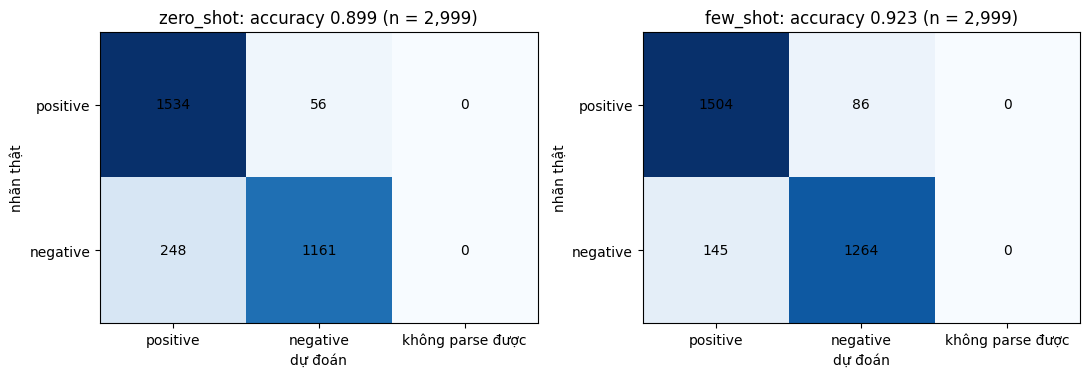

In [54]:
# 10.1 Accuracy + confusion matrix (thêm cột "không parse được")
import math

PART10 = "part10_summary"
log(f"=== PART 10 summary START {now_iso()} ===", part=PART10)


def compute_metrics(res: pd.DataFrame) -> dict:
    """Accuracy, khoảng tin cậy 95%, số câu không parse được."""
    n = len(res)
    acc = float(res["correct"].mean())
    return {"n": n, "accuracy": round(acc, 4), "ci95_half_width": round(1.96 * math.sqrt(acc * (1 - acc) / n), 4),
            "n_unparsed": int(res["pred"].isna().sum()), "unparsed_rate": round(float(res["pred"].isna().mean()), 4)}


def confusion(res: pd.DataFrame) -> pd.DataFrame:
    """Hàng: nhãn thật; cột: dự đoán positive / negative / không parse được."""
    pred = res["pred"].map(LABEL_NAMES).fillna("không parse được")
    true = res["label"].map(LABEL_NAMES)
    return pd.crosstab(true, pred).reindex(index=["positive", "negative"],
                                           columns=["positive", "negative", "không parse được"], fill_value=0)


# Tự kiểm trên ví dụ nhỏ tính tay: 4 câu, đúng 2, 1 câu không parse được
toy = pd.DataFrame({"label": [2, 2, 0, 0], "pred": [2, None, 0, 2]})
toy["correct"] = toy["pred"] == toy["label"]
assert compute_metrics(toy)["accuracy"] == 0.5 and compute_metrics(toy)["n_unparsed"] == 1
assert confusion(toy).loc["negative", "positive"] == 1 and confusion(toy).values.sum() == 4

ICL_METRICS = {"zero_shot": compute_metrics(icl_zero), "few_shot": compute_metrics(icl_few)}
cms = {"zero_shot": confusion(icl_zero), "few_shot": confusion(icl_few)}
for mode in ICL_METRICS:
    print(f"{mode}: {ICL_METRICS[mode]}\n{cms[mode].to_string()}\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (mode, cm) in zip(axes, cms.items()):
    ax.imshow(cm.values, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm.values[i, j]), ha="center", va="center")
    ax.set_xticks(range(3), cm.columns)
    ax.set_yticks(range(2), cm.index)
    ax.set_xlabel("dự đoán")
    ax.set_ylabel("nhãn thật")
    ax.set_title(f"{mode}: accuracy {ICL_METRICS[mode]['accuracy']:.3f} (n = {ICL_METRICS[mode]['n']:,})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix_icl.png", dpi=150)
plt.show()

# Tự kiểm: tổng mỗi hàng = số câu của nhãn đó
for mode, res in [("zero_shot", icl_zero), ("few_shot", icl_few)]:
    assert cms[mode].sum(axis=1).tolist() == [int((res["label"] == 2).sum()), int((res["label"] == 0).sum())]

### 10.2 McNemar: khác biệt có ý nghĩa thống kê không?
- **Mục đích:** hai cách chạy trên **cùng câu**, nên chỉ những câu hai cách cho kết quả **khác nhau** mới nói lên cách nào tốt hơn.
  - b = số câu chỉ zero-shot đúng; c = số câu chỉ few-shot đúng. Nếu H0 đúng thì b ≈ c.
  - `mcnemar(table, exact=True)`: dùng phân phối nhị thức chính xác trên b + c câu. Một phép so sánh nên không cần hiệu chỉnh Bonferroni.
  - Vì sao McNemar: Dietterich (1998), với thuật toán chỉ chạy được một lần trên một tập test, McNemar có sai lầm loại I chấp nhận được.
- **Đầu vào:** `icl_zero`, `icl_few`, `ICL_METRICS`.
- **Đầu ra:** hàm `mcnemar_counts()`; `RESULTS_DIR/icl_metrics.json` (accuracy, CI, không parse được, a, b, c, d, p-value).

| | Few-shot đúng | Few-shot sai |
|---|---|---|
| **Zero-shot đúng** | a | b |
| **Zero-shot sai** | c | d |

Nếu H0 đúng thì mỗi câu "lệch" (b hoặc c) rơi vào hai bên với xác suất như nhau: $b \sim \text{Binomial}(b + c,\ 0.5)$. Kiểm định chính xác hai phía: $p = 2 \cdot P\big(X \le \min(b, c)\big)$, chặn trên ở 1.

In [55]:
# 10.2 McNemar exact
from statsmodels.stats.contingency_tables import mcnemar


def mcnemar_counts(a_correct: pd.Series, b_correct: pd.Series) -> list[list[int]]:
    """Bảng 2×2 theo cặp: [[cả hai đúng, chỉ A đúng], [chỉ B đúng, cả hai sai]]."""
    a, b = a_correct.to_numpy(), b_correct.to_numpy()
    return [[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]]


# Tự kiểm: b = c → p = 1; tổng 4 ô = số câu
assert mcnemar([[5, 3], [3, 5]], exact=True).pvalue == 1.0
table = mcnemar_counts(icl_zero["correct"], icl_few["correct"])
assert sum(map(sum, table)) == len(icl_zero)

test_res = mcnemar(table, exact=True)
(a_, b_), (c_, d_) = table
ICL_METRICS["mcnemar"] = {"a_both_correct": a_, "b_only_zero_correct": b_, "c_only_few_correct": c_,
                          "d_both_wrong": d_, "p_value": float(test_res.pvalue), "exact": True}
ICL_METRICS["setup"] = {"run_id": RUN_ID, "model": MODEL_INSTRUCT, "revision": MODEL_REVISION, "dtype": ENV["dtype"],
                        "template": CHOSEN_TEMPLATE, "n_fewshot": len(FEWSHOT), "max_new_tokens": ICL_MAX_NEW_TOKENS,
                        "do_sample": False, "seed": SEED, "n_test": len(icl_zero)}
save_json(ICL_METRICS, RESULTS_DIR / "icl_metrics.json")

print(f"Bảng theo cặp: cả hai đúng a = {a_}, chỉ zero-shot đúng b = {b_}, chỉ few-shot đúng c = {c_}, cả hai sai d = {d_}")
print(f"McNemar exact: p = {test_res.pvalue:.4g} → "
      f"{'khác biệt có ý nghĩa ở mức 0.05' if test_res.pvalue < 0.05 else 'chưa đủ bằng chứng khác biệt ở mức 0.05'}")
log(f"McNemar: a={a_}, b={b_}, c={c_}, d={d_}, p={test_res.pvalue:.4g}", part=PART10)

Bảng theo cặp: cả hai đúng a = 2648, chỉ zero-shot đúng b = 47, chỉ few-shot đúng c = 120, cả hai sai d = 184
McNemar exact: p = 1.503e-08 → khác biệt có ý nghĩa ở mức 0.05
McNemar: a=2648, b=47, c=120, d=184, p=1.503e-08


### 10.3 Mẫu phân tích lỗi
- **Mục đích:** lấy ngẫu nhiên `N_ERROR_SAMPLE` câu few-shot sai (seed 42) để đọc và gán nhóm lỗi. **Nhóm lỗi ghi sẵn trước khi đọc output**, để tránh chấm theo cảm tính:
  - (a) không parse được;
  - (b) nhãn gốc có vẻ sai;
  - (c) câu vừa khen vừa chê;
  - (d) ý ngầm (góp ý, phàn nàn gián tiếp);
  - (e) model sai rõ ràng.
- Nhóm (a) gán tự động. Các nhóm khác do Toàn đọc từng câu rồi gán trong `MANUAL_ERROR_GROUPS` (khoá `row_id`).
- **Đầu vào:** `icl_few`.
- **Đầu ra:** `RESULTS_DIR/error_analysis_sample.csv` (`row_id, sentence, label, output, pred, error_group, note`); bảng đếm theo nhóm.

In [56]:
# 10.3 Lấy mẫu câu few-shot sai, gán nhóm lỗi
ERROR_GROUPS = {"a": "không parse được", "b": "nhãn gốc có vẻ sai", "c": "vừa khen vừa chê",
                "d": "ý ngầm (góp ý, phàn nàn gián tiếp)", "e": "model sai rõ ràng"}
MANUAL_ERROR_GROUPS: dict[int, tuple[str, str]] = {   # row_id: (mã nhóm "b".."e", lý do ngắn); Toàn duyệt 19/11
    2625: ("d", "góp ý 'nên cập nhật'"), 2968: ("d", "góp ý 'nên thực hành nghe nói'"),
    2635: ("e", "câu ngắn, kể hoạt động; nhãn positive hợp lý"), 138: ("e", "'rất dễ tính' là khen"),
    2234: ("d", "góp ý 'mong thầy nên'"), 356: ("d", "góp ý 'giảm lý thuyết, tăng thực hành'"),
    1494: ("d", "góp ý 'nên bám sát thực tế'"), 1649: ("d", "góp ý 'cần phải giảng'"),
    1086: ("d", "góp ý 'cung cấp thêm'"), 1420: ("d", "góp ý 'nên hướng dẫn'"),
    1695: ("c", "'viết bài nhiều, học ngoài giờ nhiều': vừa như khen chăm, vừa như than nhiều bài"), 718: ("d", "góp ý 'nhiều hơn'"),
    1427: ("d", "góp ý 'nên đưa môn học'"), 2748: ("d", "góp ý 'nên bổ sung hình vẽ'"),
    2486: ("b", "góp ý nhưng gán positive, ngược quy ước góp ý = negative"), 1176: ("c", "'khó hiểu nhưng rất kỹ'"),
    2269: ("c", "'rõ ràng … nhưng thiên về lý thuyết'"), 670: ("d", "phàn nàn ngầm về nắng chiếu"),
    1579: ("d", "góp ý 'nên cho đề thi thử'"), 667: ("e", "'rất dề hiểu' (gõ sai 'dễ') là khen"),
    1584: ("b", "'cần thiết và thiết thực' là khen nhưng gán negative"), 1865: ("d", "góp ý 'nên chốt lại'"),
    1686: ("e", "'kỹ lưỡng' là khen"), 541: ("d", "góp ý 'nên cho giải bài tập'"),
    721: ("d", "góp ý 'nên nhiệt tình hơn'"), 184: ("d", "góp ý 'cần nhiệt tình hơn'"),
    2993: ("d", "góp ý 'cần cho thực hành'"), 2947: ("d", "góp ý 'nên trang bị'"),
    2282: ("d", "góp ý 'cần áp dụng trò chơi'"), 1886: ("c", "'dạy chậm' nhưng 'dễ tiếp thu'"),
}

wrong = icl_few[~icl_few["correct"]]
err = wrong.sample(min(N_ERROR_SAMPLE, len(wrong)), random_state=SEED).copy()
err["label"] = err["label"].map(LABEL_NAMES)
err["pred"] = err["pred"].map(LABEL_NAMES)
err["error_group"] = err["pred"].isna().map({True: ERROR_GROUPS["a"], False: "chưa gán"})
err["note"] = ""
for rid, (g, note) in MANUAL_ERROR_GROUPS.items():
    err.loc[err["row_id"] == rid, ["error_group", "note"]] = [ERROR_GROUPS[g], note]
err[["row_id", "sentence", "label", "output", "pred", "error_group", "note"]].to_csv(
    RESULTS_DIR / "error_analysis_sample.csv", index=False, encoding="utf-8")

print(f"few-shot sai {len(wrong):,} câu; lấy {len(err)} câu để phân tích")
print(err["error_group"].value_counts().to_string())
print(err[["sentence", "label", "output"]].head(10).to_string(index=False))
log(f"phân tích lỗi: {len(err)}/{len(wrong)} câu sai few-shot | {err['error_group'].value_counts().to_dict()}", part=PART10)

# Trên TOÀN BỘ câu sai: bao nhiêu câu negative bị đoán positive là câu góp ý (có từ "nên", "cần", "mong", "thêm", "hơn")
SUGGEST_RE = r"\b(?:nên|cần|mong|thêm|hơn)\b"
for mode, res in [("zero_shot", icl_zero), ("few_shot", icl_few)]:
    neg_as_pos = res[(res["label"] == 0) & (res["pred"] == 2)]
    n_sug = int(neg_as_pos["sentence"].map(lambda s: bool(re.search(SUGGEST_RE, s))).sum())
    log(f"{mode}: negative bị đoán positive {len(neg_as_pos)} câu, trong đó câu góp ý {n_sug} ({n_sug / max(len(neg_as_pos), 1):.0%})",
        part=PART10)

assert err["row_id"].isin(icl_few["row_id"]).all() and not err["row_id"].duplicated().any()

few-shot sai 231 câu; lấy 30 câu để phân tích
error_group
ý ngầm (góp ý, phàn nàn gián tiếp)    20
model sai rõ ràng                      4
vừa khen vừa chê                       4
nhãn gốc có vẻ sai                     2
                                                                                                                              sentence    label            output
                                                                 môn học này nên thường xuyên cập nhật mới , phù hợp với lại thực tế . negative Cảm xúc: tích cực
đối với môn anh văn tránh sa đà vào chỉ luyện tập kỹ năng về đọc và viết mà nên thực hành kỹ năng nghe nói nhiều hơn và hiệu quả hơn . negative Cảm xúc: tích cực
                                                                                                         cho thảo luận , làm seminar . positive Cảm xúc: tiêu cực
                                                                                                                    thầy rất dễ tí

### 10.4 Bảng tổng hợp mọi phần và kết thúc lần chạy
- **Mục đích:** một bảng cho slide 13, **đọc từ file kết quả** của lần chạy này, không chép số tay.
- **Đầu vào:** các file trong `RESULTS_DIR`.
- **Đầu ra:** `RESULTS_DIR/summary_table.csv` (`muc, thi_nghiem, ket_qua, file`); dòng `RUN END` trong `run.log`.

In [57]:
# 10.4 Bảng tổng hợp đọc từ file kết quả
R = RESULTS_DIR
tc = pd.read_csv(R / "token_counts.csv")
ls_ = pd.read_csv(R / "loss_summary.csv")
bvi = pd.read_csv(R / "base_vs_instruct.csv")
dec = pd.read_csv(R / "decoding_samples.csv")
icl = json.loads((R / "icl_metrics.json").read_text(encoding="utf-8"))
rag = pd.read_csv(R / "rag_results.csv")
hal = pd.read_csv(R / "hallucination_results.csv")
fict = pd.read_csv(R / "hallucination_fictitious.csv")
fict_j = pd.concat([fict["judged_A"], fict["judged_B"]])


def tok_count(lang: str, name: str) -> int:
    return int(tc[(tc["lang"] == lang) & (tc["tokenizer"] == name)]["n_tokens"].iloc[0])


def count_judged(s: pd.Series) -> str:
    """Đếm 'đúng / sai / từ chối' để không ai đọc nhầm 0 đúng thành 'sai hết'."""
    return f"{(s == 'Đúng').sum()} đúng / {(s == 'Sai').sum()} sai / {(s == 'Từ chối').sum()} từ chối"


rag_ans = rag[~rag["is_impossible"]].groupby("mode")["judged"].apply(count_judged)
rag_imp = rag[rag["is_impossible"] & (rag["mode"] == "rag")]["judged"]
bvi_ok = bvi.groupby("model")["judged"].apply(lambda s: f"{(s == 'đạt').sum()}/{len(s)}")
summary_rows = [
    ("1", "4 tác vụ, 1 model", "xem tasks_outputs.csv", "tasks_outputs.csv"),
    ("2", "Top-5 token tiếp theo", "xem top5_next_tokens.csv", "top5_next_tokens.csv"),
    ("3", "Số token câu Việt / Anh", f"vi: Qwen {tok_count('vi', 'qwen2.5')} / GPT-2 {tok_count('vi', 'gpt2')}; "
                                     f"en: Qwen {tok_count('en', 'qwen2.5')} / GPT-2 {tok_count('en', 'gpt2')}", "token_counts.csv"),
    ("4", "Cross-entropy câu ví dụ", "; ".join(f"{s}: loss {l:.3f}" for s, l in zip(ls_["sentence_id"], ls_["loss_mean"])),
     "loss_summary.csv"),
    ("5", "Base vs Instruct (đạt follow_rule)", f"instruct {bvi_ok.get('instruct')}, base {bvi_ok.get('base')}",
     "base_vs_instruct.csv"),
    ("6", "Số output khác nhau / 3 lần", str(dec.groupby("config", sort=False)["output"].nunique().to_dict()),
     "decoding_samples.csv"),
    ("7, 10", "Zero-shot vs few-shot", f"accuracy {icl['zero_shot']['accuracy']:.3f} vs {icl['few_shot']['accuracy']:.3f} "
                                       f"(n = {icl['zero_shot']['n']:,}); McNemar p = {icl['mcnemar']['p_value']:.3g}",
     "icl_metrics.json"),
    ("8", "Không RAG vs có RAG", f"câu có đáp án: no_rag {rag_ans.get('no_rag')} | rag {rag_ans.get('rag')}; "
                                  f"câu không có đáp án: rag trả lời bừa {(rag_imp == 'Sai').sum()}/{len(rag_imp)}",
     "rag_results.csv"),
    ("9", "Hỏi không tài liệu: sai (A / B)", f"{(hal['judged_A'] != 'Đúng').sum()} / {(hal['judged_B'] != 'Đúng').sum()} "
                                             f"trên {len(hal)} câu; thực thể không tồn tại: bịa {(fict_j == 'Sai').sum()}/{len(fict_j)} lần hỏi",
     "hallucination_results.csv, hallucination_fictitious.csv"),
]
summary_df = pd.DataFrame(summary_rows, columns=["muc", "thi_nghiem", "ket_qua", "file"])
summary_df.to_csv(R / "summary_table.csv", index=False, encoding="utf-8")
print(summary_df.to_string(index=False))

log(f"=== PART 10 summary END {now_iso()} ===", part=PART10)
log(f"[{PART10}] OK {now_iso()} → results/icl_metrics.json, figures/confusion_matrix_icl.png, "
    f"results/error_analysis_sample.csv, results/summary_table.csv")
RUN_END = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh"))
log(f"=== RUN END {RUN_END.isoformat(timespec='seconds')} | tổng thời gian {(RUN_END - RUN_START).total_seconds() / 60:.1f} phút ===")

  muc                         thi_nghiem                                                                                                                       ket_qua                                                    file
    1                  4 tác vụ, 1 model                                                                                                         xem tasks_outputs.csv                                       tasks_outputs.csv
    2              Top-5 token tiếp theo                                                                                                      xem top5_next_tokens.csv                                    top5_next_tokens.csv
    3            Số token câu Việt / Anh                                                                                   vi: Qwen 8 / GPT-2 22; en: Qwen 7 / GPT-2 7                                        token_counts.csv
    4            Cross-entropy câu ví dụ                                                                    

**Phân tích** (normal run `20261119_150356_normal`):
- Thiết lập: Qwen2.5-1.5B-Instruct (float16, Kaggle T4), UIT-VSFC test 2,999 câu (2 nhãn: 1,590 positive / 1,409 negative), mẫu prompt `vi_nhan_vi` chọn trên validation, greedy, `max_new_tokens` 10, 4 ví dụ few-shot từ train, seed 42. Chỉ đổi một biến: có ví dụ hay không.
- Kết quả: zero-shot 89.86% (±1.08), few-shot 92.30% (±0.95); không parse được 0 / 0. McNemar exact: b = 47 (chỉ zero đúng), c = 120 (chỉ few đúng), p = 1.5e-08 < 0.05 → few-shot tốt hơn, khác biệt có ý nghĩa thống kê.
- Confusion matrix: zero-shot đoán positive cho 248 câu negative, đoán negative cho 56 câu positive; few-shot còn 145 và 86. Few-shot sửa chủ yếu lỗi "negative → positive", đổi lại tăng nhẹ lỗi ngược.
- Phân tích lỗi (30 câu few-shot sai, nhóm ghi sẵn trước khi đọc): (d) ý ngầm 20 (góp ý "nên…/cần…" bị gán negative), (c) vừa khen vừa chê 4, (e) model sai rõ 4, (b) nhãn gốc có vẻ sai 2, (a) không parse được 0. Trên toàn bộ câu sai: câu negative bị đoán positive có 189/248 (76%, zero-shot) và 117/145 (81%, few-shot) là câu góp ý (có "nên", "cần", "mong", "thêm", "hơn"; log `part10_summary.log`).
- Giới hạn: 1 model 1.5B; 1 bộ dữ liệu, 1 tác vụ; 1 bộ ví dụ few-shot; mỗi cấu hình chạy 1 lần. Không suy rộng sang "LLM nói chung".

In [58]:
import shutil
shutil.make_archive("/kaggle/working/outputs", "zip", "/kaggle/working", "outputs")  # nén thư mục outputs/


'/kaggle/working/outputs.zip'

### Tóm tắt và kết luận chính
Số liệu từ lần chạy chính thức `20261119_150356_normal` (Kaggle, GPU T4, float16, seed 42); bảng tổng hợp ở `results/summary_table.csv`.

1. **Một model, nhiều tác vụ (mục 1):** chỉ đổi prompt, Qwen2.5-1.5B-Instruct làm được hỏi đáp, tóm tắt, dịch, sinh mã (đạt 4/4 theo thang chấm ghi trước khi chạy).
2. **Đầu ra là phân phối xác suất (mục 2, 6):** sau "Hôm nay trời rất", token " đẹp" có P = 0.788. Causal mask có tác dụng thật: trọng số attention phía trên đường chéo bằng 0. Sinh văn bản là lặp lại "đoán 1 token, nối vào, đoán tiếp"; greedy lặp lại được, temperature 1.5 ra chuỗi vô nghĩa.
3. **Token phụ thuộc tokenizer (mục 3):** cùng câu tiếng Việt, Qwen 8 token, GPT-2 22 token; câu tiếng Anh 7 và 7.
4. **Model đã học quy luật ngôn ngữ (mục 4):** loss câu đúng 2.985 (perplexity 19.8), câu xáo trộn 6.701, đoán bừa 11.931.
5. **Post-training đổi hành vi (mục 5):** cùng prompt, bản base đạt 0/4 (viết tiếp như trang web), bản Instruct đạt 4/4.
6. **Few-shot giúp có ý nghĩa thống kê (mục 7, 10):** accuracy 89.86% → 92.30% trên 2,999 câu; McNemar exact p = 1.5e-08. Lỗi chính là câu góp ý ("nên…", "cần…") mà UIT-VSFC gán negative; 4 ví dụ cho model thấy quy ước này.
7. **RAG bổ sung tri thức lúc hỏi (mục 8):** câu có đáp án đúng 0/15 → 10/15; nhưng với câu tài liệu không có đáp án, RAG trả lời bịa 2/3.
8. **Hallucination (mục 9):** không tài liệu, không cho từ chối, model sai 12/15 mà vẫn trả lời tự tin; hỏi về thực thể không tồn tại thì bịa 5/6 lần, không lần nào chỉ ra tiền đề sai; kiểm chứng bằng đối chiếu nguồn, hỏi lại cách khác, hoặc dùng RAG.

**Giới hạn:** 1 model 1.5B; mỗi thí nghiệm một bộ dữ liệu, một lần chạy; chấm tay do một người đọc lại; không suy rộng sang "LLM nói chung".

**Không làm:** fine-tune
; demo thiên lệch và giới hạn ngữ cảnh (trình bày bằng lời ở mục 9); chạy nhiều seed; dùng LLM khác để chấm.